In [2]:
!pip install scipy
!pip install xgboost
!pip install lightgbm
!pip install catboost
!pip install shap
!pip install lime

In [3]:
import numpy as np
import pandas as pd
from scipy.io import loadmat
from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

In [4]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/prksh830/nasa-dtec/B0005.mat
/kaggle/input/datasets/prksh830/nasa-dtec/B0006.mat
/kaggle/input/datasets/prksh830/nasa-dtec/B0007.mat
/kaggle/input/datasets/prksh830/nasa-dtec/B0018.mat
/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Extracted.csv
/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv
/kaggle/input/datasets/prksh830/nasa-dtec/README.txt


In [5]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/prksh830/nasa-dtec/B0005.mat
/kaggle/input/datasets/prksh830/nasa-dtec/B0006.mat
/kaggle/input/datasets/prksh830/nasa-dtec/B0007.mat
/kaggle/input/datasets/prksh830/nasa-dtec/B0018.mat
/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Extracted.csv
/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv
/kaggle/input/datasets/prksh830/nasa-dtec/README.txt


In [8]:
print("FEATURES =", FEATURES)
print("BATTERY_COL =", BATTERY_COL)

print("\n=== Relevant notebook variables ===")
for name, obj in list(globals().items()):
    if any(term in name.lower() for term in [
        "battery", "soh", "feature", "dataset", "data", "lobo",
        "csv", "train", "test", "df"
    ]):
        if not name.startswith("_"):
            try:
                print(
                    f"{name}: type={type(obj).__name__}, "
                    f"shape={getattr(obj, 'shape', None)}"
                )
            except Exception:
                print(f"{name}: type={type(obj).__name__}")

FEATURES = ['AvgVoltage', 'MaxVoltage', 'AvgCurrent', 'AvgTemp', 'Duration', 'Cycle', 'DI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI_v2']
BATTERY_COL = Battery

=== Relevant notebook variables ===
FEATURES: type=list, shape=None
BATTERY_COL: type=str, shape=None


In [12]:
from pathlib import Path

search_roots = [
    Path.cwd(),
    Path("/kaggle/input"),
    Path("/content"),
]

print("=== Candidate battery dataset files ===")

seen = set()

for root in search_roots:
    if not root.exists():
        continue

    try:
        for path in root.rglob("*"):
            if (
                path.is_file()
                and path.suffix.lower() in {".csv", ".parquet", ".xlsx"}
                and any(
                    term in path.name.lower()
                    for term in ["battery", "soh", "dtec", "b0005", "b0006",
                                 "b0007", "b0018", "master", "feature"]
                )
            ):
                resolved = str(path.resolve())
                if resolved not in seen:
                    seen.add(resolved)
                    print(resolved)
    except (PermissionError, OSError):
        pass

if not seen:
    print("No matching files found in the searched directories.")

=== Candidate battery dataset files ===
/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Extracted.csv
/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv


In [13]:
import pandas as pd
from pathlib import Path

EXTRACTED_PATH = Path(
    "/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Extracted.csv"
)

MASTER_PATH = Path(
    "/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv"
)

for file_path in [EXTRACTED_PATH, MASTER_PATH]:
    print("\n" + "=" * 80)
    print("FILE:", file_path.name)

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))

    battery_candidates = [
        c for c in df.columns
        if any(term in c.lower() for term in ["battery", "cell", "unit", "id"])
    ]

    target_candidates = [
        c for c in df.columns
        if any(term in c.lower() for term in ["soh", "health", "capacity", "target"])
    ]

    print("\nPossible battery identifier columns:", battery_candidates)
    print("Possible target columns:", target_candidates)

    for col in battery_candidates:
        print(f"\nUnique values in {col}:")
        print(df[col].value_counts(dropna=False).head(15))


FILE: NASA_Battery_Extracted.csv
Shape: (636, 14)
Columns: ['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration']

First 3 rows:


,Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,MaxTemp,MinTemp,StdTemp,Duration
0,B0005,1,1.856487,3.529829,4.191492,2.612467,0.235957,-1.818702,0.593546,32.572328,38.982181,24.325993,3.486920,3690.234
1,B0005,2,1.846327,3.537320,4.189773,2.587209,0.234765,-1.817560,0.595180,32.725235,39.033398,24.685948,3.426734,3672.344
2,B0005,3,1.835349,3.543737,4.188187,2.651917,0.227525,-1.816487,0.596498,32.642862,38.818797,24.734266,3.379475,3651.641



Possible battery identifier columns: ['Battery']
Possible target columns: ['Capacity']

Unique values in Battery:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64

FILE: NASA_Battery_Master.csv
Shape: (636, 23)
Columns: ['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']

First 3 rows:


,Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,...,Duration,SOH,RUL,DI,CFI,TSI,VHI,TGI,VSI,DTHI
0,B0005,1,1.856487,3.529829,4.191492,2.612467,0.235957,-1.818702,0.593546,32.572328,...,3690.234,100.000000,167,0.005952,0.000000,0.944386,1.000000,14.656188,0.809090,0.219002
1,B0005,2,1.846327,3.537320,4.189773,2.587209,0.234765,-1.817560,0.595180,32.725235,...,3672.344,99.452721,166,0.011905,0.005473,0.948819,1.002122,14.347450,0.809871,0.222309
2,B0005,3,1.835349,3.543737,4.188187,2.651917,0.227525,-1.816487,0.596498,32.642862,...,3651.641,98.861386,165,0.017857,0.011386,0.946431,1.003940,14.084531,0.814647,0.223809



Possible battery identifier columns: ['Battery']
Possible target columns: ['Capacity', 'SOH']

Unique values in Battery:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64


In [14]:

import pandas as pd
import numpy as np

MASTER_PATH = (
    "/kaggle/input/datasets/prksh830/nasa-dtec/"
    "NASA_Battery_Master.csv"
)

df_master = pd.read_csv(MASTER_PATH)

print("Dataset shape:", df_master.shape)
print("Columns:", df_master.columns.tolist())

print("\nBattery-wise record counts:")
print(df_master.groupby("Battery").size())

print("\nCycle ordering check:")
for battery, group in df_master.groupby("Battery", sort=False):
    cycles = group["Cycle"].to_numpy()
    print(
        battery,
        "| rows:", len(group),
        "| cycles strictly increasing:",
        bool(np.all(np.diff(cycles) > 0))
    )

print("\nMissing values in relevant columns:")
check_cols = [
    "Battery", "Cycle", "SOH", "Capacity",
    "AvgVoltage", "MaxVoltage", "AvgCurrent",
    "AvgTemp", "Duration", "DI", "TSI",
    "VHI", "TGI", "VSI", "DTHI"
]
print(df_master[check_cols].isna().sum())

print("\nDTHI_v2 already available:", "DTHI_v2" in df_master.columns)
print("DTHI available:", "DTHI" in df_master.columns)


Dataset shape: (636, 23)
Columns: ['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']

Battery-wise record counts:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64

Cycle ordering check:
B0005 | rows: 168 | cycles strictly increasing: True
B0006 | rows: 168 | cycles strictly increasing: True
B0007 | rows: 168 | cycles strictly increasing: True
B0018 | rows: 132 | cycles strictly increasing: True

Missing values in relevant columns:
Battery       0
Cycle         0
SOH           0
Capacity      0
AvgVoltage    0
MaxVoltage    0
AvgCurrent    0
AvgTemp       0
Duration      0
DI            0
TSI           0
VHI           0
TGI           0
VSI           0
DTHI          0
dtype: int64

DTHI_v2 already available: False
DTHI available: True


In [9]:
import pandas as pd

print("=== Loaded DataFrames ===")
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: shape={obj.shape}")
        print("Columns:", obj.columns.tolist())
        print(obj.head(2))

=== Loaded DataFrames ===


In [10]:

# Find DataFrames already created in the notebook
import pandas as pd

print("=== Existing DataFrames ===")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame name: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

print("\n=== Relevant variables ===")

for name in list(globals().keys()):
    if any(term in name.lower() for term in
           ["battery", "soh", "feature", "dataset", "data", "lobo"]):
        obj = globals()[name]
        if not isinstance(obj, type) and not callable(obj):
            print(name, "->", type(obj).__name__)


=== Existing DataFrames ===

=== Relevant variables ===
FEATURES -> list
BATTERY_COL -> str


In [16]:

import pandas as pd
import numpy as np

# Load the NASA battery master dataset
MASTER_PATH = (
    "/kaggle/input/datasets/prksh830/nasa-dtec/"
    "NASA_Battery_Master.csv"
)

master_df = pd.read_csv(MASTER_PATH)

# Define experiment settings
BATTERY_COL = "Battery"
TARGET_COL = "SOH"

FEATURES = [
    "AvgVoltage",
    "MaxVoltage",
    "AvgCurrent",
    "AvgTemp",
    "Duration",
    "Cycle",
    "DI",
    "TSI",
    "VHI",
    "TGI",
    "VSI"
]

BATTERIES = ["B0005", "B0006", "B0007", "B0018"]

# Validate the loaded dataset
required_cols = [BATTERY_COL, TARGET_COL] + FEATURES
missing_cols = [
    col for col in required_cols
    if col not in master_df.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

master_df = (
    master_df[master_df[BATTERY_COL].isin(BATTERIES)]
    .sort_values([BATTERY_COL, "Cycle"])
    .reset_index(drop=True)
)

print("master_df defined successfully.")
print("Shape:", master_df.shape)
print("Batteries:", sorted(master_df[BATTERY_COL].unique()))
print("Target:", TARGET_COL)
print("Features:", FEATURES)
print("\nBattery-wise record counts:")
print(master_df[BATTERY_COL].value_counts().sort_index())


master_df defined successfully.
Shape: (636, 23)
Batteries: ['B0005', 'B0006', 'B0007', 'B0018']
Target: SOH
Features: ['AvgVoltage', 'MaxVoltage', 'AvgCurrent', 'AvgTemp', 'Duration', 'Cycle', 'DI', 'TSI', 'VHI', 'TGI', 'VSI']

Battery-wise record counts:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64


In [17]:
# ============================================================
# SOH BASELINE: FEATURE AUDIT AND LEAVE-ONE-BATTERY-OUT VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    ExtraTreesRegressor
)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the master_df already loaded by your notebook.
df = master_df.copy()

# Check required columns
baseline_features = [
    "AvgVoltage",
    "MaxVoltage",
    "MinVoltage",
    "StdVoltage",
    "AvgCurrent",
    "StdCurrent",
    "AvgTemp",
    "MaxTemp",
    "MinTemp",
    "StdTemp",
    "Cycle",
]

required = baseline_features + ["Battery", "SOH"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Use the three development batteries only.
dev_df = df[df["Battery"].isin(
    ["B0005", "B0006", "B0007"]
)].copy()

dev_df = dev_df.dropna(subset=["SOH", "Battery"])

X = dev_df[baseline_features].replace(
    [np.inf, -np.inf], np.nan
)
y = dev_df["SOH"].astype(float)
groups = dev_df["Battery"]

print("Development dataset shape:", dev_df.shape)
print("\nSamples per battery:")
print(dev_df.groupby("Battery").size())

print("\nFeature missing values:")
print(X.isna().sum())

print("\nFeatures used:")
print(baseline_features)

# Leave one complete battery out in each fold.
logo = LeaveOneGroupOut()

models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression()
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    ),
    "Extra Trees": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    ),
    "HistGradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(
            random_state=42
        )
    ),
}

results = []

for model_name, model in models.items():
    for train_idx, val_idx in logo.split(X, y, groups):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        held_out_battery = groups.iloc[val_idx].iloc[0]

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        results.append({
            "Model": model_name,
            "Held_Out_Battery": held_out_battery,
            "MAE": mean_absolute_error(y_val, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_val, predictions)
            ),
            "R2": r2_score(y_val, predictions),
        })

fold_results = pd.DataFrame(results)

print("\n=== Per-battery validation results ===")
print(fold_results.round(4).to_string(index=False))

summary = (
    fold_results
    .groupby("Model")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .round(4)
)

print("\n=== Mean and standard deviation across held-out batteries ===")
print(summary)

Development dataset shape: (504, 23)

Samples per battery:
Battery
B0005    168
B0006    168
B0007    168
dtype: int64

Feature missing values:
AvgVoltage    0
MaxVoltage    0
MinVoltage    0
StdVoltage    0
AvgCurrent    0
StdCurrent    0
AvgTemp       0
MaxTemp       0
MinTemp       0
StdTemp       0
Cycle         0
dtype: int64

Features used:
['AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Cycle']

=== Per-battery validation results ===
               Model Held_Out_Battery    MAE   RMSE     R2
   Linear Regression            B0005 2.7388 3.0162 0.9130
   Linear Regression            B0006 5.6611 6.0263 0.7617
   Linear Regression            B0007 4.4917 4.9604 0.6583
       Random Forest            B0005 2.6906 3.0136 0.9132
       Random Forest            B0006 5.1951 5.8890 0.7725
       Random Forest            B0007 1.3516 1.9304 0.9482
         Extra Trees            B0005 1.4380 2.1060 0.9576
 

In [18]:
import pandas as pd
import numpy as np

correlation_rows = []

for battery, group in dev_df.groupby("Battery"):
    corr = (
        group[baseline_features + ["SOH"]]
        .corr(numeric_only=True)["SOH"]
        .drop("SOH")
    )

    for feature, value in corr.items():
        correlation_rows.append({
            "Battery": battery,
            "Feature": feature,
            "Correlation": value
        })

correlation_df = pd.DataFrame(correlation_rows)

stability = (
    correlation_df
    .groupby("Feature")["Correlation"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean", key=lambda s: s.abs(), ascending=False)
    .round(3)
)

display(stability)

,mean,std,min,max
Feature,,,,
Cycle,-0.986,0.004,-0.988,-0.982
AvgVoltage,0.970,0.011,0.961,0.982
StdTemp,-0.955,0.030,-0.989,-0.932
AvgCurrent,-0.911,0.092,-0.989,-0.809
StdCurrent,-0.894,0.103,-0.983,-0.781
MaxTemp,-0.845,0.093,-0.935,-0.749
AvgTemp,-0.740,0.132,-0.823,-0.588
StdVoltage,-0.494,0.201,-0.697,-0.296
MinVoltage,-0.431,0.100,-0.490,-0.315


In [19]:
# Compare feature distributions across development batteries

audit_features = baseline_features + ["SOH"]

battery_summary = (
    dev_df.groupby("Battery")[audit_features]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

display(battery_summary)

# Correlation of each feature with SOH, separately by battery
for battery, group in dev_df.groupby("Battery"):
    print(f"\n{battery}: feature correlation with SOH")

    correlations = (
        group[baseline_features + ["SOH"]]
        .corr(numeric_only=True)["SOH"]
        .drop("SOH")
        .sort_values(key=abs, ascending=False)
    )

    print(correlations.round(3))

AvgVoltage                      MaxVoltage                       \
              mean    std    min    max       mean    std    min    max   
Battery                                                                   
B0005        3.517  0.033  3.464  3.564      4.196  0.005  4.185  4.223   
B0006        3.464  0.060  3.404  3.574      4.182  0.006  4.158  4.223   
B0007        3.518  0.035  3.458  3.572      4.201  0.004  4.189  4.233   

        MinVoltage         ... StdTemp        Cycle                      SOH  \
              mean    std  ...     min    max  mean     std min  max    mean   
Battery                    ...                                                 
B0005        2.649  0.049  ...   3.331  4.453  84.5  48.642   1  168  84.703   
B0006        2.416  0.068  ...   3.104  4.528  84.5  48.642   1  168  76.000   
B0007        2.080  0.096  ...   3.253  4.443  84.5  48.642   1  168  86.958   

                                
            std     min    max  
Battery                         
B0005    10.257  69.349  100.0  
B0006    12.383  56.689  100.0  
B0007     8.511  74.057  100.0  

[3 rows x 48 columns]


B0005: feature correlation with SOH
StdTemp      -0.989
Cycle        -0.988
AvgVoltage    0.982
MaxTemp      -0.935
AvgCurrent   -0.933
StdCurrent   -0.918
AvgTemp      -0.810
MinVoltage   -0.487
StdVoltage   -0.296
MaxVoltage   -0.222
MinTemp       0.036
Name: SOH, dtype: float64

B0006: feature correlation with SOH
AvgCurrent   -0.989
StdCurrent   -0.983
Cycle        -0.982
AvgVoltage    0.965
StdTemp      -0.943
MaxTemp      -0.850
AvgTemp      -0.823
StdVoltage   -0.697
MinVoltage   -0.490
MinTemp       0.121
MaxVoltage    0.053
Name: SOH, dtype: float64

B0007: feature correlation with SOH
Cycle        -0.988
AvgVoltage    0.961
StdTemp      -0.932
AvgCurrent   -0.809
StdCurrent   -0.781
MaxTemp      -0.749
AvgTemp      -0.588
StdVoltage   -0.488
MinVoltage   -0.315
MaxVoltage    0.030
MinTemp      -0.002
Name: SOH, dtype: float64


In [20]:
DATA_PATH = "/kaggle/input/datasets/prksh830/nasabatterydataset"

In [21]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if any(f.endswith(".mat") for f in files):
        print("ACTUAL DATASET PATH:", root)
        print("MAT FILES:", [f for f in files if f.endswith(".mat")])

ACTUAL DATASET PATH: /kaggle/input/datasets/prksh830/nasa-dtec
MAT FILES: ['B0005.mat', 'B0006.mat', 'B0007.mat', 'B0018.mat']


In [22]:
def extract_discharge_features(mat_file, battery_name):

    mat = loadmat(mat_file)

    battery = mat[battery_name]

    cycles = battery[0,0]['cycle'][0]

    data_rows = []

    discharge_cycle = 0

    for cycle in cycles:

        cycle_type = cycle['type'][0]

        if cycle_type != 'discharge':
            continue

        discharge_cycle += 1

        data = cycle['data'][0,0]

        voltage = data['Voltage_measured'][0]
        current = data['Current_measured'][0]
        temp = data['Temperature_measured'][0]
        time = data['Time'][0]

        capacity = float(data['Capacity'][0][0])

        row = {

            "Battery": battery_name,
            "Cycle": discharge_cycle,

            "Capacity": capacity,

            "AvgVoltage": np.mean(voltage),
            "MaxVoltage": np.max(voltage),
            "MinVoltage": np.min(voltage),
            "StdVoltage": np.std(voltage),

            "AvgCurrent": np.mean(current),
            "StdCurrent": np.std(current),

            "AvgTemp": np.mean(temp),
            "MaxTemp": np.max(temp),
            "MinTemp": np.min(temp),
            "StdTemp": np.std(temp),

            "Duration": np.max(time)

        }

        data_rows.append(row)

    return pd.DataFrame(data_rows)

In [23]:
import os

print("Available Kaggle input directories:")
print(os.listdir("/kaggle/input"))

for root, dirs, files in os.walk("/kaggle/input"):
    if "B0005.mat" in files:
        DATA_PATH = root
        print("\nCorrect DATA_PATH:", DATA_PATH)
        print("Battery files found:", [
            f for f in files
            if f in ["B0005.mat", "B0006.mat", "B0007.mat", "B0018.mat"]
        ])
        break
else:
    print("\nB0005.mat was not found under /kaggle/input.")
    print("Check that the NASA battery dataset is attached to this notebook.")

Available Kaggle input directories:
['datasets']

Correct DATA_PATH: /kaggle/input/datasets/prksh830/nasa-dtec
Battery files found: ['B0005.mat', 'B0006.mat', 'B0007.mat', 'B0018.mat']


In [24]:
B0005 = extract_discharge_features(
    f"{DATA_PATH}/B0005.mat",
    "B0005"
)

B0006 = extract_discharge_features(
    f"{DATA_PATH}/B0006.mat",
    "B0006"
)

B0007 = extract_discharge_features(
    f"{DATA_PATH}/B0007.mat",
    "B0007"
)

B0018 = extract_discharge_features(
    f"{DATA_PATH}/B0018.mat",
    "B0018"
)

In [25]:
from scipy.io import loadmat
import numpy as np
import os

for battery_name in ["B0005", "B0006", "B0007", "B0018"]:
    mat_file = os.path.join(DATA_PATH, f"{battery_name}.mat")
    mat = loadmat(mat_file)
    cycles = mat[battery_name][0, 0]["cycle"][0]

    durations = []

    for cycle in cycles:
        if cycle["type"][0] != "discharge":
            continue

        data = cycle["data"][0, 0]
        time = np.asarray(data["Time"]).ravel().astype(float)
        durations.append(float(time.max() - time.min()))

    print(f"\n{battery_name}")
    print("First 10 raw durations:", np.round(durations[:10], 3))


B0005
First 10 raw durations: [3690.234 3672.344 3651.641 3631.563 3629.172 3652.281 3650.828 3572.453
 3550.594 3551.25 ]

B0006
First 10 raw durations: [3690.234 3672.344 3651.641 3631.563 3629.172 3652.281 3650.828 3572.453
 3550.594 3551.25 ]

B0007
First 10 raw durations: [3690.234 3672.344 3651.641 3631.563 3629.172 3652.281 3650.828 3572.453
 3550.594 3551.25 ]

B0018
First 10 raw durations: [3434.891 3425.485 3410.375 3404.719 3417.641 3411.766 3399.516 3388.75
 3380.406 3404.141]


In [26]:
# Diagnose Duration values in the extracted battery data

for name, battery_df in [
    ("B0005", B0005),
    ("B0006", B0006),
    ("B0007", B0007),
    ("B0018", B0018),
]:
    print(f"\n{name}")
    print(battery_df[["Cycle", "Duration"]].head(10).to_string(index=False))
    print("Duration range:",
          battery_df["Duration"].min(),
          "to",
          battery_df["Duration"].max())

# Compare the first three batteries cycle by cycle
for name, battery_df in [
    ("B0006", B0006),
    ("B0007", B0007),
]:
    comparison = B0005[["Cycle", "Duration"]].merge(
        battery_df[["Cycle", "Duration"]],
        on="Cycle",
        suffixes=("_B0005", f"_{name}")
    )
    print(
        f"\nB0005 vs {name} — identical Duration values:",
        np.allclose(
            comparison["Duration_B0005"],
            comparison[f"Duration_{name}"]
        )
    )


B0005
 Cycle  Duration
     1  3690.234
     2  3672.344
     3  3651.641
     4  3631.563
     5  3629.172
     6  3652.281
     7  3650.828
     8  3572.453
     9  3550.594
    10  3551.250
Duration range: 2792.485 to 3690.234

B0006
 Cycle  Duration
     1  3690.234
     2  3672.344
     3  3651.641
     4  3631.563
     5  3629.172
     6  3652.281
     7  3650.828
     8  3572.453
     9  3550.594
    10  3551.250
Duration range: 2792.485 to 3690.234

B0007
 Cycle  Duration
     1  3690.234
     2  3672.344
     3  3651.641
     4  3631.563
     5  3629.172
     6  3652.281
     7  3650.828
     8  3572.453
     9  3550.594
    10  3551.250
Duration range: 2792.485 to 3690.234

B0018
 Cycle  Duration
     1  3434.891
     2  3425.485
     3  3410.375
     4  3404.719
     5  3417.641
     6  3411.766
     7  3399.516
     8  3388.750
     9  3380.406
    10  3404.141
Duration range: 2742.843 to 3434.891

B0005 vs B0006 — identical Duration values: True

B0005 vs B0007 — identica

In [27]:
print(B0005.shape)
print(B0006.shape)
print(B0007.shape)
print(B0018.shape)

(168, 14)
(168, 14)
(168, 14)
(132, 14)


In [28]:
B0005.head()

,Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,MaxTemp,MinTemp,StdTemp,Duration
0,B0005,1,1.856487,3.529829,4.191492,2.612467,0.235957,-1.818702,0.593546,32.572328,38.982181,24.325993,3.486920,3690.234
1,B0005,2,1.846327,3.537320,4.189773,2.587209,0.234765,-1.817560,0.595180,32.725235,39.033398,24.685948,3.426734,3672.344
2,B0005,3,1.835349,3.543737,4.188187,2.651917,0.227525,-1.816487,0.596498,32.642862,38.818797,24.734266,3.379475,3651.641
3,B0005,4,1.835263,3.543666,4.188461,2.592948,0.232744,-1.825589,0.583462,32.514876,38.762305,24.652244,3.386544,3631.563
4,B0005,5,1.834646,3.542343,4.188299,2.547420,0.236689,-1.826114,0.583469,32.382349,38.665393,24.518700,3.395881,3629.172


In [29]:
B0005.tail()

,Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,MaxTemp,MinTemp,StdTemp,Duration
163,B0005,164,1.293464,3.466462,4.196641,2.668737,0.233327,-1.674488,0.752429,33.275688,40.983663,23.736113,4.439765,2793.390
164,B0005,165,1.288003,3.468509,4.195624,2.696396,0.231013,-1.667447,0.758470,33.320678,40.982342,23.800266,4.419248,2793.390
165,B0005,166,1.287453,3.466806,4.195862,2.679483,0.232443,-1.667470,0.758669,33.373150,41.063751,23.849122,4.432729,2792.485
166,B0005,167,1.309015,3.471071,4.184827,2.678714,0.229794,-1.688898,0.739392,33.713519,41.047030,24.921957,4.153195,2802.016
167,B0005,168,1.325079,3.475472,4.201969,2.655378,0.235593,-1.697928,0.731404,33.865318,41.051008,25.093297,4.009191,2820.390


In [30]:
master_df = pd.concat(
    [B0005, B0006, B0007, B0018],
    ignore_index=True
)

print(master_df.shape)
master_df.head()

(636, 14)


,Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,MaxTemp,MinTemp,StdTemp,Duration
0,B0005,1,1.856487,3.529829,4.191492,2.612467,0.235957,-1.818702,0.593546,32.572328,38.982181,24.325993,3.486920,3690.234
1,B0005,2,1.846327,3.537320,4.189773,2.587209,0.234765,-1.817560,0.595180,32.725235,39.033398,24.685948,3.426734,3672.344
2,B0005,3,1.835349,3.543737,4.188187,2.651917,0.227525,-1.816487,0.596498,32.642862,38.818797,24.734266,3.379475,3651.641
3,B0005,4,1.835263,3.543666,4.188461,2.592948,0.232744,-1.825589,0.583462,32.514876,38.762305,24.652244,3.386544,3631.563
4,B0005,5,1.834646,3.542343,4.188299,2.547420,0.236689,-1.826114,0.583469,32.382349,38.665393,24.518700,3.395881,3629.172


In [31]:
master_df.to_csv(
    "NASA_Battery_Extracted.csv",
    index=False
)

In [32]:
def calculate_soh(group):

    initial_capacity = group['Capacity'].iloc[0]

    group['SOH'] = (
        group['Capacity']
        /
        initial_capacity
    ) * 100

    return group

In [33]:
master_df = (
    master_df
    .groupby('Battery', group_keys=False)
    .apply(calculate_soh)
)

In [34]:
master_df[['Battery','Cycle','Capacity','SOH']].head(20)

,Battery,Cycle,Capacity,SOH
0,B0005,1,1.856487,100.000000
1,B0005,2,1.846327,99.452721
2,B0005,3,1.835349,98.861386
3,B0005,4,1.835263,98.856718
4,B0005,5,1.834646,98.823482
5,B0005,6,1.835662,98.878217
6,B0005,7,1.835146,98.850449
7,B0005,8,1.825757,98.344690
8,B0005,9,1.824774,98.291743
9,B0005,10,1.824613,98.283094


In [35]:
def calculate_rul(group):

    eol_cycle = group['Cycle'].max()

    group['RUL'] = (
        eol_cycle
        -
        group['Cycle']
    )

    return group

In [36]:
master_df = (
    master_df
    .groupby('Battery', group_keys=False)
    .apply(calculate_rul)
)

In [37]:
master_df[['Battery','Cycle','RUL']].tail(20)

,Battery,Cycle,RUL
616,B0018,113,19
617,B0018,114,18
618,B0018,115,17
619,B0018,116,16
620,B0018,117,15
621,B0018,118,14
622,B0018,119,13
623,B0018,120,12
624,B0018,121,11
625,B0018,122,10


In [38]:
master_df['DI'] = (
    master_df['Cycle']
    /
    master_df.groupby('Battery')['Cycle']
             .transform('max')
)

In [39]:
master_df['CFI'] = (
    1
    -
    master_df['SOH']/100
)

In [40]:
master_df['TSI'] = (
    master_df['AvgTemp']
    /
    master_df['AvgTemp'].max()
)

In [41]:
master_df['VHI'] = (
    master_df['AvgVoltage']
    /
    master_df.groupby('Battery')
             ['AvgVoltage']
             .transform('first')
)

In [42]:
master_df['TGI'] = (
    master_df['MaxTemp']
    -
    master_df['MinTemp']
)

In [43]:
master_df['VSI'] = (
    1
    /
    (1 + master_df['StdVoltage'])
)

In [44]:
master_df['DTHI'] = (
    0.25 * master_df['DI']
    +
    0.25 * master_df['CFI']
    +
    0.20 * master_df['TSI']
    +
    0.15 * (1 - master_df['VHI'])
    +
    0.15 * (1 - master_df['VSI'])
)

In [45]:
print(master_df.shape)

master_df.head()

master_df.info()

(636, 23)
<class 'pandas.core.frame.DataFrame'>
Index: 636 entries, 0 to 635
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Battery     636 non-null    object 
 1   Cycle       636 non-null    int64  
 2   Capacity    636 non-null    float64
 3   AvgVoltage  636 non-null    float64
 4   MaxVoltage  636 non-null    float64
 5   MinVoltage  636 non-null    float64
 6   StdVoltage  636 non-null    float64
 7   AvgCurrent  636 non-null    float64
 8   StdCurrent  636 non-null    float64
 9   AvgTemp     636 non-null    float64
 10  MaxTemp     636 non-null    float64
 11  MinTemp     636 non-null    float64
 12  StdTemp     636 non-null    float64
 13  Duration    636 non-null    float64
 14  SOH         636 non-null    float64
 15  RUL         636 non-null    int64  
 16  DI          636 non-null    float64
 17  CFI         636 non-null    float64
 18  TSI         636 non-null    float64
 19  VHI         636 non-null

In [46]:
print(master_df.columns.tolist())

['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']


In [47]:
master_df.to_csv(
    "NASA_Battery_Master.csv",
    index=False
)

In [48]:
print(master_df.shape)

print(master_df['SOH'].min())
print(master_df['SOH'].max())

print(master_df['RUL'].min())
print(master_df['RUL'].max())

master_df.head()

(636, 23)
56.689285192545555
100.0
0
167


,Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,...,Duration,SOH,RUL,DI,CFI,TSI,VHI,TGI,VSI,DTHI
0,B0005,1,1.856487,3.529829,4.191492,2.612467,0.235957,-1.818702,0.593546,32.572328,...,3690.234,100.000000,167,0.005952,0.000000,0.944386,1.000000,14.656188,0.809090,0.219002
1,B0005,2,1.846327,3.537320,4.189773,2.587209,0.234765,-1.817560,0.595180,32.725235,...,3672.344,99.452721,166,0.011905,0.005473,0.948819,1.002122,14.347450,0.809871,0.222309
2,B0005,3,1.835349,3.543737,4.188187,2.651917,0.227525,-1.816487,0.596498,32.642862,...,3651.641,98.861386,165,0.017857,0.011386,0.946431,1.003940,14.084531,0.814647,0.223809
3,B0005,4,1.835263,3.543666,4.188461,2.592948,0.232744,-1.825589,0.583462,32.514876,...,3631.563,98.856718,164,0.023810,0.011433,0.942720,1.003920,14.110061,0.811198,0.225087
4,B0005,5,1.834646,3.542343,4.188299,2.547420,0.236689,-1.826114,0.583469,32.382349,...,3629.172,98.823482,163,0.029762,0.011765,0.938878,1.003545,14.146692,0.808611,0.226334


In [49]:
print(
    master_df[
        ['SOH','DTHI']
    ].corr()
)

           SOH      DTHI
SOH   1.000000 -0.949306
DTHI -0.949306  1.000000


In [50]:
master_df['THS'] = 1 - master_df['DTHI']

In [51]:
master_df[['SOH','THS']].corr()

,SOH,THS
SOH,1.000000,0.949306
THS,0.949306,1.000000


In [52]:
master_df[
    ['SOH','RUL','DTHI']
].describe()

,SOH,RUL,DTHI
count,636.000000,636.000000,636.000000
mean,82.848168,79.764151,0.387350
std,10.930582,47.137103,0.102646
min,56.689285,0.000000,0.214741
25%,74.806730,39.000000,0.292643
50%,82.317809,79.000000,0.392137
75%,92.526198,119.000000,0.476817
max,100.000000,167.000000,0.587651


In [53]:
master_df[['SOH','RUL']].corr()

,SOH,RUL
SOH,1.000000,0.877959
RUL,0.877959,1.000000


In [54]:
print("SOH Min:", master_df['SOH'].min())
print("SOH Max:", master_df['SOH'].max())

print("RUL Min:", master_df['RUL'].min())
print("RUL Max:", master_df['RUL'].max())

print(
    master_df[['SOH','DTHI']].corr()
)

print(
    master_df[['SOH','RUL']].corr()
)

SOH Min: 56.689285192545555
SOH Max: 100.0
RUL Min: 0
RUL Max: 167
           SOH      DTHI
SOH   1.000000 -0.949306
DTHI -0.949306  1.000000
          SOH       RUL
SOH  1.000000  0.877959
RUL  0.877959  1.000000


In [55]:
import os
import matplotlib.pyplot as plt
import matplotlib as mpl

# Create results folder
RESULT_DIR = "/kaggle/working/Paper_Results_TIFF"
os.makedirs(RESULT_DIR, exist_ok=True)

# Publication quality settings
mpl.rcParams['figure.dpi'] = 600
mpl.rcParams['savefig.dpi'] = 600

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

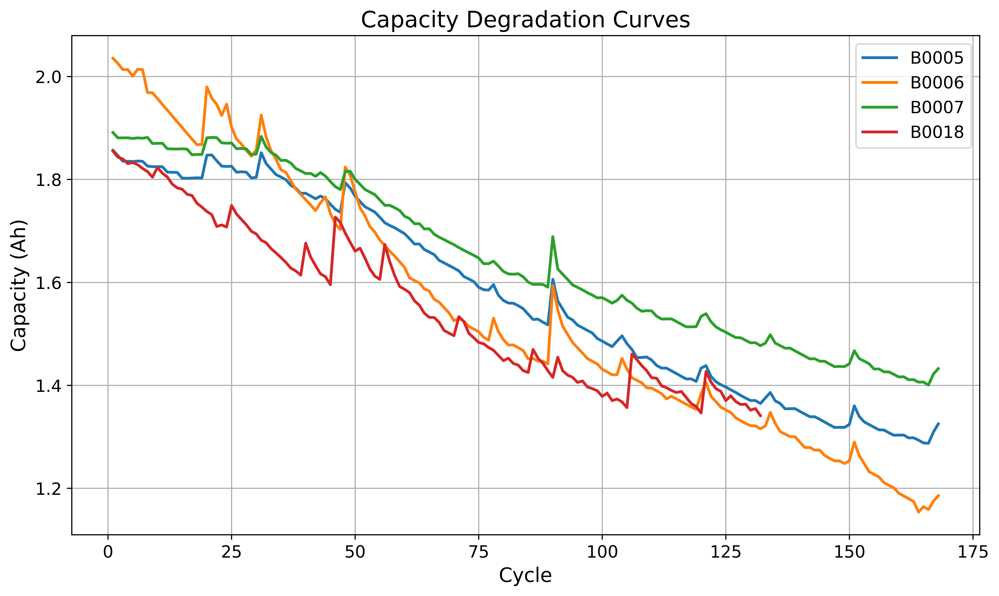

In [56]:
plt.figure(figsize=(10,6))

for battery in master_df['Battery'].unique():

    subset = master_df[
        master_df['Battery']==battery
    ]

    plt.plot(
        subset['Cycle'],
        subset['Capacity'],
        linewidth=2,
        label=battery
    )

plt.xlabel("Cycle")
plt.ylabel("Capacity (Ah)")
plt.title("Capacity Degradation Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_01_Capacity_Degradation.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

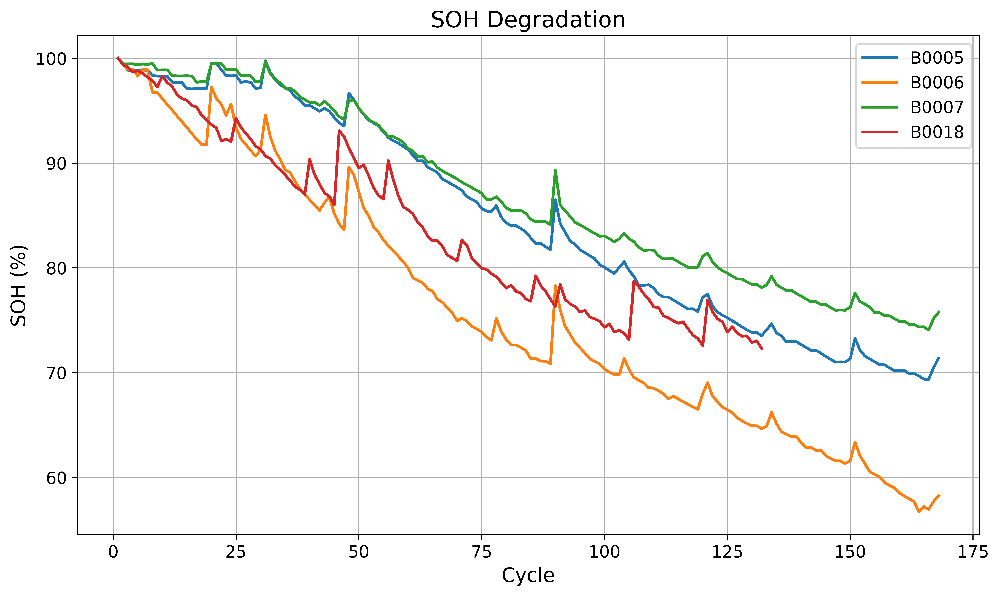

In [57]:
plt.figure(figsize=(10,6))

for battery in master_df['Battery'].unique():

    subset = master_df[
        master_df['Battery']==battery
    ]

    plt.plot(
        subset['Cycle'],
        subset['SOH'],
        linewidth=2,
        label=battery
    )

plt.xlabel("Cycle")
plt.ylabel("SOH (%)")
plt.title("SOH Degradation")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_02_SOH_Degradation.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

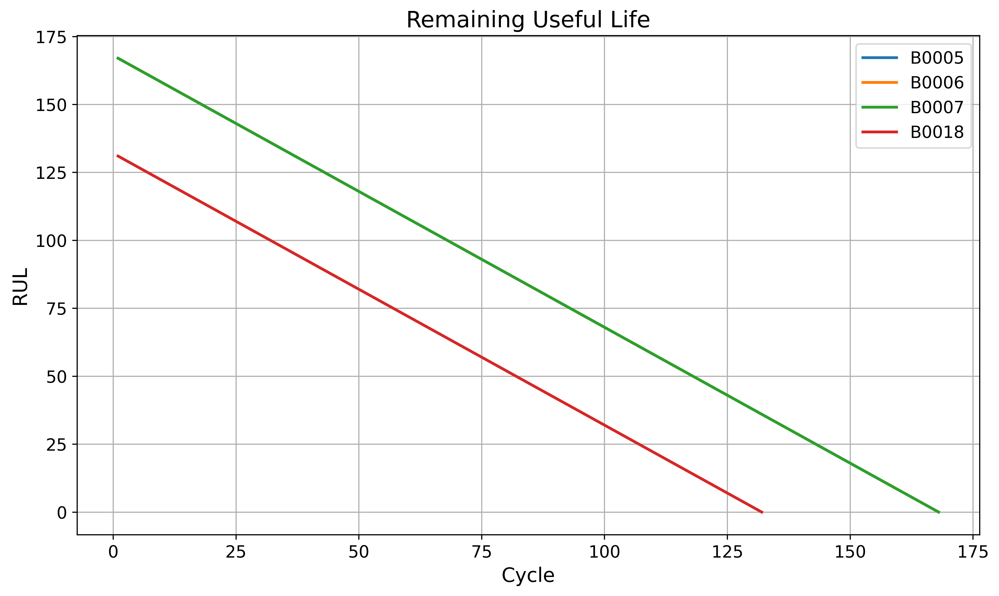

In [58]:
plt.figure(figsize=(10,6))

for battery in master_df['Battery'].unique():

    subset = master_df[
        master_df['Battery']==battery
    ]

    plt.plot(
        subset['Cycle'],
        subset['RUL'],
        linewidth=2,
        label=battery
    )

plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title("Remaining Useful Life")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_03_RUL_Evolution.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

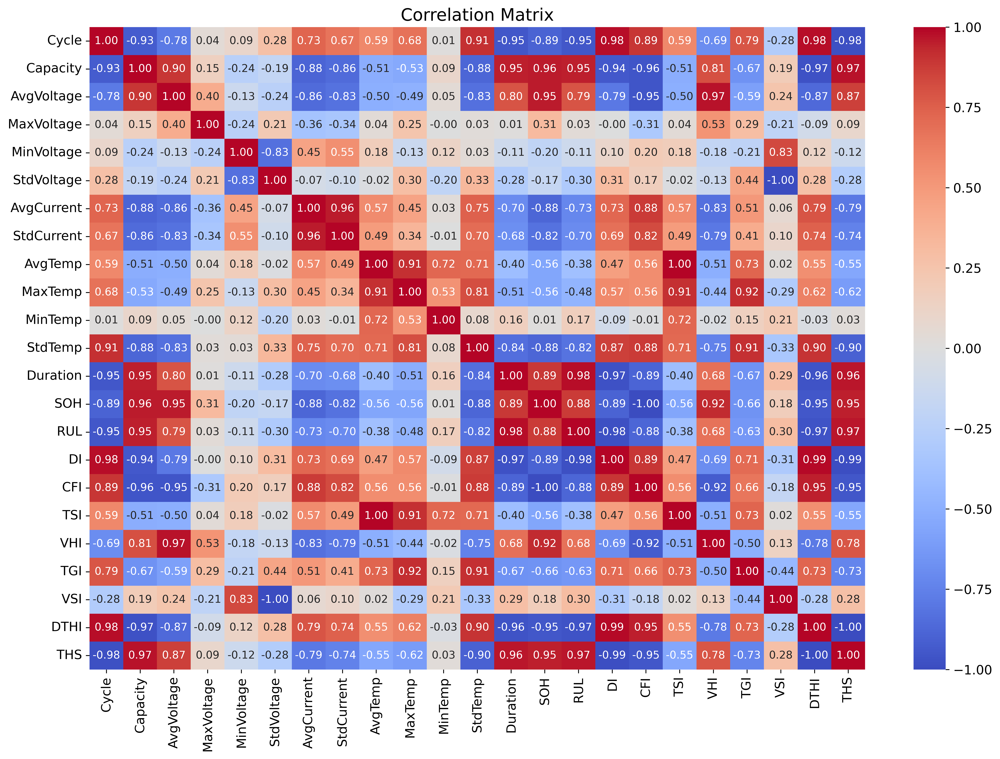

In [59]:
import seaborn as sns

plt.figure(figsize=(14,10))

sns.heatmap(
    master_df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_04_Correlation_Matrix.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

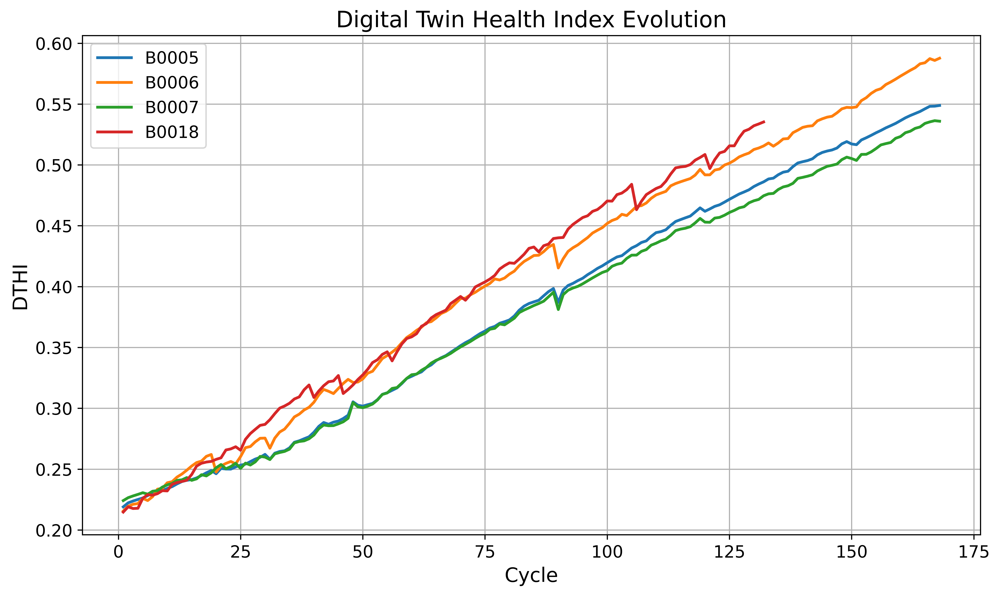

In [60]:
plt.figure(figsize=(10,6))

for battery in master_df['Battery'].unique():

    subset = master_df[
        master_df['Battery']==battery
    ]

    plt.plot(
        subset['Cycle'],
        subset['DTHI'],
        linewidth=2,
        label=battery
    )

plt.xlabel("Cycle")
plt.ylabel("DTHI")
plt.title("Digital Twin Health Index Evolution")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_05_DTHI_Evolution.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

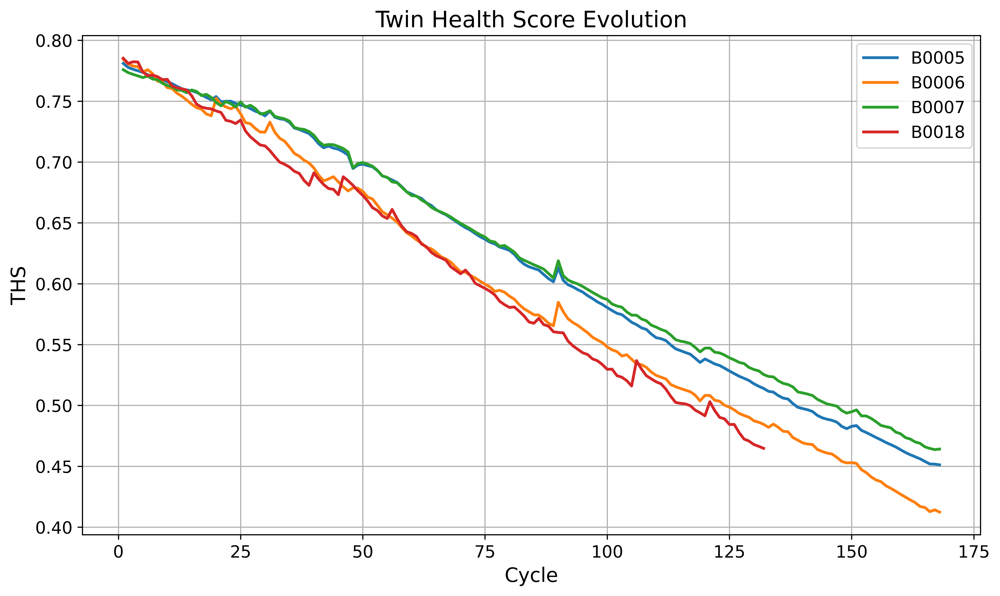

In [61]:
master_df['THS'] = 1 - master_df['DTHI']

plt.figure(figsize=(10,6))

for battery in master_df['Battery'].unique():

    subset = master_df[
        master_df['Battery']==battery
    ]

    plt.plot(
        subset['Cycle'],
        subset['THS'],
        linewidth=2,
        label=battery
    )

plt.xlabel("Cycle")
plt.ylabel("THS")
plt.title("Twin Health Score Evolution")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_06_THS_Evolution.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

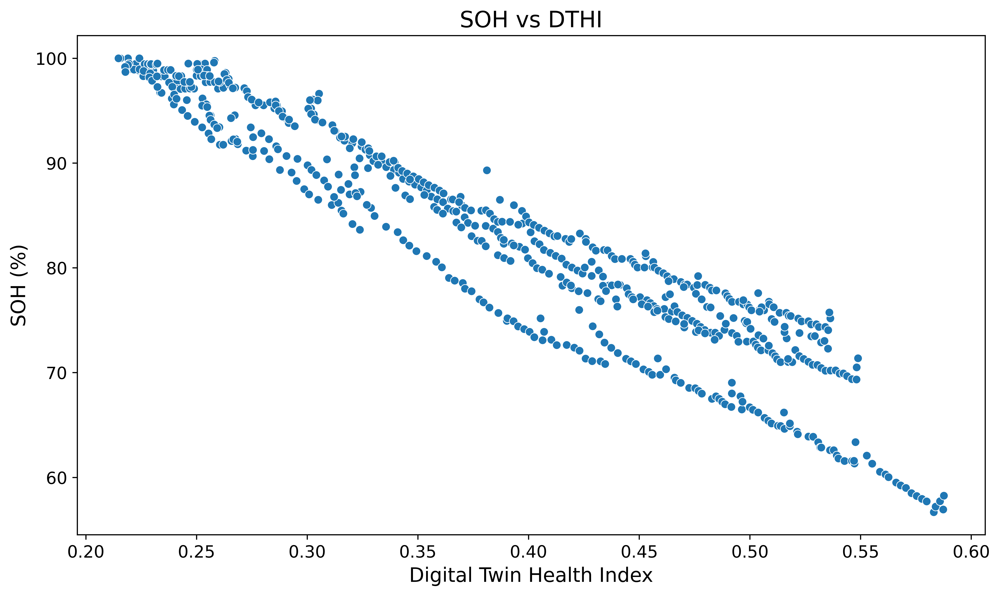

In [62]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=master_df,
    x='DTHI',
    y='SOH'
)

plt.xlabel("Digital Twin Health Index")
plt.ylabel("SOH (%)")
plt.title("SOH vs DTHI")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_07_SOH_vs_DTHI.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

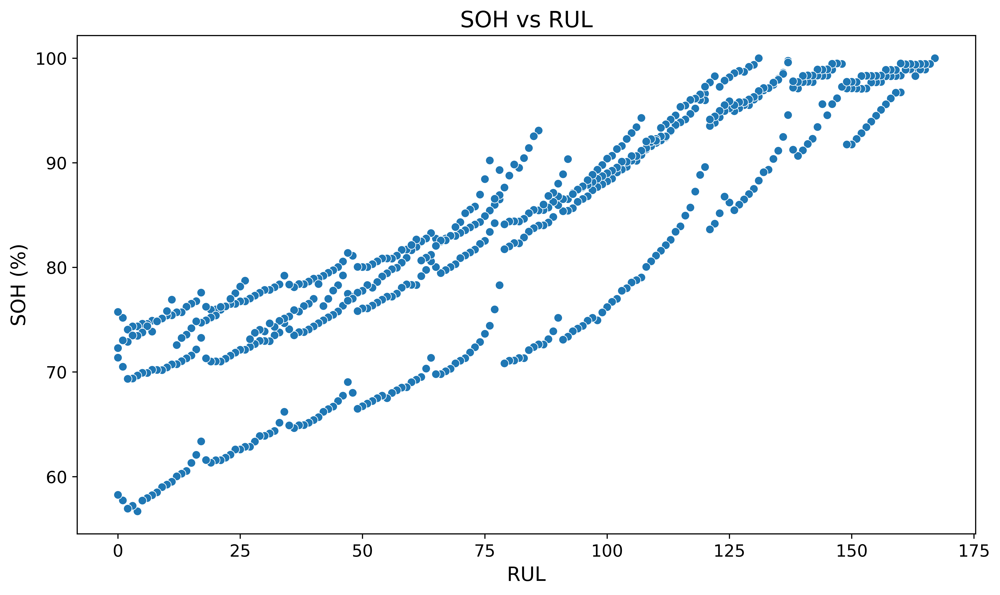

In [63]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=master_df,
    x='RUL',
    y='SOH'
)

plt.xlabel("RUL")
plt.ylabel("SOH (%)")
plt.title("SOH vs RUL")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_08_SOH_vs_RUL.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

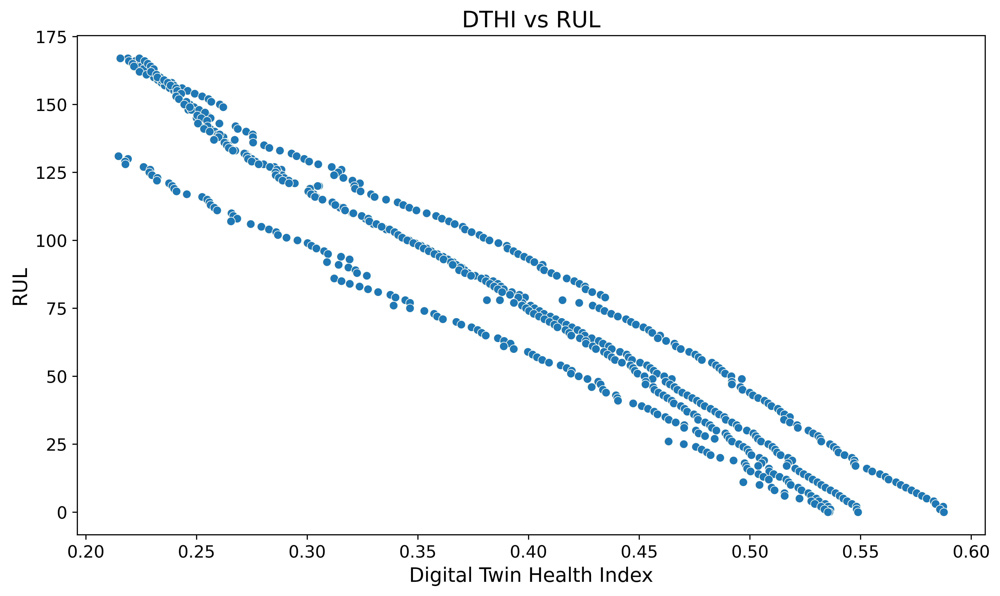

In [64]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=master_df,
    x='DTHI',
    y='RUL'
)

plt.xlabel("Digital Twin Health Index")
plt.ylabel("RUL")
plt.title("DTHI vs RUL")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_09_DTHI_vs_RUL.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

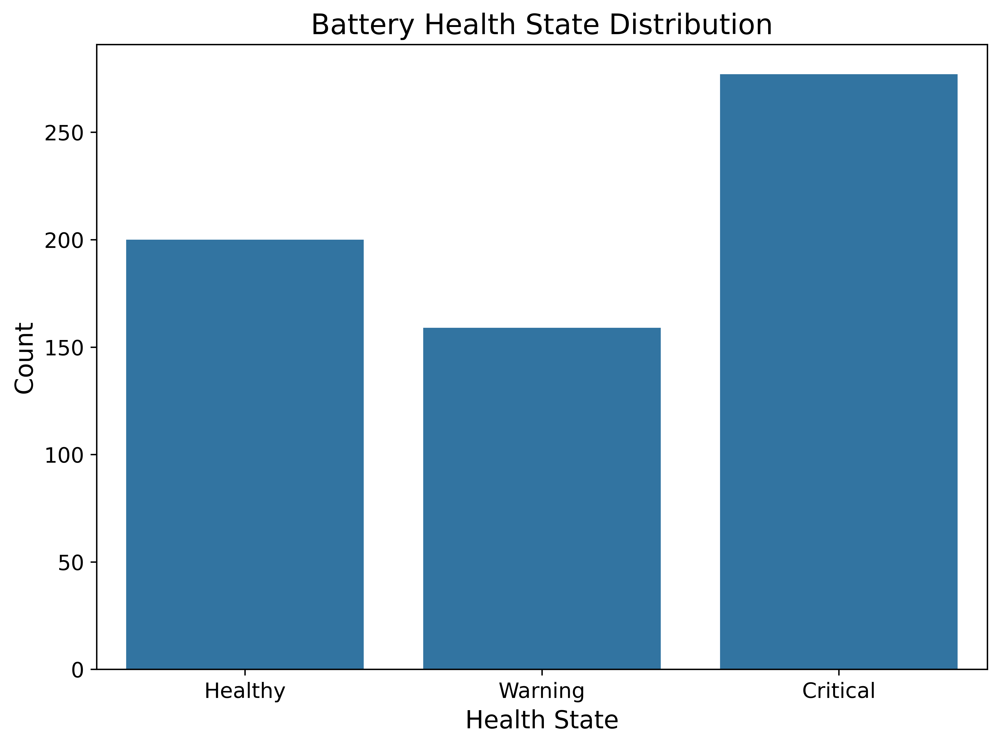

In [65]:
def health_zone(soh):

    if soh >= 90:
        return 'Healthy'

    elif soh >= 80:
        return 'Warning'

    else:
        return 'Critical'

master_df['HealthZone'] = master_df['SOH'].apply(health_zone)

plt.figure(figsize=(8,6))

sns.countplot(
    data=master_df,
    x='HealthZone'
)

plt.xlabel("Health State")
plt.ylabel("Count")
plt.title("Battery Health State Distribution")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_10_Health_State_Distribution.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [66]:
import os

for file in sorted(os.listdir(RESULT_DIR)):
    print(file)

Figure_01_Capacity_Degradation.tiff
Figure_02_SOH_Degradation.tiff
Figure_03_RUL_Evolution.tiff
Figure_04_Correlation_Matrix.tiff
Figure_05_DTHI_Evolution.tiff
Figure_06_THS_Evolution.tiff
Figure_07_SOH_vs_DTHI.tiff
Figure_08_SOH_vs_RUL.tiff
Figure_09_DTHI_vs_RUL.tiff
Figure_10_Health_State_Distribution.tiff


In [67]:
import shutil

shutil.make_archive(
    '/kaggle/working/NASA_Paper_Figures',
    'zip',
    RESULT_DIR
)

print("ZIP file created successfully")

ZIP file created successfully


In [68]:
corr_target = (
    master_df
    .corr(numeric_only=True)['SOH']
    .sort_values(ascending=False)
)

print(corr_target)

SOH           1.000000
Capacity      0.958613
AvgVoltage    0.954996
THS           0.949306
VHI           0.922875
Duration      0.888543
RUL           0.877959
MaxVoltage    0.312725
VSI           0.175822
MinTemp       0.012441
StdVoltage   -0.171377
MinVoltage   -0.200256
MaxTemp      -0.559740
AvgTemp      -0.561959
TSI          -0.561959
TGI          -0.659147
StdCurrent   -0.823761
StdTemp      -0.877106
AvgCurrent   -0.881931
DI           -0.893390
Cycle        -0.894295
DTHI         -0.949306
CFI          -1.000000
Name: SOH, dtype: float64


In [69]:
corr_target.to_csv(
    f"{RESULT_DIR}/Feature_Correlation_with_SOH.csv"
)

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

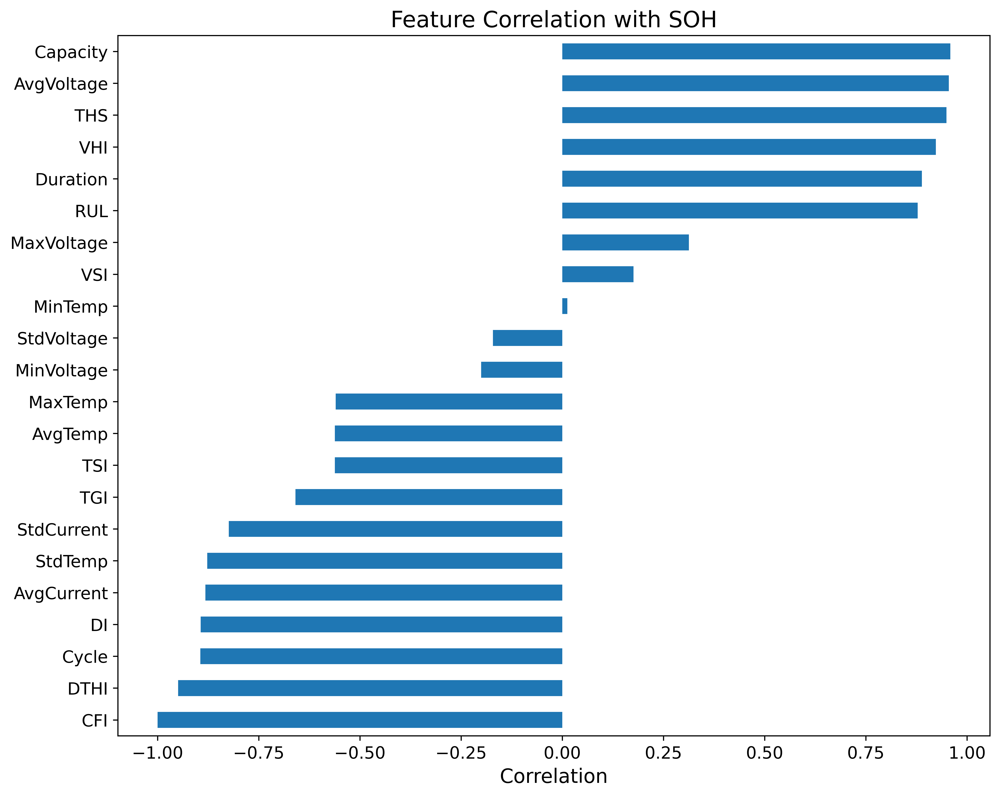

In [70]:
import matplotlib.pyplot as plt

corr_plot = corr_target.drop('SOH')

plt.figure(figsize=(10,8))

corr_plot.sort_values().plot(
    kind='barh'
)

plt.xlabel("Correlation")
plt.title("Feature Correlation with SOH")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_11_Feature_Correlation_SOH.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [71]:
master_df.hist(
    figsize=(18,15)
)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_12_Feature_Histograms.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

In [72]:
plt.figure(figsize=(18,8))

sns.boxplot(
    data=master_df.select_dtypes(
        include='number'
    )
)

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_13_Feature_Boxplots.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

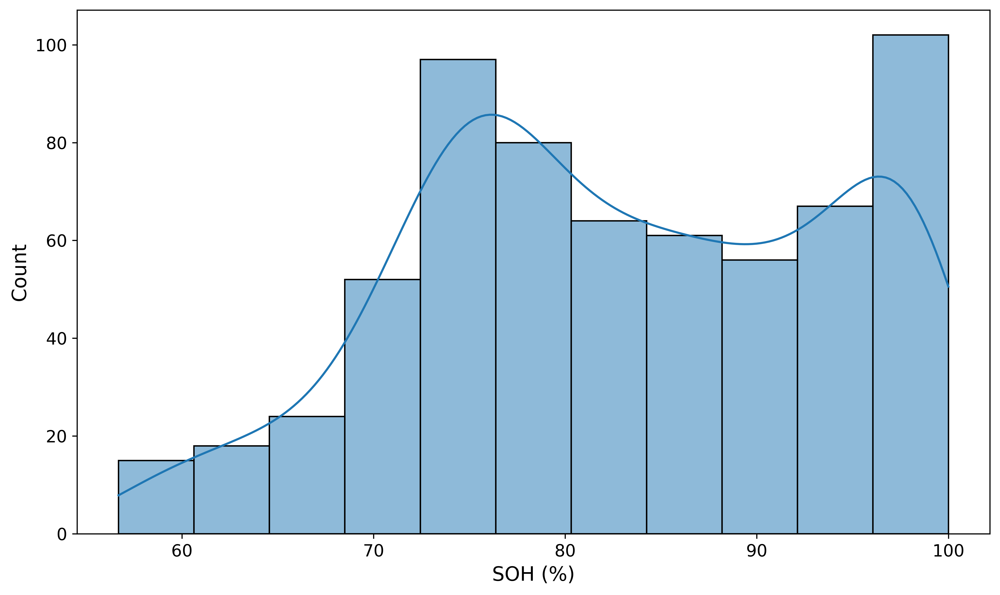

In [73]:
plt.figure(figsize=(10,6))

sns.histplot(
    master_df['SOH'],
    kde=True
)

plt.xlabel("SOH (%)")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_14_SOH_Distribution.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

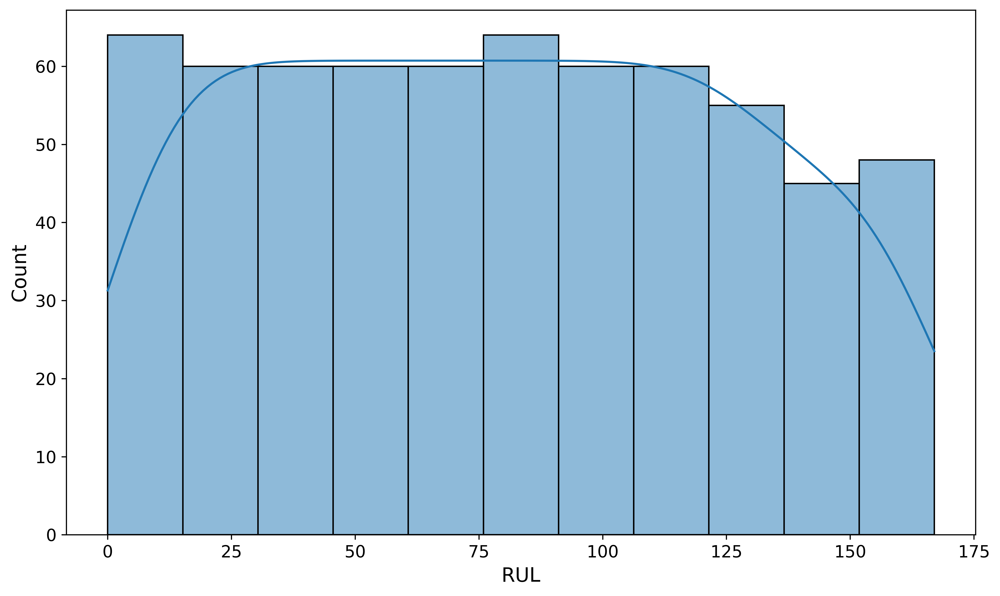

In [74]:
plt.figure(figsize=(10,6))

sns.histplot(
    master_df['RUL'],
    kde=True
)

plt.xlabel("RUL")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_15_RUL_Distribution.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [75]:
master_df['DTHI_v2'] = (

    0.30 * master_df['DI']
    +
    0.25 * (1-master_df['VHI'])
    +
    0.20 * master_df['TSI']
    +
    0.15 * master_df['TGI']
    +
    0.10 * (1-master_df['VSI'])

)

In [76]:
corr_target = (
    master_df
    .corr(numeric_only=True)['SOH']
    .sort_values(ascending=False)
)

print(corr_target)

SOH           1.000000
Capacity      0.958613
AvgVoltage    0.954996
THS           0.949306
VHI           0.922875
Duration      0.888543
RUL           0.877959
MaxVoltage    0.312725
VSI           0.175822
MinTemp       0.012441
StdVoltage   -0.171377
MinVoltage   -0.200256
MaxTemp      -0.559740
AvgTemp      -0.561959
TSI          -0.561959
TGI          -0.659147
DTHI_v2      -0.791509
StdCurrent   -0.823761
StdTemp      -0.877106
AvgCurrent   -0.881931
DI           -0.893390
Cycle        -0.894295
DTHI         -0.949306
CFI          -1.000000
Name: SOH, dtype: float64


In [77]:
!pip install xgboost lightgbm catboost -q

In [78]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [79]:
master_df = pd.read_csv(
    "/kaggle/working/NASA_Battery_Master.csv"
)

print(master_df.shape)

(636, 23)


In [92]:
FEATURES = [

    'AvgVoltage',
    'MaxVoltage',

    'AvgCurrent',

    'AvgTemp',

    'Duration',

    'Cycle',

    'DI',

    'TSI',

    'VHI',

    'TGI',

    'VSI',

    'DTHI'
]

TARGET = 'SOH'

In [93]:
train_df = master_df[
    master_df['Battery'].isin(
        ['B0005','B0006','B0007']
    )
]

In [94]:
test_df = master_df[
    master_df['Battery']=='B0018'
]

In [95]:
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print(X_train.shape)
print(X_test.shape)

(504, 12)
(132, 12)


In [96]:
print(master_df.columns.tolist())

['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']


In [97]:
master_df['TGI_norm'] = (
    master_df['TGI']
    /
    master_df['TGI'].max()
)

In [98]:
master_df['DTHI_v2'] = (

    0.30 * master_df['DI']
    +
    0.25 * (1 - master_df['VHI'])
    +
    0.20 * master_df['TSI']
    +
    0.15 * master_df['TGI']
    +
    0.10 * (1 - master_df['VSI'])

)

In [99]:
print(master_df[['DTHI','DTHI_v2']].head())

       DTHI   DTHI_v2
0  0.219002  2.408182
1  0.222309  2.363935
2  0.223809  2.324873
3  0.225087  2.330096
4  0.226334  2.336960


In [100]:
FEATURES = [

    'AvgVoltage',
    'MaxVoltage',

    'AvgCurrent',

    'AvgTemp',

    'Duration',

    'Cycle',

    'DI',

    'TSI',

    'VHI',

    'TGI',

    'VSI',

    'DTHI_v2'
]

In [101]:
missing = [f for f in FEATURES if f not in master_df.columns]

print("Missing Features:", missing)

Missing Features: []


In [103]:
train_df = master_df[
    master_df['Battery'].isin(
        ['B0005','B0006','B0007']
    )
]

In [104]:
test_df = master_df[
    master_df['Battery']=='B0018'
]

In [105]:
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print(X_train.shape)
print(X_test.shape)

(504, 12)
(132, 12)


In [106]:
def evaluate_model(model, name):

    model.fit(X_train, y_train)

    preds = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        preds
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            preds
        )
    )

    mape = np.mean(
        np.abs(
            (y_test-preds)/y_test
        )
    ) * 100

    r2 = r2_score(
        y_test,
        preds
    )

    return [

        name,

        mae,
        rmse,
        mape,
        r2
    ]

In [107]:
lr_result = evaluate_model(
    LinearRegression(),
    "Linear Regression"
)

In [108]:
rf_result = evaluate_model(

    RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ),

    "Random Forest"
)

In [109]:
xgb_result = evaluate_model(

    XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),

    "XGBoost"
)

In [110]:
lgb_result = evaluate_model(

    LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42
    ),

    "LightGBM"
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005048 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2027
[LightGBM] [Info] Number of data points in the train set: 504, number of used features: 12
[LightGBM] [Info] Start training from score 82.553600
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

In [111]:
cat_result = evaluate_model(

    CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        verbose=False
    ),

    "CatBoost"
)

In [112]:
results = pd.DataFrame(

    [

        lr_result,
        rf_result,
        xgb_result,
        lgb_result,
        cat_result

    ],

    columns=[

        'Model',

        'MAE',
        'RMSE',
        'MAPE',
        'R2'

    ]
)

results

,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,6.581073,7.615849,8.341189,0.161674
1,Random Forest,1.591709,1.943270,1.840105,0.945419
2,XGBoost,1.633209,1.951501,1.909518,0.944956
3,LightGBM,1.268226,1.691729,1.453478,0.958635
4,CatBoost,1.263743,1.500823,1.501141,0.967444


In [113]:
results.to_csv(
    "/kaggle/working/SOH_Model_Results.csv",
    index=False
)

results

,Model,MAE,RMSE,MAPE,R2
0,Linear Regression,6.581073,7.615849,8.341189,0.161674
1,Random Forest,1.591709,1.943270,1.840105,0.945419
2,XGBoost,1.633209,1.951501,1.909518,0.944956
3,LightGBM,1.268226,1.691729,1.453478,0.958635
4,CatBoost,1.263743,1.500823,1.501141,0.967444


In [114]:
best_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

best_model.fit(
    X_train,
    y_train
)

preds = best_model.predict(
    X_test
)

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

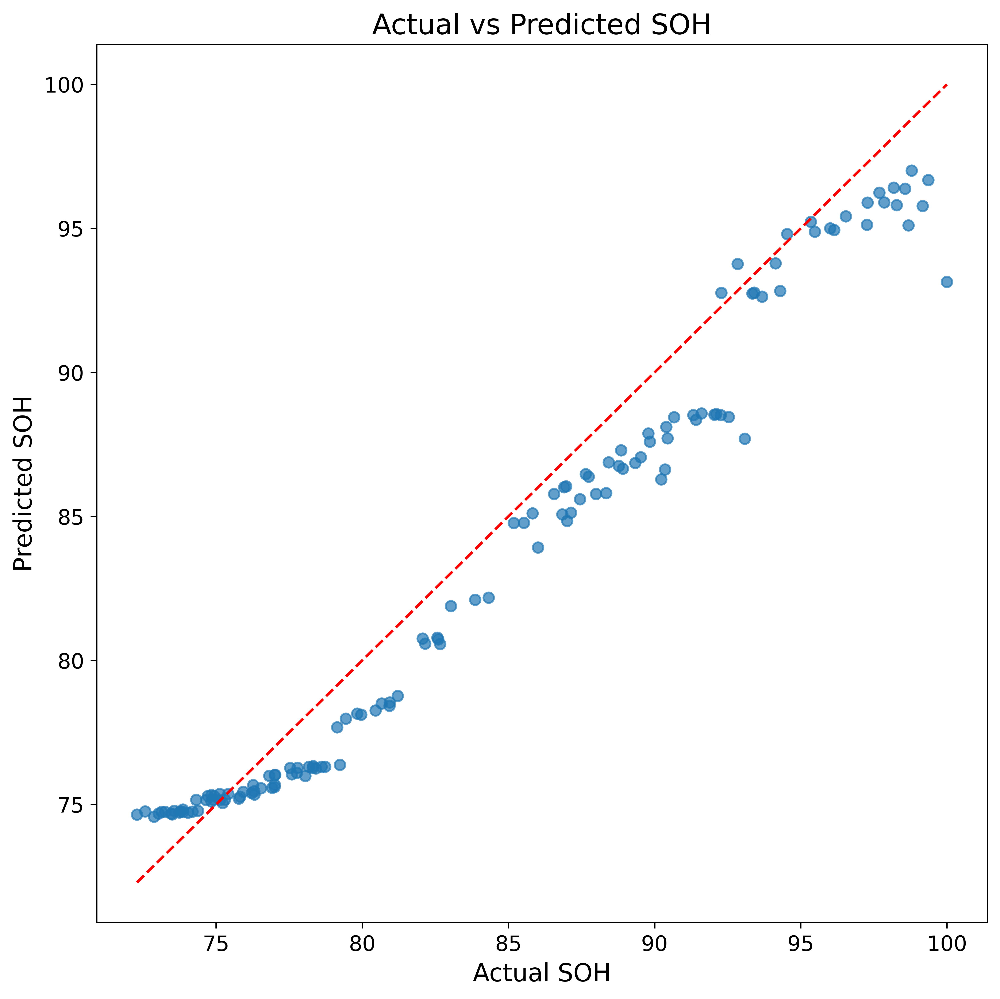

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    preds,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")

plt.title(
    "Actual vs Predicted SOH"
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/Paper_Results_TIFF/Figure_16_Actual_vs_Predicted_SOH.tiff",
    dpi=600,
    format='tiff'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

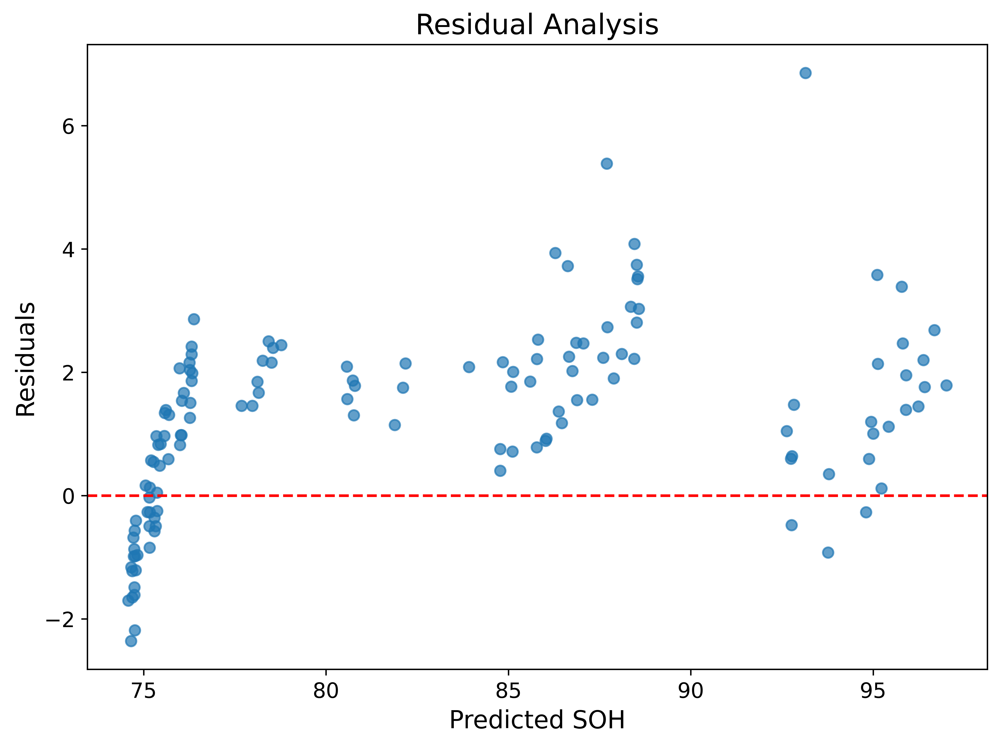

In [116]:
residuals = y_test - preds

plt.figure(figsize=(8,6))

plt.scatter(
    preds,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted SOH")
plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_17_Residual_Plot.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

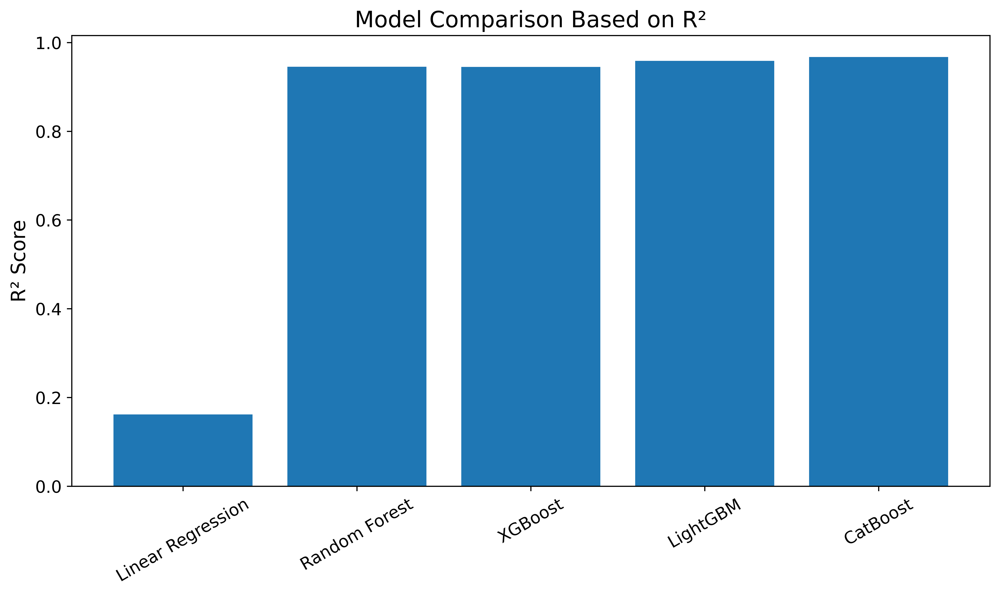

In [117]:
plt.figure(figsize=(10,6))

plt.bar(
    results['Model'],
    results['R2']
)

plt.ylabel("R² Score")

plt.title(
    "Model Comparison Based on R²"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_18_Model_Comparison_R2.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

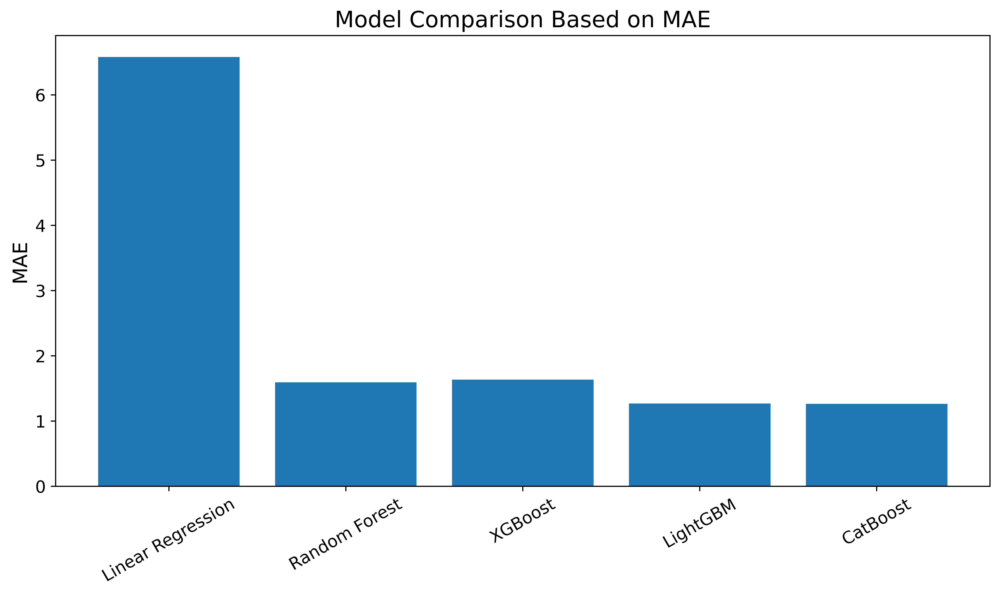

In [118]:
plt.figure(figsize=(10,6))

plt.bar(
    results['Model'],
    results['MAE']
)

plt.ylabel("MAE")

plt.title(
    "Model Comparison Based on MAE"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_19_Model_Comparison_MAE.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

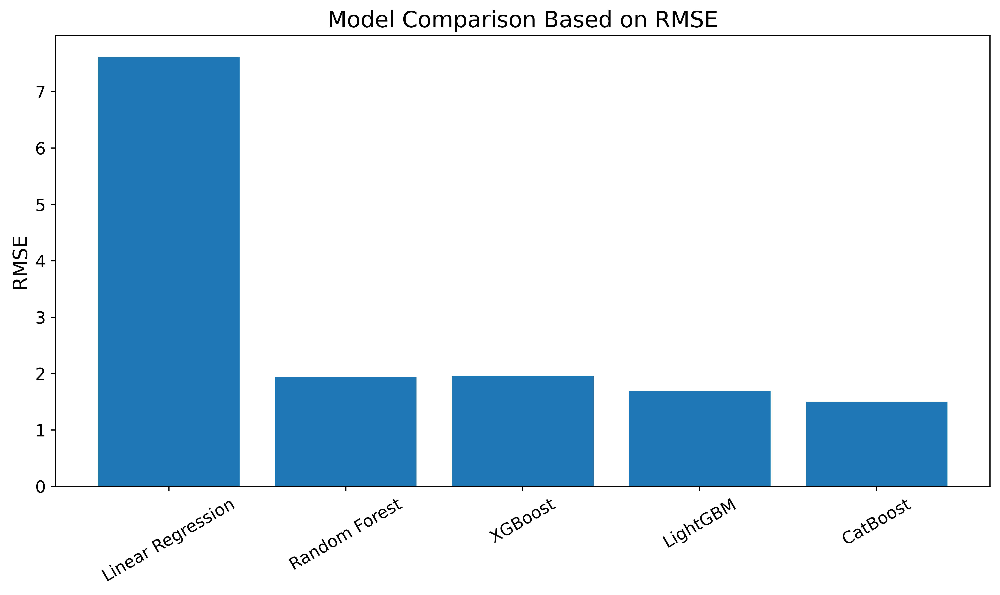

In [119]:
plt.figure(figsize=(10,6))

plt.bar(
    results['Model'],
    results['RMSE']
)

plt.ylabel("RMSE")

plt.title(
    "Model Comparison Based on RMSE"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_20_Model_Comparison_RMSE.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [120]:
import os

for file in sorted(os.listdir(RESULT_DIR)):
    print(file)

Feature_Correlation_with_SOH.csv
Figure_01_Capacity_Degradation.tiff
Figure_02_SOH_Degradation.tiff
Figure_03_RUL_Evolution.tiff
Figure_04_Correlation_Matrix.tiff
Figure_05_DTHI_Evolution.tiff
Figure_06_THS_Evolution.tiff
Figure_07_SOH_vs_DTHI.tiff
Figure_08_SOH_vs_RUL.tiff
Figure_09_DTHI_vs_RUL.tiff
Figure_10_Health_State_Distribution.tiff
Figure_11_Feature_Correlation_SOH.tiff
Figure_12_Feature_Histograms.tiff
Figure_13_Feature_Boxplots.tiff
Figure_14_SOH_Distribution.tiff
Figure_15_RUL_Distribution.tiff
Figure_16_Actual_vs_Predicted_SOH.tiff
Figure_17_Residual_Plot.tiff
Figure_18_Model_Comparison_R2.tiff
Figure_19_Model_Comparison_MAE.tiff
Figure_20_Model_Comparison_RMSE.tiff


In [ ]:
import shutil

shutil.make_archive(
    '/kaggle/working/NASA_SCI_Figures',
    'zip',
    RESULT_DIR
)

print("ZIP created successfully")

In [121]:
from catboost import CatBoostRegressor
import pandas as pd
import matplotlib.pyplot as plt

model = CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    verbose=False
)

model.fit(X_train, y_train)

importance = model.get_feature_importance()

feature_importance = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

       Feature  Importance
8          VHI   25.128436
0   AvgVoltage   22.287560
1   MaxVoltage    9.126888
2   AvgCurrent    8.993943
4     Duration    7.489399
6           DI    6.609933
5        Cycle    6.517522
11     DTHI_v2    4.074378
3      AvgTemp    4.032969
10         VSI    3.890293
9          TGI    1.028117
7          TSI    0.820562


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

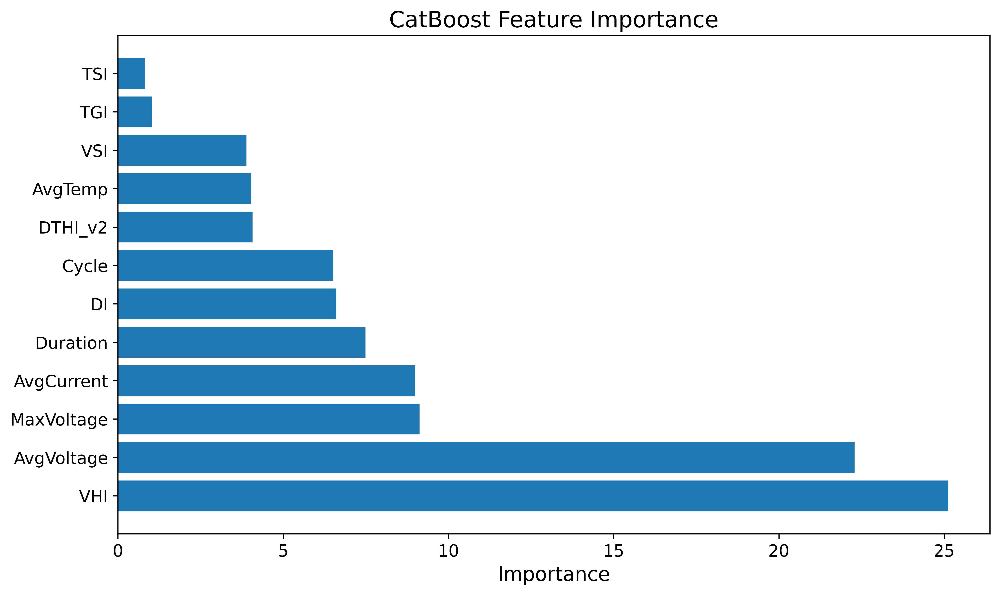

In [122]:
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Importance")
plt.title("CatBoost Feature Importance")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_18_Feature_Importance.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [123]:
!pip install shap -q

In [125]:
model = CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    verbose=False
)

model.fit(X_train, y_train)

importance = model.get_feature_importance()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

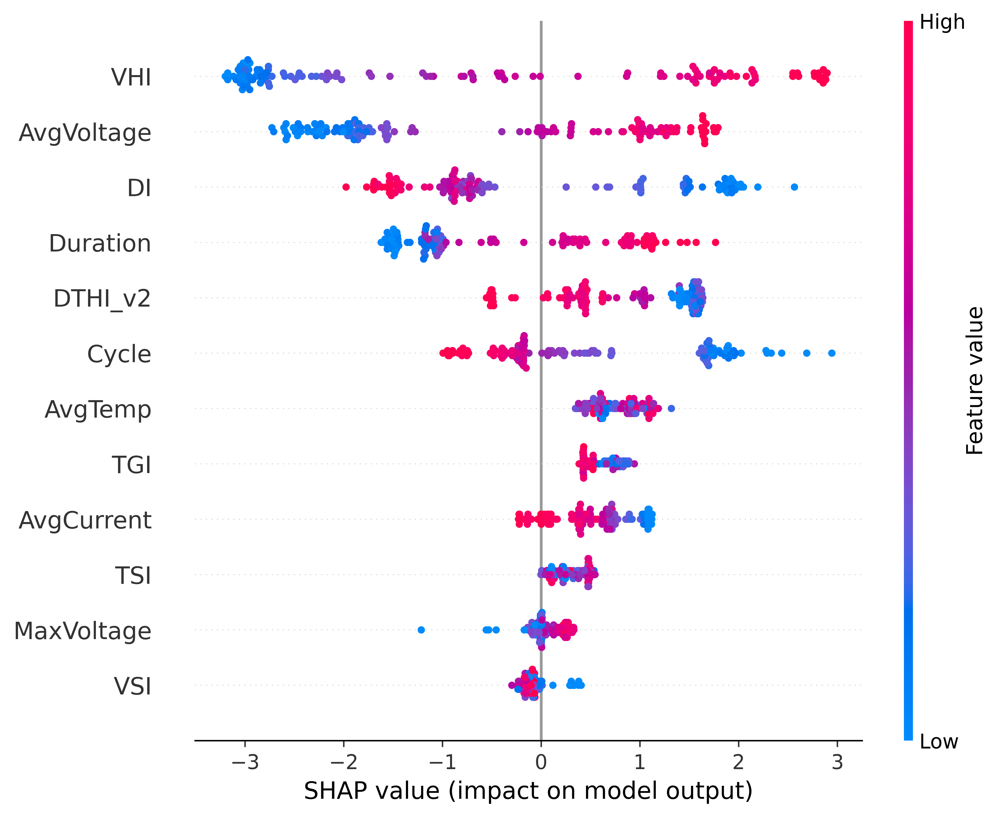

In [126]:
import shap

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_22_SHAP_Summary.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

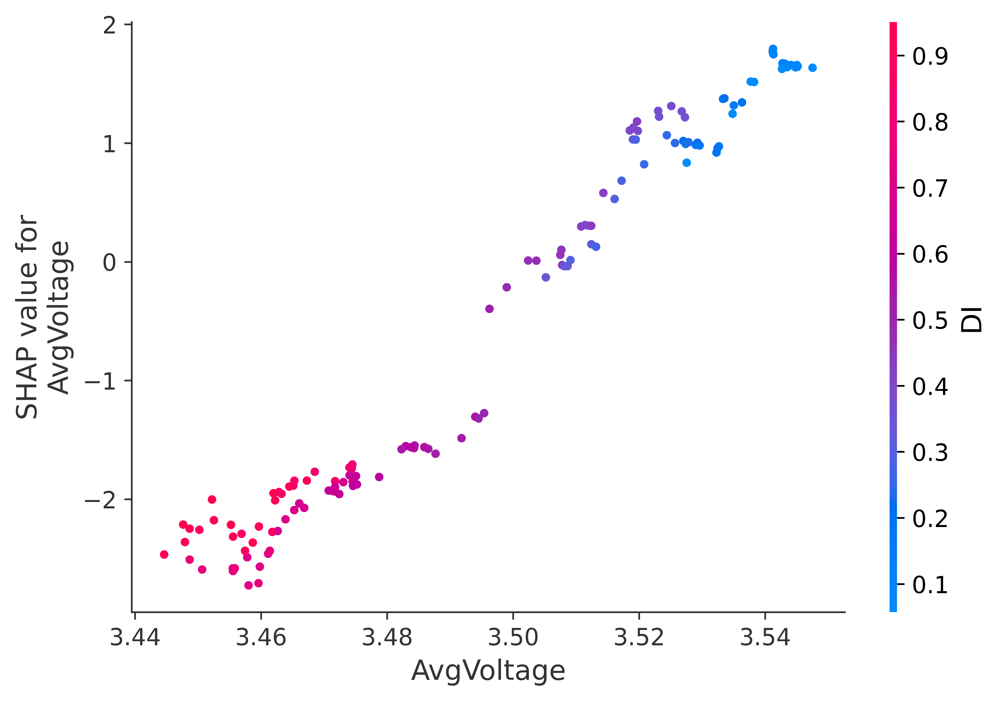

In [128]:
shap.dependence_plot(
    'AvgVoltage',
    shap_values,
    X_test,
    show=False
)

plt.savefig(
    f"{RESULT_DIR}/Figure_23_SHAP_Dependence.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

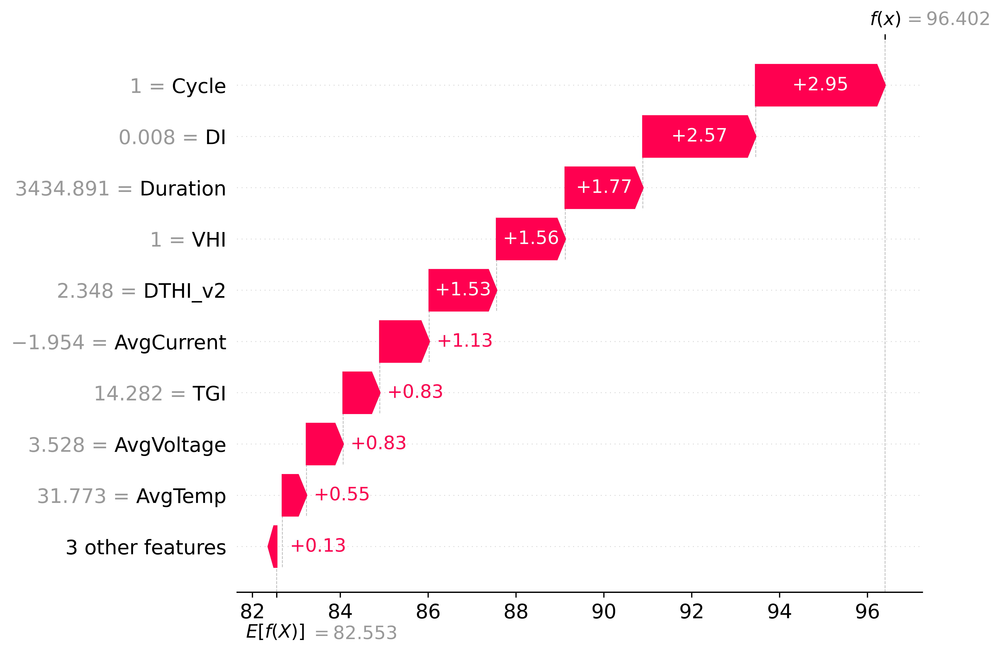

In [129]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test.iloc[0],
        feature_names=X_test.columns
    ),
    show=False
)

plt.savefig(
    f"{RESULT_DIR}/Figure_24_SHAP_Waterfall.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [130]:
import shap

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

In [131]:
import os

for file in sorted(os.listdir(RESULT_DIR)):
    if "Figure_22" in file or \
       "Figure_23" in file or \
       "Figure_24" in file:
        print(file)

Figure_22_SHAP_Summary.tiff
Figure_23_SHAP_Dependence.tiff
Figure_24_SHAP_Waterfall.tiff


In [132]:
import shutil

shutil.make_archive(
    '/kaggle/working/NASA_SCI_Figures_Updated',
    'zip',
    RESULT_DIR
)

print("Updated ZIP file created successfully")

Updated ZIP file created successfully


In [133]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt

In [134]:
master_df = pd.read_csv(
    "/kaggle/working/NASA_Battery_Master.csv"
)

In [135]:
master_df['TGI_norm'] = (
    master_df['TGI']
    /
    master_df['TGI'].max()
)

master_df['DTHI_v2'] = (

    0.30 * master_df['DI']
    +
    0.25 * (1-master_df['VHI'])
    +
    0.20 * master_df['TSI']
    +
    0.15 * master_df['TGI_norm']
    +
    0.10 * (1-master_df['VSI'])

)

In [136]:
FEATURES = [

    'AvgVoltage',
    'MaxVoltage',

    'AvgCurrent',

    'AvgTemp',

    'Duration',

    'Cycle',

    'DI',

    'TSI',

    'VHI',

    'TGI',

    'VSI',

    'DTHI'
]

TARGET = 'SOH'

In [137]:
train_df = master_df[
    master_df['Battery'].isin(
        ['B0005','B0006','B0007']
    )
]

test_df = master_df[
    master_df['Battery']=='B0018'
]

In [138]:
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train = scaler_x.fit_transform(
    train_df[FEATURES]
)

X_test = scaler_x.transform(
    test_df[FEATURES]
)

y_train = scaler_y.fit_transform(
    train_df[['SOH']]
)

y_test = scaler_y.transform(
    test_df[['SOH']]
)

In [139]:
X_train = X_train.reshape(
    X_train.shape[0],
    1,
    X_train.shape[1]
)

X_test = X_test.reshape(
    X_test.shape[0],
    1,
    X_test.shape[1]
)

In [140]:
print(X_train.shape)

(504, 1, 12)


In [141]:
model = Sequential()

model.add(
    LSTM(
        64,
        return_sequences=False,
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )
)

model.add(
    Dropout(0.2)
)

model.add(
    Dense(32, activation='relu')
)

model.add(
    Dense(1)
)

model.compile(

    optimizer='adam',

    loss='mse',

    metrics=['mae']
)

model.summary()

2026-10-19 18:00:43.475160: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,825 (85.25 KB)

 Trainable params: 21,825 (85.25 KB)

 Non-trainable params: 0 (0.00 B)

In [142]:
history = model.fit(

    X_train,
    y_train,

    epochs=100,

    batch_size=32,

    validation_split=0.2,

    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.2428 - mae: 0.4117 - val_loss: 0.0263 - val_mae: 0.1345
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0943 - mae: 0.2705 - val_loss: 0.0083 - val_mae: 0.0799
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0435 - mae: 0.1773 - val_loss: 0.0055 - val_mae: 0.0727
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0110 - mae: 0.0819 - val_loss: 0.0224 - val_mae: 0.1416
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0065 - mae: 0.0635 - val_loss: 0.0255 - val_mae: 0.1476
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0062 - mae: 0.0610 - val_loss: 0.0188 - val_mae: 0.1287
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0054 - mae: 0.0563 - val_loss: 0.0173 - val_mae: 0.1245
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0056 - mae: 0.0580 - val_loss: 0.0127 - val_mae: 0.1027
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

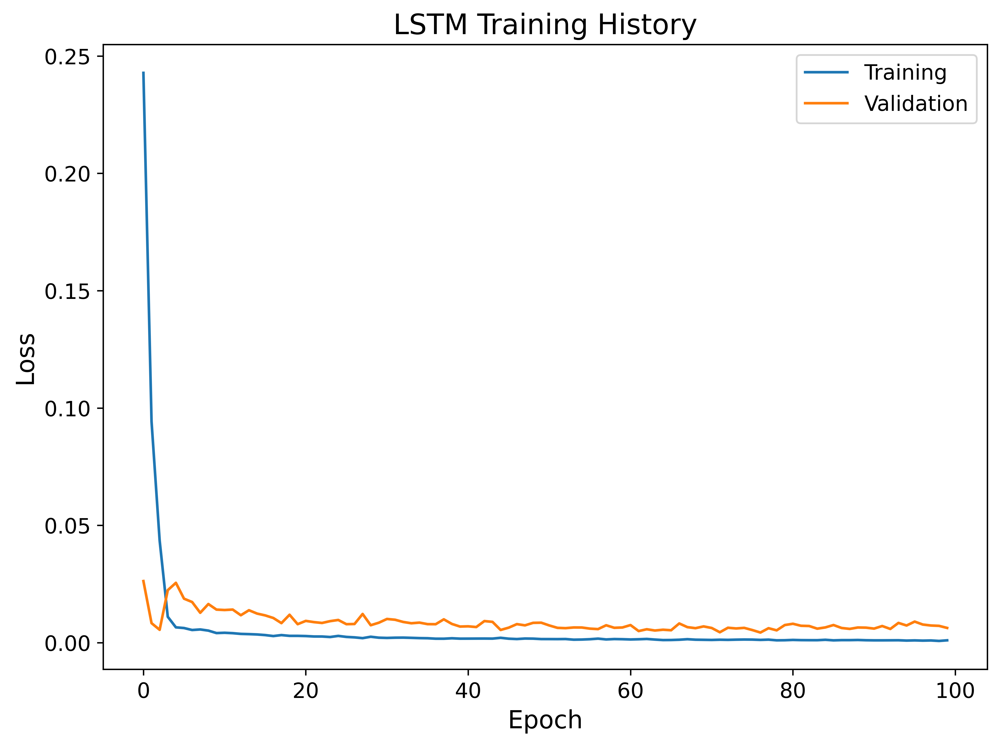

In [143]:
plt.figure(figsize=(8,6))

plt.plot(
    history.history['loss'],
    label='Training'
)

plt.plot(
    history.history['val_loss'],
    label='Validation'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("LSTM Training History")

plt.legend()

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_25_LSTM_Loss_Curve.tiff",
    dpi=600,
    format='tiff'
)

plt.show()

In [144]:
preds = model.predict(X_test)

preds = scaler_y.inverse_transform(
    preds
)

y_true = scaler_y.inverse_transform(
    y_test
)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


In [145]:
mae = mean_absolute_error(
    y_true,
    preds
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        preds
    )
)

mape = np.mean(
    np.abs(
        (y_true-preds)
        /
        y_true
    )
)*100

r2 = r2_score(
    y_true,
    preds
)

print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape)
print("R2  :", r2)

MAE : 2.898734435670484
RMSE: 3.4187976652233205
MAPE: 3.628501848809662
R2  : 0.8310637542968871


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

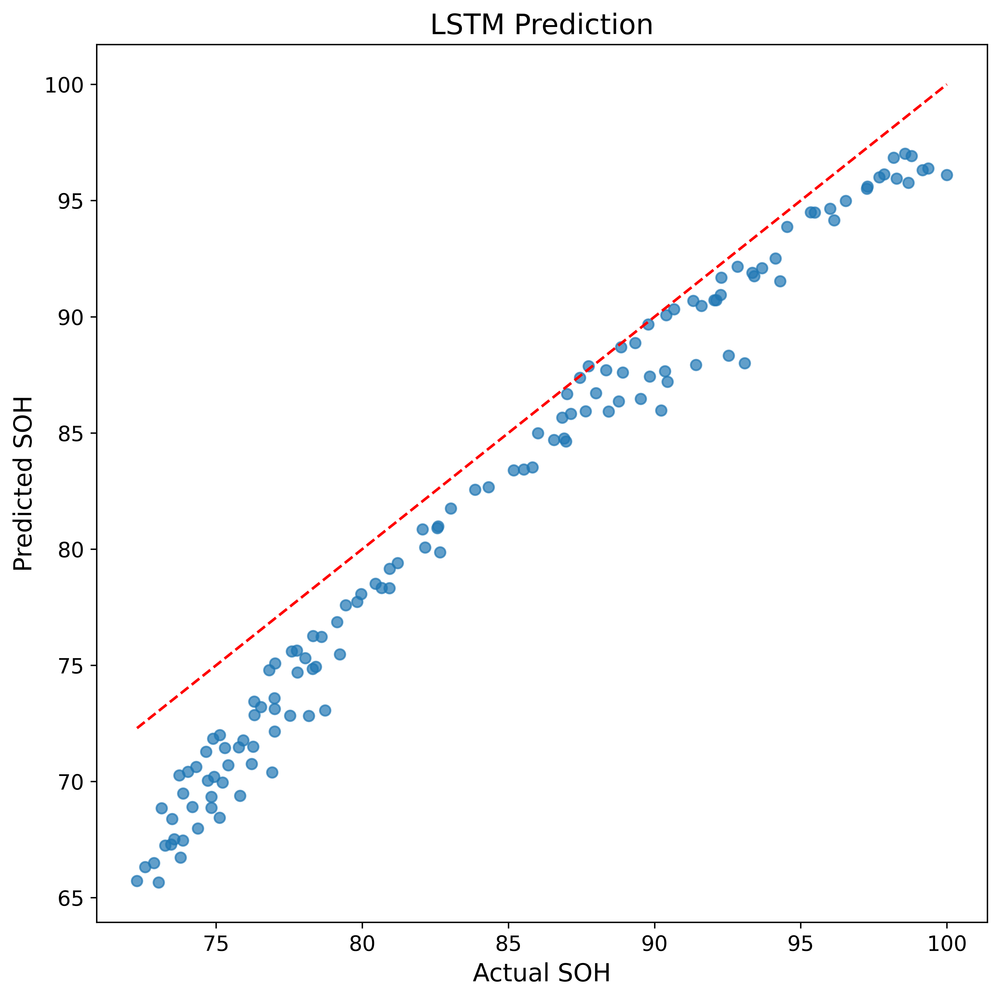

In [146]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_true,
    preds,
    alpha=0.7
)

plt.plot(

    [y_true.min(), y_true.max()],

    [y_true.min(), y_true.max()],

    'r--'
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")

plt.title("LSTM Prediction")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_26_LSTM_Prediction.tiff",
    dpi=600,
    format='tiff'
)

plt.show()

In [149]:

import numpy as np
import pandas as pd

# Convert sequence-shaped data to CatBoost's 2D input format
X_train_cat = np.asarray(X_train).reshape(X_train.shape[0], -1)
y_train_cat = np.asarray(y_train).reshape(-1)

print("CatBoost X_train shape:", X_train_cat.shape)
print("CatBoost y_train shape:", y_train_cat.shape)

# Train CatBoost
cat_model.fit(X_train_cat, y_train_cat)

# Extract feature importance
importance = cat_model.get_feature_importance()

feature_names = (
    FEATURES if len(FEATURES) == X_train_cat.shape[1]
    else [f"Feature_{i}" for i in range(X_train_cat.shape[1])]
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df)


CatBoost X_train shape: (504, 12)
CatBoost y_train shape: (504,)


,Feature,Importance
8,VHI,31.471713
0,AvgVoltage,13.275563
11,DTHI,9.440231
1,MaxVoltage,9.039793
6,DI,9.025849
2,AvgCurrent,7.924051
5,Cycle,6.995343
4,Duration,6.952513
10,VSI,2.348976
9,TGI,2.022999


In [153]:

import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the original tabular datasets, not the 3D sequence arrays
FEATURES = [
    "AvgVoltage", "MaxVoltage", "AvgCurrent", "AvgTemp",
    "Duration", "Cycle", "DI", "TSI", "VHI", "TGI",
    "VSI", "DTHI"
]
TARGET = "SOH"

# Verify columns exist
missing = [
    col for col in FEATURES + [TARGET]
    if col not in train_df.columns or col not in test_df.columns
]
if missing:
    raise ValueError(f"Missing columns in train_df/test_df: {missing}")

# Prepare 2D tabular inputs
X_train_cat = train_df[FEATURES].copy()
y_train_cat = train_df[TARGET].astype(float).to_numpy().ravel()

X_test_cat = test_df[FEATURES].copy()
y_test_cat = test_df[TARGET].astype(float).to_numpy().ravel()

# Ensure all feature values are numeric
X_train_cat = X_train_cat.apply(pd.to_numeric, errors="raise")
X_test_cat = X_test_cat.apply(pd.to_numeric, errors="raise")

if X_train_cat.isna().any().any() or X_test_cat.isna().any().any():
    raise ValueError("Missing values detected in the feature data.")

print("X_train_cat shape:", X_train_cat.shape)
print("y_train_cat shape:", y_train_cat.shape)
print("X_test_cat shape:", X_test_cat.shape)
print("y_test_cat shape:", y_test_cat.shape)

# Train CatBoost regressor
cat_model = CatBoostRegressor(
    iterations=500,
    depth=6,
    learning_rate=0.03,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

cat_model.fit(X_train_cat, y_train_cat)

# Predict
y_pred_cat = cat_model.predict(X_test_cat)

# Evaluate
mae = mean_absolute_error(y_test_cat, y_pred_cat)
rmse = np.sqrt(mean_squared_error(y_test_cat, y_pred_cat))
mape = np.mean(
    np.abs((y_test_cat - y_pred_cat) / np.maximum(np.abs(y_test_cat), 1e-8))
) * 100
r2 = r2_score(y_test_cat, y_pred_cat)

print("\n=== CatBoost SOH Regression Results ===")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.4f}%")
print(f"R²:   {r2:.4f}")

# Feature importance
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": cat_model.get_feature_importance()
}).sort_values("Importance", ascending=False)

print("\n=== CatBoost Feature Importance ===")
display(importance_df)


X_train_cat shape: (504, 12)
y_train_cat shape: (504,)
X_test_cat shape: (132, 12)
y_test_cat shape: (132,)

=== CatBoost SOH Regression Results ===
MAE:  1.0307
RMSE: 1.2972
MAPE: 1.2007%
R²:   0.9757

=== CatBoost Feature Importance ===


,Feature,Importance
8,VHI,26.369226
0,AvgVoltage,15.576297
11,DTHI,11.238912
1,MaxVoltage,9.576840
6,DI,8.930379
2,AvgCurrent,8.220826
5,Cycle,6.826607
4,Duration,6.434579
10,VSI,3.177997
9,TGI,1.654355


In [154]:

print("Training batteries:")
print(sorted(train_df["Battery"].unique()))

print("\nTest batteries:")
print(sorted(test_df["Battery"].unique()))

print("\nTraining rows:", len(train_df))
print("Test rows:", len(test_df))

print("\nSOH range in training:")
print(train_df["SOH"].min(), train_df["SOH"].max())

print("\nSOH range in test:")
print(test_df["SOH"].min(), test_df["SOH"].max())


Training batteries:
['B0005', 'B0006', 'B0007']

Test batteries:
['B0018']

Training rows: 504
Test rows: 132

SOH range in training:
56.68928519254556 100.0

SOH range in test:
72.29370201580872 100.0


In [155]:
import pandas as pd

cols = [
    "SOH", "Capacity", "DI", "CFI",
    "TSI", "VHI", "TGI", "VSI", "DTHI"
]

print("Correlation with SOH:")
display(
    master_df[cols]
    .corr(numeric_only=True)["SOH"]
    .sort_values(ascending=False)
    .to_frame("Correlation with SOH")
)

print("\nFirst five rows of engineered features:")
display(master_df[cols].head())

Correlation with SOH:


,Correlation with SOH
SOH,1.000000
Capacity,0.958613
VHI,0.922875
VSI,0.175822
TSI,-0.561959
TGI,-0.659147
DI,-0.893390
DTHI,-0.949306
CFI,-1.000000



First five rows of engineered features:


,SOH,Capacity,DI,CFI,TSI,VHI,TGI,VSI,DTHI
0,100.000000,1.856487,0.005952,0.000000,0.944386,1.000000,14.656188,0.809090,0.219002
1,99.452721,1.846327,0.011905,0.005473,0.948819,1.002122,14.347450,0.809871,0.222309
2,98.861386,1.835349,0.017857,0.011386,0.946431,1.003940,14.084531,0.814647,0.223809
3,98.856718,1.835263,0.023810,0.011433,0.942720,1.003920,14.110061,0.811198,0.225087
4,98.823482,1.834646,0.029762,0.011765,0.938878,1.003545,14.146692,0.808611,0.226334


In [157]:
print(type(X_train))
print(type(y_train))

print(X_train.shape)
print(y_train.shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(504, 1, 12)
(504, 1)


In [159]:
X_train_cat = X_train.reshape(
    X_train.shape[0],
    X_train.shape[2]
)

X_test_cat = X_test.reshape(
    X_test.shape[0],
    X_test.shape[2]
)

y_train_cat = y_train.ravel()
y_test_cat = y_test.ravel()

In [160]:
print(X_train_cat.shape)
print(y_train_cat.shape)

(504, 12)
(504,)


In [161]:
from catboost import CatBoostRegressor

cat_model = CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    verbose=False,
    random_state=42
)

cat_model.fit(
    X_train_cat,
    y_train_cat
)

CatBoostRegressor(iterations=300, learning_rate=0.05, loss_function='RMSE', random_state=42, verbose=False)

In [162]:
importance = cat_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

       Feature  Importance
8          VHI   31.471713
0   AvgVoltage   13.275563
11        DTHI    9.440231
1   MaxVoltage    9.039793
6           DI    9.025849
2   AvgCurrent    7.924051
5        Cycle    6.995343
4     Duration    6.952513
10         VSI    2.348976
9          TGI    2.022999
7          TSI    1.024051
3      AvgTemp    0.478918


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

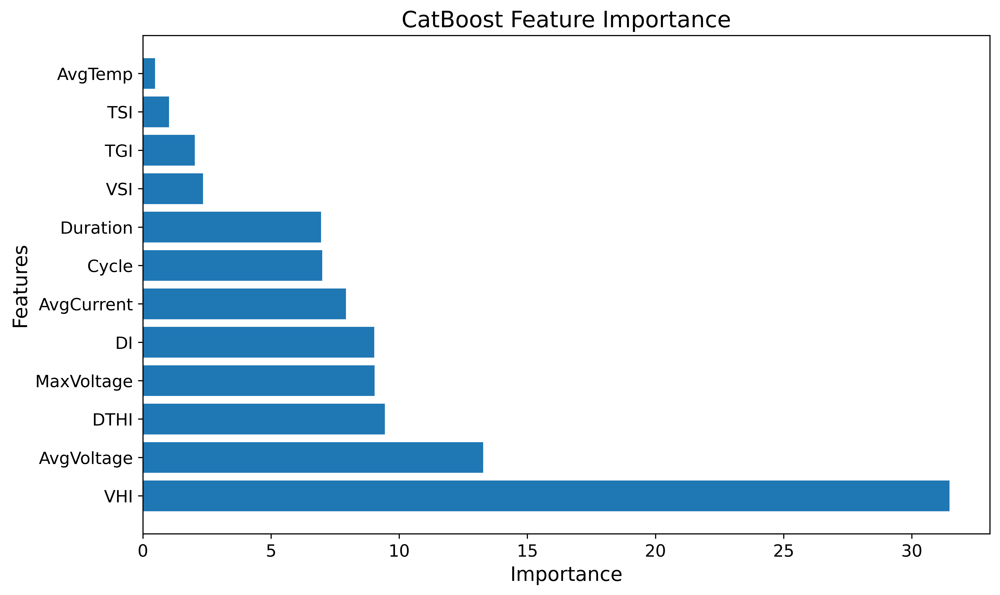

In [163]:
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("CatBoost Feature Importance")

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_21_Feature_Importance.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [164]:
FEATURES_A = [

    'AvgVoltage',
    'MaxVoltage',

    'AvgCurrent',

    'AvgTemp',

    'Duration',

    'Cycle'
]

In [165]:
FEATURES_B = [

    'AvgVoltage',
    'MaxVoltage',

    'AvgCurrent',

    'AvgTemp',

    'Duration',

    'Cycle',

    'DI',

    'TSI',

    'VHI',

    'TGI',

    'VSI'
]

In [166]:
FEATURES_C = [

    'AvgVoltage',
    'MaxVoltage',

    'AvgCurrent',

    'AvgTemp',

    'Duration',

    'Cycle',

    'DI',

    'TSI',

    'VHI',

    'TGI',

    'VSI',

    'DTHI'
]

In [167]:
from catboost import CatBoostRegressor

def run_catboost(features):

    X_train = train_df[features]
    y_train = train_df['SOH']

    X_test = test_df[features]
    y_test = test_df['SOH']

    model = CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        verbose=False,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    preds = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        preds
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            preds
        )
    )

    mape = np.mean(
        np.abs(
            (y_test-preds)/y_test
        )
    )*100

    r2 = r2_score(
        y_test,
        preds
    )

    return [

        mae,
        rmse,
        mape,
        r2
    ]

In [168]:
result_A = run_catboost(FEATURES_A)

result_B = run_catboost(FEATURES_B)

result_C = run_catboost(FEATURES_C)

In [169]:
ablation_results = pd.DataFrame(

    [

        ['Without DT'] + result_A,

        ['DT Components'] + result_B,

        ['DT Components + DTHI_v2'] + result_C

    ],

    columns=[

        'Model',

        'MAE',
        'RMSE',
        'MAPE',
        'R2'
    ]
)

ablation_results

,Model,MAE,RMSE,MAPE,R2
0,Without DT,1.800986,2.185447,2.085043,0.930967
1,DT Components,1.056841,1.352716,1.221058,0.973552
2,DT Components + DTHI_v2,1.134202,1.408732,1.312588,0.971316


In [170]:
ablation_results.to_csv(
    "/kaggle/working/Ablation_Study_Results.csv",
    index=False
)

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

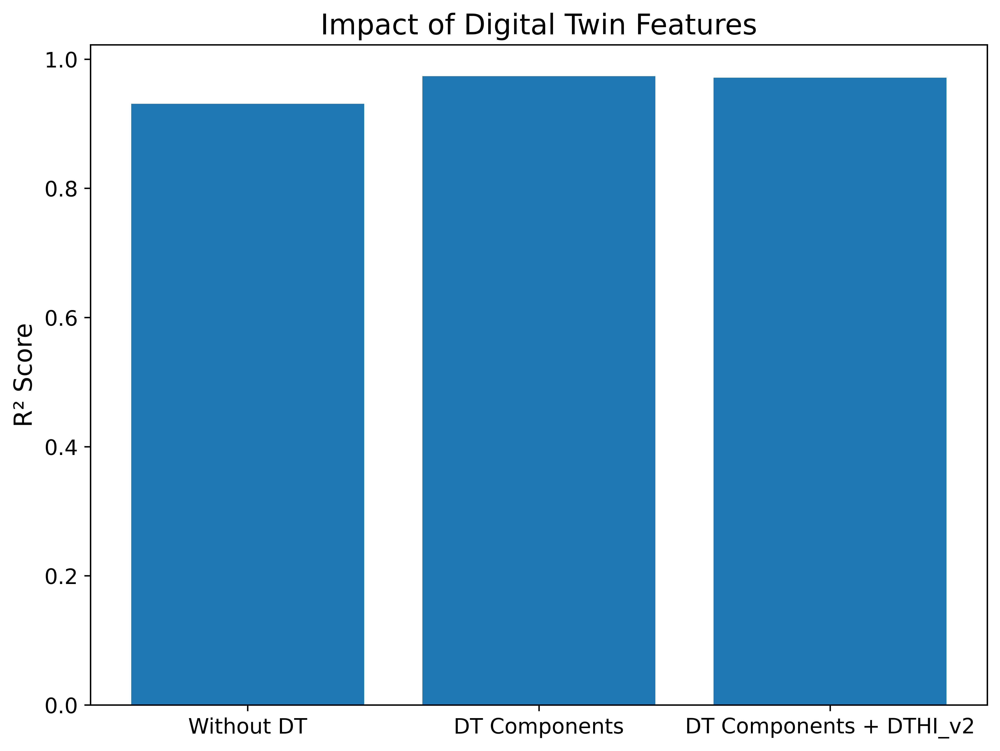

In [171]:
plt.figure(figsize=(8,6))

plt.bar(
    ablation_results['Model'],
    ablation_results['R2']
)

plt.ylabel("R² Score")

plt.title(
    "Impact of Digital Twin Features"
)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_26_Ablation_R2.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

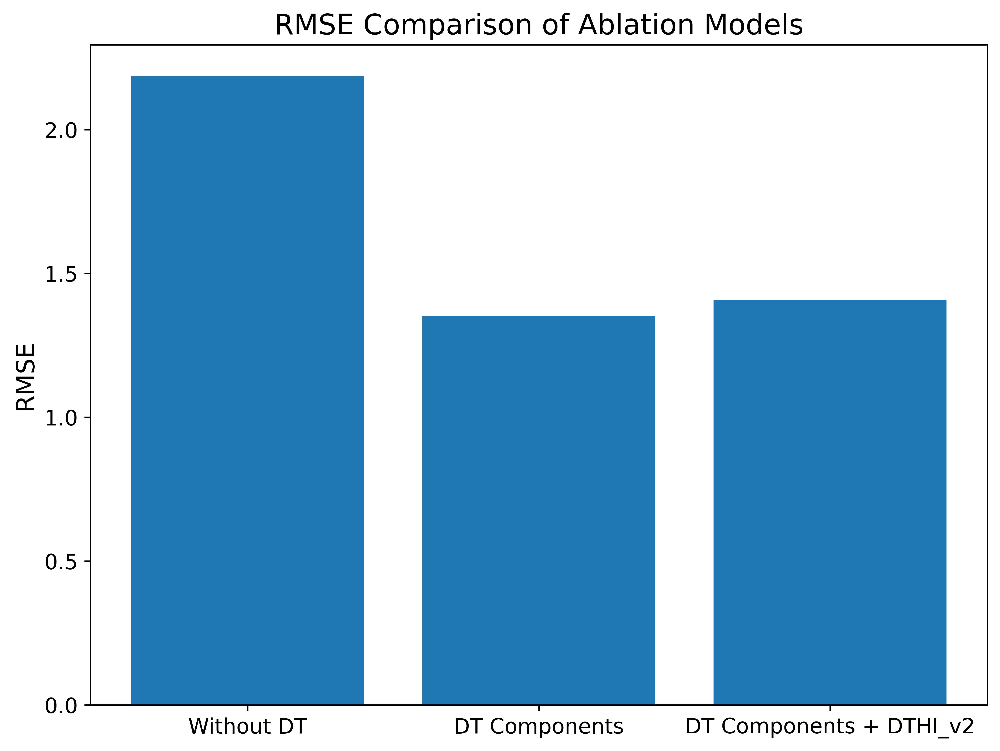

In [172]:
plt.figure(figsize=(8,6))

plt.bar(
    ablation_results['Model'],
    ablation_results['RMSE']
)

plt.ylabel("RMSE")

plt.title(
    "RMSE Comparison of Ablation Models"
)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_27_Ablation_RMSE.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

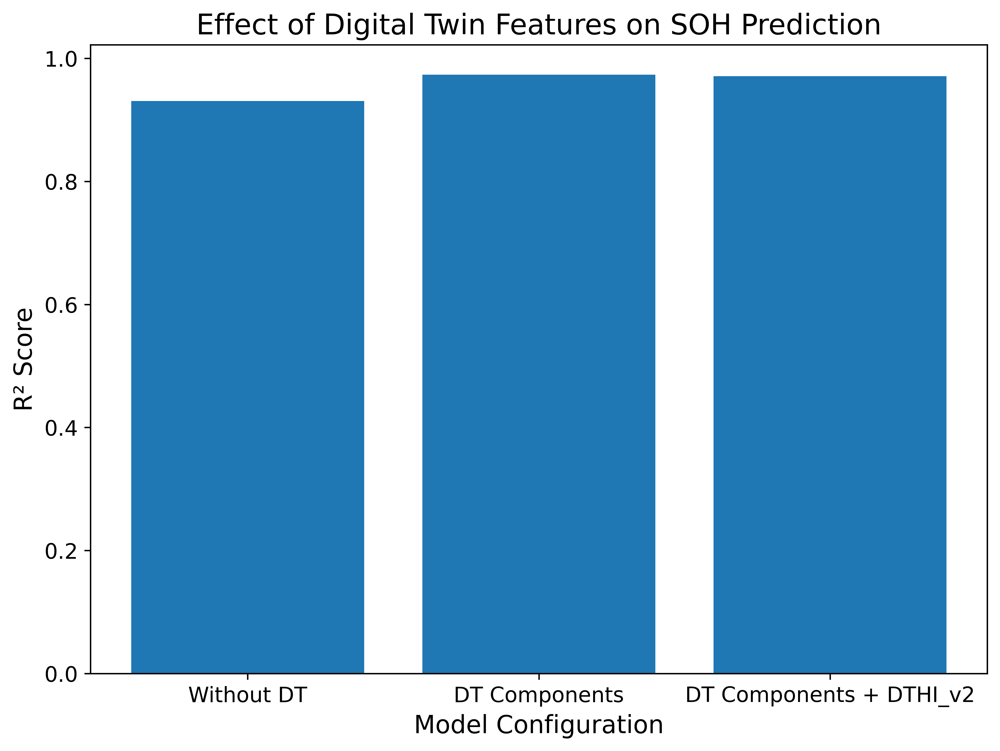

In [173]:
plt.figure(figsize=(8,6))

plt.bar(
    ablation_results['Model'],
    ablation_results['R2']
)

plt.ylabel("R² Score")
plt.xlabel("Model Configuration")

plt.title(
    "Effect of Digital Twin Features on SOH Prediction"
)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/Figure_28_DT_Ablation_Analysis.tiff",
    dpi=600,
    format='tiff',
    bbox_inches='tight'
)

plt.show()

In [ ]:
import os
import shutil

FINAL_DIR = "/kaggle/working/SCI_Paper_Final"

os.makedirs(FINAL_DIR, exist_ok=True)

files_to_keep = [

    "Figure_01_Capacity_Degradation.tiff",
    "Figure_02_SOH_Degradation.tiff",
    "Figure_03_RUL_Evolution.tiff",
    "Figure_04_Correlation_Matrix.tiff",
    "Figure_05_DTHI_Evolution.tiff",

    "Figure_07_SOH_vs_DTHI.tiff",
    "Figure_10_Health_State_Distribution.tiff",

    "Figure_11_Feature_Correlation_SOH.tiff",

    "Figure_16_Actual_vs_Predicted_SOH.tiff",
    "Figure_17_Residual_Plot.tiff",
    "Figure_18_Model_Comparison_R2.tiff",

    "Figure_21_Feature_Importance.tiff",
    "Figure_22_SHAP_Summary.tiff",
    "Figure_23_SHAP_Dependence_AvgVoltage.tiff",
    "Figure_24_SHAP_Waterfall.tiff",

    "Figure_28_DT_Ablation_Analysis.tiff"
]

for f in files_to_keep:
    shutil.copy(
        os.path.join(RESULT_DIR, f),
        os.path.join(FINAL_DIR, f)
    )

shutil.make_archive(
    '/kaggle/working/SCI_Paper_Final',
    'zip',
    FINAL_DIR
)

print("SCI_Paper_Final.zip created successfully")

In [174]:
import os

for file in sorted(os.listdir(RESULT_DIR)):
    print(file)

Feature_Correlation_with_SOH.csv
Figure_01_Capacity_Degradation.tiff
Figure_02_SOH_Degradation.tiff
Figure_03_RUL_Evolution.tiff
Figure_04_Correlation_Matrix.tiff
Figure_05_DTHI_Evolution.tiff
Figure_06_THS_Evolution.tiff
Figure_07_SOH_vs_DTHI.tiff
Figure_08_SOH_vs_RUL.tiff
Figure_09_DTHI_vs_RUL.tiff
Figure_10_Health_State_Distribution.tiff
Figure_11_Feature_Correlation_SOH.tiff
Figure_12_Feature_Histograms.tiff
Figure_13_Feature_Boxplots.tiff
Figure_14_SOH_Distribution.tiff
Figure_15_RUL_Distribution.tiff
Figure_16_Actual_vs_Predicted_SOH.tiff
Figure_17_Residual_Plot.tiff
Figure_18_Feature_Importance.tiff
Figure_18_Model_Comparison_R2.tiff
Figure_19_Model_Comparison_MAE.tiff
Figure_20_Model_Comparison_RMSE.tiff
Figure_21_Feature_Importance.tiff
Figure_22_SHAP_Summary.tiff
Figure_23_SHAP_Dependence.tiff
Figure_24_SHAP_Waterfall.tiff
Figure_25_LSTM_Loss_Curve.tiff
Figure_26_Ablation_R2.tiff
Figure_26_LSTM_Prediction.tiff
Figure_27_Ablation_RMSE.tiff
Figure_28_DT_Ablation_Analysis.tiff


In [ ]:
import os
import shutil

FINAL_DIR = "/kaggle/working/SCI_Paper_Final"

os.makedirs(FINAL_DIR, exist_ok=True)

files_to_keep = [

    "Feature_Correlation_with_SOH.csv",

    "Figure_01_Capacity_Degradation.tiff",
    "Figure_02_SOH_Degradation.tiff",
    "Figure_03_RUL_Evolution.tiff",
    "Figure_04_Correlation_Matrix.tiff",

    "Figure_05_DTHI_Evolution.tiff",
    "Figure_07_SOH_vs_DTHI.tiff",
    "Figure_10_Health_State_Distribution.tiff",
    "Figure_11_Feature_Correlation_SOH.tiff",

    "Figure_16_Actual_vs_Predicted_SOH.tiff",
    "Figure_17_Residual_Plot.tiff",
    "Figure_18_Model_Comparison_R2.tiff",

    "Figure_21_Feature_Importance.tiff",
    "Figure_22_SHAP_Summary.tiff",
    "Figure_23_SHAP_Dependence.tiff",
    "Figure_24_SHAP_Waterfall.tiff",

    "Figure_28_DT_Ablation_Analysis.tiff"
]

for file in files_to_keep:

    src = os.path.join(RESULT_DIR, file)

    if os.path.exists(src):
        shutil.copy(
            src,
            os.path.join(FINAL_DIR, file)
        )

shutil.make_archive(
    "/kaggle/working/SCI_Paper_Final",
    "zip",
    FINAL_DIR
)

print("SCI_Paper_Final.zip created successfully")

In [175]:
dataset_summary = pd.DataFrame({

    'Battery':['B0005','B0006','B0007','B0018'],

    'Cycles':[
        len(master_df[master_df['Battery']=='B0005']),
        len(master_df[master_df['Battery']=='B0006']),
        len(master_df[master_df['Battery']=='B0007']),
        len(master_df[master_df['Battery']=='B0018'])
    ]
})

dataset_summary.to_csv(
    f"{RESULT_DIR}/Table_01_Dataset_Summary.csv",
    index=False
)

In [176]:
feature_table = pd.DataFrame({

'Feature':[
'AvgVoltage',
'MaxVoltage',
'AvgCurrent',
'AvgTemp',
'Duration',
'DI',
'TSI',
'VHI',
'TGI',
'VSI'
],

'Description':[
'Average Voltage',
'Maximum Voltage',
'Average Current',
'Average Temperature',
'Discharge Duration',
'Degradation Index',
'Thermal Stress Index',
'Voltage Health Index',
'Temperature Gradient Index',
'Voltage Stability Index'
]

})

feature_table.to_csv(
    f"{RESULT_DIR}/Table_02_Feature_Definitions.csv",
    index=False
)

In [177]:
import shutil

shutil.copy(

    f"{RESULT_DIR}/Feature_Correlation_with_SOH.csv",

    f"{RESULT_DIR}/Table_03_Correlation_Analysis.csv"

)

'/kaggle/working/Paper_Results_TIFF/Table_03_Correlation_Analysis.csv'

In [178]:
results.to_csv(
    f"{RESULT_DIR}/Table_04_ML_Benchmark_Results.csv",
    index=False
)

In [179]:
feature_importance.to_csv(
    f"{RESULT_DIR}/Table_05_Feature_Importance.csv",
    index=False
)

In [180]:
ablation_results.to_csv(
    f"{RESULT_DIR}/Table_06_Ablation_Study.csv",
    index=False
)

In [181]:
import os

for file in sorted(os.listdir(RESULT_DIR)):
    if file.startswith("Table"):
        print(file)

Table_01_Dataset_Summary.csv
Table_02_Feature_Definitions.csv
Table_03_Correlation_Analysis.csv
Table_04_ML_Benchmark_Results.csv
Table_05_Feature_Importance.csv
Table_06_Ablation_Study.csv


In [182]:
import os
import shutil

FINAL_DIR = "/kaggle/working/SCI_Paper_Final"

os.makedirs(FINAL_DIR, exist_ok=True)

for file in os.listdir(RESULT_DIR):

    if (
        file.startswith("Figure_")
        or
        file.startswith("Table_")
    ):

        shutil.copy(
            os.path.join(RESULT_DIR,file),
            os.path.join(FINAL_DIR,file)
        )

shutil.make_archive(
    "/kaggle/working/SCI_Paper_Final",
    "zip",
    FINAL_DIR
)

print("SCI_Paper_Final.zip created successfully")

SCI_Paper_Final.zip created successfully


In [ ]:
import os
import shutil

FINAL_DIR = "/kaggle/working/NASA_DT_CatBoost_SCI_Final_v1"

# Remove old folder if exists
if os.path.exists(FINAL_DIR):
    shutil.rmtree(FINAL_DIR)

os.makedirs(FINAL_DIR)

# Copy all selected figures
files_to_keep = [

    # Figures
    "Figure_01_Capacity_Degradation.tiff",
    "Figure_02_SOH_Degradation.tiff",
    "Figure_03_RUL_Evolution.tiff",
    "Figure_04_Correlation_Matrix.tiff",

    "Figure_05_DTHI_Evolution.tiff",
    "Figure_07_SOH_vs_DTHI.tiff",
    "Figure_10_Health_State_Distribution.tiff",
    "Figure_11_Feature_Correlation_SOH.tiff",

    "Figure_16_Actual_vs_Predicted_SOH.tiff",
    "Figure_17_Residual_Plot.tiff",
    "Figure_18_Model_Comparison_R2.tiff",

    "Figure_21_Feature_Importance.tiff",
    "Figure_22_SHAP_Summary.tiff",
    "Figure_23_SHAP_Dependence.tiff",
    "Figure_24_SHAP_Waterfall.tiff",

    "Figure_28_DT_Ablation_Analysis.tiff",

    # Tables
    "Table_01_Dataset_Summary.csv",
    "Table_02_Feature_Definitions.csv",
    "Table_03_Correlation_Analysis.csv",
    "Table_04_ML_Benchmark_Results.csv",
    "Table_05_Feature_Importance.csv",
    "Table_06_Ablation_Study.csv"
]

for file in files_to_keep:

    src = os.path.join(RESULT_DIR, file)

    if os.path.exists(src):

        shutil.copy(
            src,
            os.path.join(FINAL_DIR, file)
        )

    else:

        print(f"Missing: {file}")

# Create ZIP
shutil.make_archive(
    "/kaggle/working/NASA_DT_CatBoost_SCI_Final_v1",
    "zip",
    FINAL_DIR
)

print("NASA_DT_CatBoost_SCI_Final_v1.zip created successfully")

In [183]:

from pathlib import Path
import pandas as pd
import numpy as np

# Kaggle input directory containing the uploaded files
DATA_DIR = Path("/kaggle/input")

# Find the uploaded files without assuming the dataset folder name
for filename in [
    "B0005.mat",
    "B0006.mat",
    "B0007.mat",
    "B0018.mat",
    "NASA_Battery_Extracted.csv",
    "NASA_Battery_Master.csv",
    "README.txt",
]:
    matches = list(DATA_DIR.rglob(filename))
    print(f"\n{filename}:")
    if matches:
        for path in matches:
            print(" ", path)
    else:
        print("  NOT FOUND")

# Load the processed datasets
extracted_path = next(DATA_DIR.rglob("NASA_Battery_Extracted.csv"))
master_path = next(DATA_DIR.rglob("NASA_Battery_Master.csv"))

extracted_df = pd.read_csv(extracted_path)
master_df = pd.read_csv(master_path)

print("\nEXTRACTED DATASET:", extracted_df.shape)
print("MASTER DATASET:", master_df.shape)

print("\nMASTER COLUMNS:")
print(master_df.columns.tolist())

print("\nMISSING VALUES:")
print(master_df.isna().sum())

print("\nDUPLICATE ROWS:", master_df.duplicated().sum())

print("\nBATTERY DISTRIBUTION:")
print(master_df.groupby("Battery").agg(
    Rows=("Cycle", "size"),
    First_Cycle=("Cycle", "min"),
    Last_Cycle=("Cycle", "max"),
    SOH_Min=("SOH", "min"),
    SOH_Max=("SOH", "max"),
))


B0005.mat:
  /kaggle/input/datasets/prksh830/nasa-dtec/B0005.mat

B0006.mat:
  /kaggle/input/datasets/prksh830/nasa-dtec/B0006.mat

B0007.mat:
  /kaggle/input/datasets/prksh830/nasa-dtec/B0007.mat

B0018.mat:
  /kaggle/input/datasets/prksh830/nasa-dtec/B0018.mat

NASA_Battery_Extracted.csv:
  /kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Extracted.csv

NASA_Battery_Master.csv:
  /kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv

README.txt:
  /kaggle/input/datasets/prksh830/nasa-dtec/README.txt

EXTRACTED DATASET: (636, 14)
MASTER DATASET: (636, 23)

MASTER COLUMNS:
['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']

MISSING VALUES:
Battery       0
Cycle         0
Capacity      0
AvgVoltage    0
MaxVoltage    0
MinVoltage    0
StdVoltage    0
AvgCurrent    0
StdCurrent    0
AvgT

In [184]:

# Check whether the extracted columns match the first
# 14 columns of the master dataset.

assert extracted_df.shape[0] == master_df.shape[0], (
    "Row counts differ between the two CSV files."
)

assert list(extracted_df.columns) == list(
    master_df.columns[:len(extracted_df.columns)]
), "The extracted columns do not match the master dataset."

pd.testing.assert_frame_equal(
    extracted_df.reset_index(drop=True),
    master_df.iloc[:, :len(extracted_df.columns)].reset_index(drop=True),
    check_dtype=False,
)

print("PASS: Extracted data matches the corresponding master columns.")


PASS: Extracted data matches the corresponding master columns.


In [185]:

print("SOH SUMMARY")
print(master_df["SOH"].describe())

print("\nSOH RANGE BY BATTERY")
print(master_df.groupby("Battery")["SOH"].agg(
    ["min", "max", "mean", "std"]
))

# Check whether CFI is directly derived from SOH
if {"CFI", "SOH"}.issubset(master_df.columns):
    expected_cfi = 1 - master_df["SOH"] / 100
    print(
        "\nCFI matches 1 - SOH/100:",
        np.allclose(
            master_df["CFI"],
            expected_cfi,
            rtol=1e-5,
            atol=1e-5,
            equal_nan=True,
        ),
    )

# Inspect correlations with SOH
numeric_df = master_df.select_dtypes(include=np.number)

print("\nFEATURE CORRELATIONS WITH SOH")
print(
    numeric_df.corr(numeric_only=True)["SOH"]
    .sort_values(ascending=False)
)


SOH SUMMARY
count    636.000000
mean      82.848168
std       10.930582
min       56.689285
25%       74.806730
50%       82.317809
75%       92.526198
max      100.000000
Name: SOH, dtype: float64

SOH RANGE BY BATTERY
               min    max       mean        std
Battery                                        
B0005    69.348842  100.0  84.703082  10.256615
B0006    56.689285  100.0  75.999710  12.383105
B0007    74.056928  100.0  86.958008   8.511152
B0018    72.293702  100.0  83.972882   8.349554

CFI matches 1 - SOH/100: True

FEATURE CORRELATIONS WITH SOH
SOH           1.000000
Capacity      0.958613
AvgVoltage    0.954996
VHI           0.922875
Duration      0.888543
RUL           0.877959
MaxVoltage    0.312725
VSI           0.175822
MinTemp       0.012441
StdVoltage   -0.171377
MinVoltage   -0.200256
MaxTemp      -0.559740
AvgTemp      -0.561959
TSI          -0.561959
TGI          -0.659147
StdCurrent   -0.823761
StdTemp      -0.877106
AvgCurrent   -0.881931
DI           -0.

In [186]:

# SOH feature-leakage audit
import numpy as np
import pandas as pd

df = master_df.copy()

# Features that must not be predictors in the initial SOH model
direct_exclusions = [
    "SOH",   # target itself
    "CFI",   # exact transformation of SOH
    "RUL",   # derived remaining-cycle target; inspect before use
    "DTHI",  # inspect its construction before use
]

print("CHECK 1: CFI derived directly from SOH")
print(np.allclose(df["CFI"], 1 - df["SOH"] / 100))

print("\nCHECK 2: DI versus cycle number")
print("Correlation:", df["DI"].corr(df["Cycle"]))

print("\nCHECK 3: Capacity versus SOH")
print("Correlation:", df["Capacity"].corr(df["SOH"]))

print("\nCHECK 4: Feature availability")
print("Available columns:", df.columns.tolist())
print("Initial excluded features:", direct_exclusions)

# Use only measured variables for the first diagnostic baseline.
baseline_features = [
    "AvgVoltage",
    "MaxVoltage",
    "MinVoltage",
    "StdVoltage",
    "AvgCurrent",
    "StdCurrent",
    "AvgTemp",
    "MaxTemp",
    "MinTemp",
    "StdTemp",
    "Duration",
    "Cycle",
]

print("\nInitial baseline features:")
print(baseline_features)


CHECK 1: CFI derived directly from SOH
True

CHECK 2: DI versus cycle number
Correlation: 0.9836784512555797

CHECK 3: Capacity versus SOH
Correlation: 0.958612723867027

CHECK 4: Feature availability
Available columns: ['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']
Initial excluded features: ['SOH', 'CFI', 'RUL', 'DTHI']

Initial baseline features:
['AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'Cycle']


In [187]:

# Inspect engineered-feature formulas
df = master_df.copy()

checks = {
    "DI = Cycle / max(Cycle) per battery":
        df["DI"].to_numpy(),
    "CFI = 1 - SOH / 100":
        1 - df["SOH"].to_numpy() / 100,
    "TSI = AvgTemp":
        df["AvgTemp"].to_numpy(),
    "VHI = Capacity / initial capacity per battery * 100":
        df["Battery"].map(
            df.groupby("Battery")["Capacity"].first()
        ).to_numpy(),
}

for name, expected in checks.items():
    if name.startswith("DI"):
        expected = df.groupby("Battery")["Cycle"].transform(
            lambda s: s / s.max()
        ).to_numpy()
    elif name.startswith("VHI"):
        expected = (
            df["Capacity"].to_numpy()
            / expected
            * 100
        )

    actual_name = name.split(" = ")[0]
    actual = df[actual_name].to_numpy()

    print(
        f"{name}:",
        np.allclose(actual, expected, rtol=1e-5, atol=1e-5)
    )

print("\nDTHI samples:")
print(df[["SOH", "CFI", "TSI", "VHI", "TGI", "VSI", "DTHI"]].head(10))


DI = Cycle / max(Cycle) per battery: True
CFI = 1 - SOH / 100: True
TSI = AvgTemp: False
VHI = Capacity / initial capacity per battery * 100: False

DTHI samples:
          SOH       CFI       TSI       VHI        TGI       VSI      DTHI
0  100.000000  0.000000  0.944386  1.000000  14.656188  0.809090  0.219002
1   99.452721  0.005473  0.948819  1.002122  14.347450  0.809871  0.222309
2   98.861386  0.011386  0.946431  1.003940  14.084531  0.814647  0.223809
3   98.856718  0.011433  0.942720  1.003920  14.110061  0.811198  0.225087
4   98.823482  0.011765  0.938878  1.003545  14.146692  0.808611  0.226334
5   98.878217  0.011218  0.940380  1.003260  14.237268  0.806897  0.228286
6   98.850449  0.011496  0.941721  1.003172  14.245120  0.804819  0.230436
7   98.344690  0.016553  0.939693  1.006885  13.805806  0.814788  0.230730
8   98.291743  0.017083  0.937828  1.006546  13.897781  0.811389  0.232539
9   98.283094  0.017169  0.935817  1.006056  13.965421  0.808585  0.234141


In [188]:

df = master_df.copy()

# Reconstruct the formulas used in the original feature engineering.
expected_DI = (
    df["Cycle"]
    / df.groupby("Battery")["Cycle"].transform("max")
)

expected_TSI = df["AvgTemp"] / df["AvgTemp"].max()

expected_VHI = (
    df["AvgVoltage"]
    / df.groupby("Battery")["AvgVoltage"].transform("first")
)

expected_TGI = df["MaxTemp"] - df["MinTemp"]

expected_VSI = 1 / (1 + df["StdVoltage"])

expected_CFI = 1 - df["SOH"] / 100

formula_checks = {
    "DI": expected_DI,
    "TSI": expected_TSI,
    "VHI": expected_VHI,
    "TGI": expected_TGI,
    "VSI": expected_VSI,
    "CFI": expected_CFI,
}

for feature, expected in formula_checks.items():
    matches = np.allclose(
        df[feature].to_numpy(),
        expected.to_numpy(),
        rtol=1e-5,
        atol=1e-5,
        equal_nan=True
    )
    print(f"{feature}: formula match = {matches}")

print("\nDTHI formula check:")
expected_DTHI = (
    0.25 * expected_DI
    + 0.25 * expected_CFI
    + 0.20 * expected_TSI
    + 0.15 * (1 - expected_VHI)
    + 0.15 * (1 - expected_VSI)
)

print(
    "DTHI matches original formula:",
    np.allclose(
        df["DTHI"].to_numpy(),
        expected_DTHI.to_numpy(),
        rtol=1e-5,
        atol=1e-5
    )
)

DI: formula match = True
TSI: formula match = True
VHI: formula match = True
TGI: formula match = True
VSI: formula match = True
CFI: formula match = True

DTHI formula check:
DTHI matches original formula: True


In [189]:

# ============================================================
# STEP 1: Leakage-controlled SOH baseline data preparation
# ============================================================

import pandas as pd
import numpy as np

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    RandomForestRegressor
)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the verified master dataset already loaded in Kaggle
df = master_df.copy()

# Sort by battery and chronological cycle
df = df.sort_values(["Battery", "Cycle"]).reset_index(drop=True)

# Initial baseline: measured operating features + cycle number.
# Capacity and engineered health indicators are excluded initially.
FEATURES = [
    "AvgVoltage",
    "MaxVoltage",
    "MinVoltage",
    "StdVoltage",
    "AvgCurrent",
    "StdCurrent",
    "AvgTemp",
    "MaxTemp",
    "MinTemp",
    "StdTemp",
    "Duration",
    "Cycle",
]

TARGET = "SOH"

# Three batteries for model development; B0018 is held out.
train_df = df[df["Battery"].isin(["B0005", "B0006", "B0007"])].copy()
test_df = df[df["Battery"] == "B0018"].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

assert len(train_df) == 504
assert len(test_df) == 132
assert set(train_df["Battery"]).isdisjoint(set(test_df["Battery"]))

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Training batteries:", sorted(train_df["Battery"].unique()))
print("Test batteries:", sorted(test_df["Battery"].unique()))
print("Features:", FEATURES)
print("\nDataset preparation successful.")

Training rows: 504
Test rows: 132
Training batteries: ['B0005', 'B0006', 'B0007']
Test batteries: ['B0018']
Features: ['AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'Cycle']

Dataset preparation successful.


In [190]:

# ============================================================
# STEP 2: Battery-wise validation on training batteries
# ============================================================

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300, random_state=42, n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        random_state=42
    ),
}

logo = LeaveOneGroupOut()
groups = train_df["Battery"].to_numpy()

results = []

for model_name, model in models.items():
    fold_metrics = []

    for fit_idx, val_idx in logo.split(X_train, y_train, groups):
        X_fit = X_train.iloc[fit_idx]
        y_fit = y_train.iloc[fit_idx]

        X_val = X_train.iloc[val_idx]
        y_val = y_train.iloc[val_idx]

        fitted_model = clone(model)
        fitted_model.fit(X_fit, y_fit)
        predictions = fitted_model.predict(X_val)

        fold_metrics.append({
            "MAE": mean_absolute_error(y_val, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
            "R2": r2_score(y_val, predictions),
        })

    results.append({
        "Model": model_name,
        "Mean_MAE": np.mean([m["MAE"] for m in fold_metrics]),
        "SD_MAE": np.std([m["MAE"] for m in fold_metrics], ddof=1),
        "Mean_RMSE": np.mean([m["RMSE"] for m in fold_metrics]),
        "SD_RMSE": np.std([m["RMSE"] for m in fold_metrics], ddof=1),
        "Mean_R2": np.mean([m["R2"] for m in fold_metrics]),
        "SD_R2": np.std([m["R2"] for m in fold_metrics], ddof=1),
    })

baseline_results = pd.DataFrame(results).sort_values("Mean_RMSE")

print(baseline_results.to_string(index=False))

                 Model  Mean_MAE   SD_MAE  Mean_RMSE  SD_RMSE  Mean_R2    SD_R2
Hist Gradient Boosting  3.301659 2.716843   3.766189 2.797384 0.857504 0.154467
         Random Forest  3.484367 2.580576   3.925033 2.631115 0.850691 0.143640
           Extra Trees  3.542967 2.813494   3.971438 2.817880 0.843757 0.160971
     Linear Regression  4.151100 0.930725   4.292265 0.899682 0.813920 0.094543


In [191]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut
import numpy as np
import pandas as pd

model = HistGradientBoostingRegressor(random_state=42)
logo = LeaveOneGroupOut()
groups = train_df["Battery"].to_numpy()

fold_results = []

for fit_idx, val_idx in logo.split(X_train, y_train, groups):
    X_fit = X_train.iloc[fit_idx]
    y_fit = y_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    fitted_model = clone(model)
    fitted_model.fit(X_fit, y_fit)
    pred = fitted_model.predict(X_val)

    fold_results.append({
        "Held_Out_Battery": train_df.iloc[val_idx]["Battery"].iloc[0],
        "Validation_Rows": len(val_idx),
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "R2": r2_score(y_val, pred)
    })

fold_results_df = pd.DataFrame(fold_results)
print(fold_results_df.round(4).to_string(index=False))

Held_Out_Battery  Validation_Rows    MAE   RMSE     R2
           B0005              168 1.9452 2.2815 0.9502
           B0006              168 6.4296 6.9929 0.6792
           B0007              168 1.5302 2.0242 0.9431


In [192]:

# Compare predictor distributions by battery
feature_summary = (
    df.groupby("Battery")[FEATURES]
      .agg(["mean", "std"])
      .round(3)
)

for battery in ["B0005", "B0006", "B0007", "B0018"]:
    print(f"\n{'=' * 20} {battery} {'=' * 20}")
    display(feature_summary.loc[battery].to_frame("Value"))



==================== B0005 ====================


Value
AvgVoltage mean     3.517
           std      0.033
MaxVoltage mean     4.196
           std      0.005
MinVoltage mean     2.649
           std      0.049
StdVoltage mean     0.230
           std      0.005
AvgCurrent mean    -1.807
           std      0.085
StdCurrent mean     0.592
           std      0.116
AvgTemp    mean    32.791
           std      0.714
MaxTemp    mean    39.845
           std      1.118
MinTemp    mean    24.219
           std      0.462
StdTemp    mean     3.885
           std      0.365
Duration   mean  3129.524
           std    246.654
Cycle      mean    84.500
           std     48.642


==================== B0006 ====================


Value
AvgVoltage mean     3.464
           std      0.060
MaxVoltage mean     4.182
           std      0.006
MinVoltage mean     2.416
           std      0.068
StdVoltage mean     0.243
           std      0.008
AvgCurrent mean    -1.784
           std      0.142
StdCurrent mean     0.579
           std      0.219
AvgTemp    mean    32.793
           std      0.985
MaxTemp    mean    39.869
           std      1.397
MinTemp    mean    24.190
           std      0.457
StdTemp    mean     3.970
           std      0.451
Duration   mean  3129.524
           std    246.654
Cycle      mean    84.500
           std     48.642


==================== B0007 ====================


Value
AvgVoltage mean     3.518
           std      0.035
MaxVoltage mean     4.201
           std      0.004
MinVoltage mean     2.080
           std      0.096
StdVoltage mean     0.267
           std      0.013
AvgCurrent mean    -1.911
           std      0.042
StdCurrent mean     0.368
           std      0.117
AvgTemp    mean    32.368
           std      0.583
MaxTemp    mean    40.440
           std      0.896
MinTemp    mean    23.946
           std      0.453
StdTemp    mean     3.935
           std      0.334
Duration   mean  3129.524
           std    246.654
Cycle      mean    84.500
           std     48.642


==================== B0018 ====================


Value
AvgVoltage mean     3.496
           std      0.032
MaxVoltage mean     4.188
           std      0.002
MinVoltage mean     2.412
           std      0.054
StdVoltage mean     0.249
           std      0.010
AvgCurrent mean    -1.835
           std      0.050
StdCurrent mean     0.557
           std      0.084
AvgTemp    mean    31.094
           std      0.405
MaxTemp    mean    37.738
           std      0.601
MinTemp    mean    23.281
           std      0.438
StdTemp    mean     3.661
           std      0.269
Duration   mean  3069.074
           std    220.798
Cycle      mean    66.500
           std     38.249

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

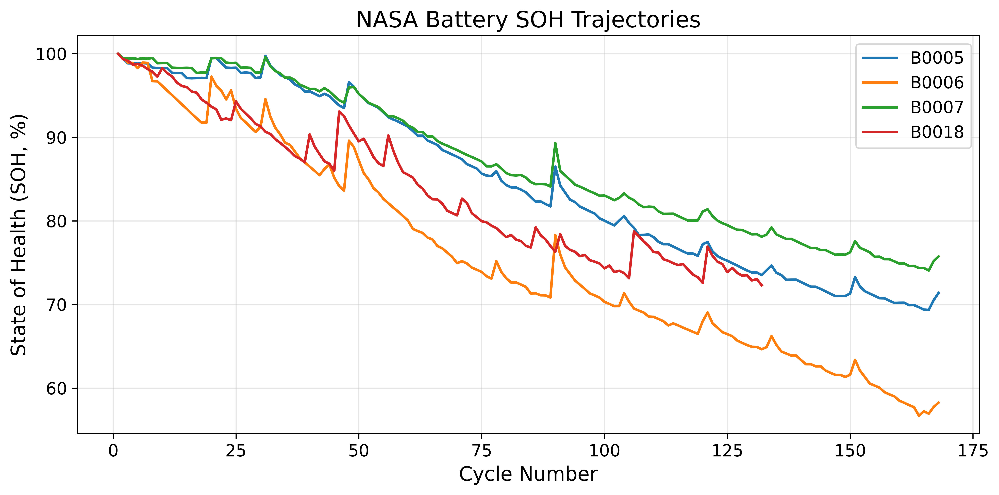

In [193]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for battery, battery_df in df.groupby("Battery"):
    battery_df = battery_df.sort_values("Cycle")
    plt.plot(
        battery_df["Cycle"],
        battery_df["SOH"],
        label=battery,
        linewidth=1.8
    )

plt.xlabel("Cycle Number")
plt.ylabel("State of Health (SOH, %)")
plt.title("NASA Battery SOH Trajectories")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [194]:

# 1. Verify Duration and Cycle statistics by battery
print("DURATION AND CYCLE CHECK")
display(
    df.groupby("Battery").agg(
        Rows=("Cycle", "size"),
        Cycle_Min=("Cycle", "min"),
        Cycle_Max=("Cycle", "max"),
        Cycle_Unique=("Cycle", "nunique"),
        Duration_Min=("Duration", "min"),
        Duration_Max=("Duration", "max"),
        Duration_Unique=("Duration", "nunique")
    )
)

# 2. Check SOH correlations with the current predictors
print("\nCORRELATION WITH SOH")
display(
    df[FEATURES + ["SOH"]]
    .corr(numeric_only=True)["SOH"]
    .drop("SOH")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation_with_SOH")
    .round(4)
)

# 3. Check selected feature ranges by battery
check_features = [
    "AvgVoltage", "AvgCurrent", "AvgTemp",
    "StdTemp", "Duration", "Cycle", "SOH"
]
print("\nMINIMUM AND MAXIMUM BY BATTERY")
display(
    df.groupby("Battery")[check_features]
      .agg(["min", "max"])
      .round(3)
)


DURATION AND CYCLE CHECK


,Rows,Cycle_Min,Cycle_Max,Cycle_Unique,Duration_Min,Duration_Max,Duration_Unique
Battery,,,,,,,
B0005,168,1,168,168,2792.485,3690.234,167
B0006,168,1,168,168,2792.485,3690.234,167
B0007,168,1,168,168,2792.485,3690.234,167
B0018,132,1,132,132,2742.843,3434.891,132



CORRELATION WITH SOH


,Correlation_with_SOH
AvgVoltage,0.9550
Cycle,-0.8943
Duration,0.8885
AvgCurrent,-0.8819
StdTemp,-0.8771
StdCurrent,-0.8238
AvgTemp,-0.5620
MaxTemp,-0.5597
MaxVoltage,0.3127
MinVoltage,-0.2003



MINIMUM AND MAXIMUM BY BATTERY


AvgVoltage        AvgCurrent        AvgTemp         StdTemp         \
               min    max        min    max     min     max     min    max   
Battery                                                                      
B0005        3.464  3.564     -1.939 -1.667  31.330  34.311   3.331  4.453   
B0006        3.404  3.574     -2.000 -1.517  30.762  34.490   3.104  4.528   
B0007        3.458  3.572     -1.979 -1.836  30.885  33.881   3.253  4.443   
B0018        3.445  3.548     -1.954 -1.770  30.103  32.023   3.197  4.094   

         Duration           Cycle          SOH         
              min       max   min  max     min    max  
Battery                                                
B0005    2792.485  3690.234     1  168  69.349  100.0  
B0006    2792.485  3690.234     1  168  56.689  100.0  
B0007    2792.485  3690.234     1  168  74.057  100.0  
B0018    2742.843  3434.891     1  132  72.294  100.0

In [195]:

# Check whether Duration values are identical across batteries
duration_wide = df.pivot(
    index="Cycle",
    columns="Battery",
    values="Duration"
)

print("Duration values by cycle:")
display(duration_wide.head(15).round(4))

for a, b in [
    ("B0005", "B0006"),
    ("B0005", "B0007"),
    ("B0006", "B0007")
]:
    common = duration_wide[[a, b]].dropna()
    differences = (common[a] - common[b]).abs()

    print(
        f"{a} vs {b}: "
        f"identical cycles = {(differences < 1e-9).sum()}/{len(common)}, "
        f"maximum absolute difference = {differences.max():.8f}"
    )


Duration values by cycle:


Battery,B0005,B0006,B0007,B0018
Cycle,,,,
1,3690.234,3690.234,3690.234,3434.891
2,3672.344,3672.344,3672.344,3425.485
3,3651.641,3651.641,3651.641,3410.375
4,3631.563,3631.563,3631.563,3404.719
5,3629.172,3629.172,3629.172,3417.641
6,3652.281,3652.281,3652.281,3411.766
7,3650.828,3650.828,3650.828,3399.516
8,3572.453,3572.453,3572.453,3388.750
9,3550.594,3550.594,3550.594,3380.406


B0005 vs B0006: identical cycles = 168/168, maximum absolute difference = 0.00000000
B0005 vs B0007: identical cycles = 168/168, maximum absolute difference = 0.00000000
B0006 vs B0007: identical cycles = 168/168, maximum absolute difference = 0.00000000


In [ ]:

# Verify Duration in the original master dataframe
duration_check = master_df.pivot(
    index="Cycle",
    columns="Battery",
    values="Duration"
)

for a, b in [
    ("B0005", "B0006"),
    ("B0005", "B0007"),
    ("B0006", "B0007")
]:
    common = duration_check[[a, b]].dropna()
    diff = (common[a] - common[b]).abs()

    print(
        f"{a} vs {b}: "
        f"identical = {(diff < 1e-9).all()}, "
        f"max_difference = {diff.max():.8f}"
    )

print("\nFirst five rows from master_df:")
display(
    master_df.loc[
        master_df["Battery"].isin(["B0005", "B0006", "B0007"]),
        ["Battery", "Cycle", "Duration", "SOH"]
    ].head(15)
)


In [196]:

FEATURES_NO_DURATION = [
    col for col in FEATURES if col != "Duration"
]

X_train_no_duration = train_df[FEATURES_NO_DURATION]
y_train_no_duration = train_df["SOH"]

from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

logo = LeaveOneGroupOut()
groups = train_df["Battery"].to_numpy()
model = HistGradientBoostingRegressor(random_state=42)

results_no_duration = []

for fit_idx, val_idx in logo.split(
    X_train_no_duration, y_train_no_duration, groups
):
    fitted_model = clone(model)
    fitted_model.fit(
        X_train_no_duration.iloc[fit_idx],
        y_train_no_duration.iloc[fit_idx]
    )

    pred = fitted_model.predict(
        X_train_no_duration.iloc[val_idx]
    )
    actual = y_train_no_duration.iloc[val_idx]

    results_no_duration.append({
        "Held_Out_Battery": groups[val_idx][0],
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R2": r2_score(actual, pred)
    })

print(pd.DataFrame(results_no_duration).round(4).to_string(index=False))


Held_Out_Battery    MAE   RMSE     R2
           B0005 2.0290 2.4146 0.9442
           B0006 5.1642 6.0005 0.7638
           B0007 1.7458 2.2300 0.9309


In [197]:
# Check how Duration is represented in the original dataset
print("Columns:", master_df.columns.tolist())

print("\nDuration sample by battery:")
for battery in ["B0005", "B0006", "B0007", "B0018"]:
    subset = master_df[master_df["Battery"] == battery].sort_values("Cycle")
    print(f"\n{battery}")
    print(subset[["Cycle", "Duration"]].head(5).to_string(index=False))

Columns: ['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']

Duration sample by battery:

B0005
 Cycle  Duration
     1  3690.234
     2  3672.344
     3  3651.641
     4  3631.563
     5  3629.172

B0006
 Cycle  Duration
     1  3690.234
     2  3672.344
     3  3651.641
     4  3631.563
     5  3629.172

B0007
 Cycle  Duration
     1  3690.234
     2  3672.344
     3  3651.641
     4  3631.563
     5  3629.172

B0018
 Cycle  Duration
     1  3434.891
     2  3425.485
     3  3410.375
     4  3404.719
     5  3417.641


In [198]:

# ============================================================
# REVIEWER 1 - FOUR-BATTERY LEAVE-ONE-BATTERY-OUT VALIDATION
# DTEC-Net manuscript revision
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# ------------------------------------------------------------
# 1. Prepare the existing dataset
# ------------------------------------------------------------

df_lobo = master_df.copy()

BATTERIES = ["B0005", "B0006", "B0007", "B0018"]
TARGET = "SOH"

FEATURES = [
    "AvgVoltage",
    "MaxVoltage",
    "MinVoltage",
    "StdVoltage",
    "AvgCurrent",
    "StdCurrent",
    "AvgTemp",
    "MaxTemp",
    "MinTemp",
    "StdTemp",
    "Duration",
    "Cycle"
]

required_columns = FEATURES + [TARGET, "Battery"]
missing = [c for c in required_columns if c not in df_lobo.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df_lobo = df_lobo[
    df_lobo["Battery"].isin(BATTERIES)
].copy()

df_lobo = df_lobo.replace([np.inf, -np.inf], np.nan)
df_lobo = df_lobo.dropna(subset=[TARGET, "Battery"])
df_lobo = df_lobo.sort_values(
    ["Battery", "Cycle"]
).reset_index(drop=True)

print("Dataset shape:", df_lobo.shape)
print("\nSamples per battery:")
print(df_lobo.groupby("Battery").size())

print("\nFeatures used:")
print(FEATURES)

# ------------------------------------------------------------
# 2. Define models
# Each model is refitted for every fold and seed.
# ------------------------------------------------------------

SEEDS = [11, 42, 91]

def build_models(seed):
    return {
        "Linear Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LinearRegression()
        ),

        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=300,
                random_state=seed,
                n_jobs=-1
            )
        ),

        "Extra Trees": make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesRegressor(
                n_estimators=300,
                random_state=seed,
                n_jobs=-1
            )
        ),

        "HistGradientBoosting": make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingRegressor(
                random_state=seed
            )
        ),

        "CatBoost": make_pipeline(
            SimpleImputer(strategy="median"),
            CatBoostRegressor(
                iterations=500,
                depth=6,
                learning_rate=0.05,
                loss_function="RMSE",
                random_seed=seed,
                verbose=False,
                thread_count=-1,
                allow_writing_files=False
            )
        ),

        "XGBoost": make_pipeline(
            SimpleImputer(strategy="median"),
            XGBRegressor(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                objective="reg:squarederror",
                random_state=seed,
                n_jobs=-1,
                verbosity=0
            )
        ),

        "LightGBM": make_pipeline(
            SimpleImputer(strategy="median"),
            LGBMRegressor(
                n_estimators=300,
                learning_rate=0.05,
                num_leaves=31,
                random_state=seed,
                n_jobs=-1,
                verbosity=-1
            )
        )
    }

# ------------------------------------------------------------
# 3. Four LOBO folds
# The entire held-out battery is excluded from training.
# ------------------------------------------------------------

results = []
predictions_all = []

for held_out in BATTERIES:

    train_df = df_lobo[
        df_lobo["Battery"] != held_out
    ].copy()

    test_df = df_lobo[
        df_lobo["Battery"] == held_out
    ].copy()

    X_train = train_df[FEATURES]
    y_train = train_df[TARGET].astype(float)

    X_test = test_df[FEATURES]
    y_test = test_df[TARGET].astype(float)

    assert held_out not in train_df["Battery"].unique()

    print(
        f"\nHeld-out: {held_out} | "
        f"Train rows: {len(train_df)} | "
        f"Test rows: {len(test_df)}"
    )

    for seed in SEEDS:
        models = build_models(seed)

        for model_name, model in models.items():

            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_seconds = time.perf_counter() - start_train

            start_inference = time.perf_counter()
            y_pred = model.predict(X_test)
            inference_seconds = time.perf_counter() - start_inference

            mae = mean_absolute_error(y_test, y_pred)
            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mape = mean_absolute_percentage_error(
                y_test, y_pred
            ) * 100
            r2 = r2_score(y_test, y_pred)

            results.append({
                "Model": model_name,
                "Held_Out_Battery": held_out,
                "Seed": seed,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE_percent": mape,
                "R2": r2,
                "Train_Time_seconds": train_seconds,
                "Inference_Time_seconds": inference_seconds,
                "Inference_ms_per_sample":
                    inference_seconds / len(X_test) * 1000
            })

            for cycle, actual, predicted in zip(
                test_df["Cycle"].to_numpy(),
                y_test.to_numpy(),
                y_pred
            ):
                predictions_all.append({
                    "Model": model_name,
                    "Held_Out_Battery": held_out,
                    "Seed": seed,
                    "Cycle": cycle,
                    "Actual_SOH": actual,
                    "Predicted_SOH": predicted
                })

# ------------------------------------------------------------
# 4. Save detailed results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions_all)

results_df.to_csv(
    "LOBO_four_battery_all_runs.csv", index=False
)

predictions_df.to_csv(
    "LOBO_four_battery_predictions.csv", index=False
)

# ------------------------------------------------------------
# 5. Average across seeds within each held-out battery
# Then calculate mean +/- SD across the four batteries.
# This avoids treating repeated seeds as extra batteries.
# ------------------------------------------------------------

metrics = [
    "MAE", "RMSE", "MAPE_percent", "R2",
    "Train_Time_seconds", "Inference_ms_per_sample"
]

per_battery = (
    results_df
    .groupby(["Model", "Held_Out_Battery"])[metrics]
    .mean()
    .reset_index()
)

per_battery.to_csv(
    "LOBO_per_battery_mean_over_seeds.csv",
    index=False
)

summary_rows = []

for model_name, group in per_battery.groupby("Model"):

    row = {"Model": model_name}

    for metric in metrics:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std(ddof=1)

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    "LOBO_four_battery_summary_mean_std.csv",
    index=False
)

print("\n========== PER-BATTERY RESULTS ==========")
display(per_battery.round(4))

print("\n========== FOUR-BATTERY SUMMARY ==========")
display(summary_df.round(4))

print("\nCSV files saved:")
print("1. LOBO_four_battery_all_runs.csv")
print("2. LOBO_four_battery_predictions.csv")
print("3. LOBO_per_battery_mean_over_seeds.csv")
print("4. LOBO_four_battery_summary_mean_std.csv")

Dataset shape: (636, 23)

Samples per battery:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64

Features used:
['AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'Cycle']

Held-out: B0005 | Train rows: 468 | Test rows: 168

Held-out: B0006 | Train rows: 468 | Test rows: 168

Held-out: B0007 | Train rows: 468 | Test rows: 168

Held-out: B0018 | Train rows: 504 | Test rows: 132

========== PER-BATTERY RESULTS ==========


,Model,Held_Out_Battery,MAE,RMSE,MAPE_percent,R2,Train_Time_seconds,Inference_ms_per_sample
0,CatBoost,B0005,2.0503,2.4171,2.3468,0.9438,0.8478,0.0212
1,CatBoost,B0006,6.9299,7.6286,9.9845,0.6178,0.8361,0.0202
2,CatBoost,B0007,3.1680,3.7730,3.4843,0.8017,0.8419,0.0205
3,CatBoost,B0018,1.7277,2.1641,2.0060,0.9320,0.8485,0.0258
4,Extra Trees,B0005,1.2063,1.5191,1.3960,0.9779,0.4218,0.6829
5,Extra Trees,B0006,6.6546,7.1307,9.4474,0.6664,0.4268,0.6748
6,Extra Trees,B0007,1.5355,2.0549,1.6674,0.9413,0.4238,0.6735
7,Extra Trees,B0018,1.7352,2.2126,1.9632,0.9292,0.4292,0.8499
8,HistGradientBoosting,B0005,2.1448,2.4225,2.6629,0.9439,0.1898,0.0275
9,HistGradientBoosting,B0006,7.5735,8.0059,10.6101,0.5795,0.1929,0.0311



========== FOUR-BATTERY SUMMARY ==========


,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_percent_mean,MAPE_percent_std,R2_mean,R2_std,Train_Time_seconds_mean,Train_Time_seconds_std,Inference_ms_per_sample_mean,Inference_ms_per_sample_std
0,CatBoost,3.4690,2.3884,3.9957,2.5229,4.4554,3.7399,0.8238,0.1517,0.8435,0.0058,0.0219,0.0026
1,Extra Trees,2.7829,2.5903,3.2293,2.6178,3.6185,3.8928,0.8787,0.1431,0.4254,0.0033,0.7203,0.0865
2,HistGradientBoosting,3.1819,2.9437,3.6473,2.9128,4.1600,4.3251,0.8499,0.1805,0.1928,0.0026,0.0289,0.0029
3,LightGBM,3.1569,2.8632,3.6717,2.8073,4.1342,4.2141,0.8501,0.1714,0.1583,0.0176,0.0309,0.0040
4,Linear Regression,3.7133,2.2490,3.9645,2.1362,4.6469,3.0441,0.7978,0.1719,0.0064,0.0006,0.0128,0.0019
5,Random Forest,3.0396,3.1158,3.4856,3.1147,3.9783,4.5374,0.8542,0.1932,0.7575,0.0300,0.7239,0.1117
6,XGBoost,3.0822,2.7515,3.5287,2.7350,4.0328,4.0760,0.8584,0.1609,0.2903,0.0067,0.0304,0.0042



CSV files saved:
1. LOBO_four_battery_all_runs.csv
2. LOBO_four_battery_predictions.csv
3. LOBO_per_battery_mean_over_seeds.csv
4. LOBO_four_battery_summary_mean_std.csv


In [199]:

# ============================================================
# REVIEWER 1: DTEC-Net — FOUR-BATTERY LOBO VALIDATION
# Batteries: B0005, B0006, B0007, B0018
# Seeds: 11, 42, 91
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras import backend as K

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEEDS = [11, 42, 91]
BATTERIES = ["B0005", "B0006", "B0007", "B0018"]

# Use the same feature configuration as the notebook's
# DTEC-Net/LSTM experiment.
FEATURES_DTEC = [
    "AvgVoltage",
    "MaxVoltage",
    "AvgCurrent",
    "AvgTemp",
    "Duration",
    "Cycle",
    "DI",
    "TSI",
    "VHI",
    "TGI",
    "VSI",
    "DTHI_v2"
]

TARGET_DTEC = "SOH"

OUTPUT_DIR = "/kaggle/working/DTECNet_LOBO"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Validate and prepare data
# ------------------------------------------------------------

df_lobo = master_df.copy()

# Ensure DTHI_v2 exists, following the formula in the notebook.
if "DTHI_v2" not in df_lobo.columns:
    if "TGI_norm" not in df_lobo.columns:
        df_lobo["TGI_norm"] = (
            df_lobo["TGI"] / df_lobo["TGI"].max()
        )

    df_lobo["DTHI_v2"] = (
        0.30 * df_lobo["DI"]
        + 0.25 * (1 - df_lobo["VHI"])
        + 0.20 * df_lobo["TSI"]
        + 0.15 * df_lobo["TGI_norm"]
        + 0.10 * (1 - df_lobo["VSI"])
    )

required = FEATURES_DTEC + [TARGET_DTEC, "Battery", "Cycle"]
missing = [c for c in required if c not in df_lobo.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df_lobo = df_lobo[
    df_lobo["Battery"].isin(BATTERIES)
].copy()

df_lobo = df_lobo.replace([np.inf, -np.inf], np.nan)
df_lobo = df_lobo.dropna(
    subset=FEATURES_DTEC + [TARGET_DTEC]
)
df_lobo = df_lobo.sort_values(
    ["Battery", "Cycle"]
).reset_index(drop=True)

print("Rows by battery:")
print(df_lobo.groupby("Battery").size())

print("\nFeatures:", FEATURES_DTEC)

# ------------------------------------------------------------
# 3. LOBO: each battery held out in turn
# ------------------------------------------------------------

results = []
prediction_rows = []

for held_out in BATTERIES:

    train_df = df_lobo[
        df_lobo["Battery"] != held_out
    ].copy()

    test_df = df_lobo[
        df_lobo["Battery"] == held_out
    ].copy()

    if train_df.empty or test_df.empty:
        raise ValueError(
            f"Empty training or test data for {held_out}"
        )

    X_train_raw = train_df[FEATURES_DTEC].to_numpy(
        dtype=np.float32
    )
    X_test_raw = test_df[FEATURES_DTEC].to_numpy(
        dtype=np.float32
    )

    y_train_raw = train_df[[TARGET_DTEC]].to_numpy(
        dtype=np.float32
    )
    y_test_raw = test_df[[TARGET_DTEC]].to_numpy(
        dtype=np.float32
    )

    for seed in SEEDS:

        print(
            f"\nHeld-out battery: {held_out} | Seed: {seed}"
        )

        # Reset model state and random seeds for reproducibility.
        K.clear_session()
        random.seed(seed)
        np.random.seed(seed)
        tf.keras.utils.set_random_seed(seed)

        # Fit scalers on training data only.
        scaler_x = MinMaxScaler()
        scaler_y = MinMaxScaler()

        X_train = scaler_x.fit_transform(X_train_raw)
        X_test = scaler_x.transform(X_test_raw)

        y_train = scaler_y.fit_transform(y_train_raw)

        # LSTM input shape: samples, timesteps, features.
        X_train = X_train.reshape(
            X_train.shape[0], 1, X_train.shape[1]
        )
        X_test = X_test.reshape(
            X_test.shape[0], 1, X_test.shape[1]
        )

        # Reproduce the notebook's LSTM architecture.
        model = Sequential([
            tf.keras.Input(
                shape=(1, len(FEATURES_DTEC))
            ),
            LSTM(64, return_sequences=False),
            Dropout(0.2),
            Dense(32, activation="relu"),
            Dense(1)
        ])

        model.compile(
            optimizer="adam",
            loss="mse",
            metrics=["mae"]
        )

        # Measure training time.
        start_train = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            epochs=100,
            batch_size=32,
            validation_split=0.2,
            shuffle=False,
            verbose=0
        )

        train_seconds = time.perf_counter() - start_train

        # Warm-up prediction, then time inference.
        _ = model.predict(X_test[:1], verbose=0)

        start_inference = time.perf_counter()
        pred_scaled = model.predict(X_test, verbose=0)
        inference_seconds = (
            time.perf_counter() - start_inference
        )

        # Return predictions and targets to original SOH scale.
        y_pred = scaler_y.inverse_transform(
            pred_scaled
        ).ravel()

        y_true = y_test_raw.ravel()

        # Metrics for this held-out battery and seed.
        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(
            mean_squared_error(y_true, y_pred)
        )

        # Guard against division by zero in MAPE.
        nonzero = np.abs(y_true) > 1e-12
        mape = (
            np.mean(
                np.abs(
                    (y_true[nonzero] - y_pred[nonzero])
                    / y_true[nonzero]
                )
            ) * 100
            if nonzero.any()
            else np.nan
        )

        r2 = (
            r2_score(y_true, y_pred)
            if len(y_true) > 1
            else np.nan
        )

        results.append({
            "Model": "DTEC-Net LSTM",
            "Held_Out_Battery": held_out,
            "Seed": seed,
            "N_Test": len(y_true),
            "MAE": mae,
            "RMSE": rmse,
            "MAPE_percent": mape,
            "R2": r2,
            "Train_Time_seconds": train_seconds,
            "Inference_ms_per_sample": (
                inference_seconds / len(y_true) * 1000
            )
        })

        prediction_rows.append(pd.DataFrame({
            "Battery": held_out,
            "Seed": seed,
            "Cycle": test_df["Cycle"].to_numpy(),
            "SOH_Actual": y_true,
            "SOH_Predicted": y_pred
        }))

        print(
            f"MAE={mae:.4f}, RMSE={rmse:.4f}, "
            f"MAPE={mape:.4f}%, R2={r2:.4f}"
        )

# ------------------------------------------------------------
# 4. Save detailed results
# ------------------------------------------------------------

runs_df = pd.DataFrame(results)

runs_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "DTECNet_LOBO_all_runs.csv"
    ),
    index=False
)

predictions_df = pd.concat(
    prediction_rows, ignore_index=True
)

predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "DTECNet_LOBO_predictions.csv"
    ),
    index=False
)

# First average repeated seeds within each held-out battery.
per_battery = (
    runs_df.groupby(
        ["Model", "Held_Out_Battery"]
    )[
        [
            "MAE", "RMSE", "MAPE_percent", "R2",
            "Train_Time_seconds",
            "Inference_ms_per_sample"
        ]
    ]
    .mean()
    .reset_index()
)

per_battery.to_csv(
    os.path.join(
        OUTPUT_DIR, "DTECNet_LOBO_per_battery.csv"
    ),
    index=False
)

# Then report mean and SD across the four held-out batteries.
metric_columns = [
    "MAE", "RMSE", "MAPE_percent", "R2",
    "Train_Time_seconds", "Inference_ms_per_sample"
]

summary = (
    per_battery.groupby("Model")[metric_columns]
    .agg(["mean", "std"])
    .round(4)
)

summary.to_csv(
    os.path.join(
        OUTPUT_DIR, "DTECNet_LOBO_summary_mean_std.csv"
    )
)

print("\n========== DTEC-Net PER-BATTERY RESULTS ==========")
print(per_battery.round(4).to_string(index=False))

print("\n========== DTEC-Net LOBO SUMMARY: MEAN ± SD ==========")
print(summary)

print("\nSaved output files to:", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))


Rows by battery:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64

Features: ['AvgVoltage', 'MaxVoltage', 'AvgCurrent', 'AvgTemp', 'Duration', 'Cycle', 'DI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI_v2']

Held-out battery: B0005 | Seed: 11
MAE=1.2729, RMSE=1.4524, MAPE=1.5547%, R2=0.9798

Held-out battery: B0005 | Seed: 42
MAE=1.1600, RMSE=1.4844, MAPE=1.2854%, R2=0.9789

Held-out battery: B0005 | Seed: 91
MAE=1.5376, RMSE=1.8043, MAPE=1.9465%, R2=0.9689

Held-out battery: B0006 | Seed: 11
MAE=3.2560, RMSE=3.7774, MAPE=4.5325%, R2=0.9064

Held-out battery: B0006 | Seed: 42
MAE=3.9406, RMSE=4.5348, MAPE=5.5212%, R2=0.8651

Held-out battery: B0006 | Seed: 91
MAE=3.9996, RMSE=4.6227, MAPE=5.6269%, R2=0.8598

Held-out battery: B0007 | Seed: 11
MAE=3.0127, RMSE=3.9133, MAPE=3.7579%, R2=0.7873

Held-out battery: B0007 | Seed: 42
MAE=3.1756, RMSE=4.0875, MAPE=3.9521%, R2=0.7680

Held-out battery: B0007 | Seed: 91
MAE=3.7824, RMSE=4.6113, MAPE=4.6618%, R2=0.7047

Held-out batt

In [200]:
# ============================================================
# REVIEWER 1 — CONTROLLED HYPERPARAMETER OPTIMIZATION
# Separate experiment; does not modify earlier notebook cells
# ============================================================

import os
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import ParameterSampler, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

# -----------------------------
# A. Independent configuration
# -----------------------------
HPO_BATTERIES = ["B0005", "B0006", "B0007", "B0018"]

HPO_FEATURES = [
    "AvgVoltage", "MaxVoltage", "MinVoltage", "StdVoltage",
    "AvgCurrent", "StdCurrent", "AvgTemp", "MaxTemp", "MinTemp",
    "StdTemp", "Duration", "Cycle"
]

HPO_TARGET = "SOH"
HPO_SEEDS = [11, 42, 91]
HPO_N_ITER = 30
HPO_SEARCH_SEED = 2026

HPO_OUTPUT_DIR = "/kaggle/working/Baseline_Hyperparameter_Optimization"
os.makedirs(HPO_OUTPUT_DIR, exist_ok=True)

# Use a separate copy; do not modify master_df.
hpo_df = master_df.copy()

hpo_required = HPO_FEATURES + [HPO_TARGET, "Battery"]
hpo_missing = [c for c in hpo_required if c not in hpo_df.columns]

if hpo_missing:
    raise ValueError(f"Missing columns required for HPO: {hpo_missing}")

hpo_df = hpo_df[hpo_df["Battery"].isin(HPO_BATTERIES)].copy()
hpo_df = hpo_df.replace([np.inf, -np.inf], np.nan)
hpo_df = hpo_df.dropna(subset=[HPO_TARGET, "Battery"])
hpo_df = hpo_df.sort_values(["Battery", "Cycle"]).reset_index(drop=True)

if set(hpo_df["Battery"].unique()) != set(HPO_BATTERIES):
    raise ValueError("One or more expected batteries are missing from master_df.")

print("HPO dataset shape:", hpo_df.shape)
print("Rows by battery:")
print(hpo_df.groupby("Battery").size().to_string())
print("Features:", HPO_FEATURES)
print("Search budget:", HPO_N_ITER, "configurations/model/outer fold")


# -----------------------------
# B. Hyperparameter search spaces
# -----------------------------
HPO_SEARCH_SPACES = {
    "Random Forest": {
        "model__n_estimators": [200, 300, 500, 700],
        "model__max_depth": [None, 5, 8, 12, 16, 24],
        "model__min_samples_split": [2, 4, 6, 10],
        "model__min_samples_leaf": [1, 2, 3, 5],
        "model__max_features": [1.0, "sqrt", 0.7, 0.9],
    },
    "XGBoost": {
        "model__n_estimators": [200, 300, 500, 700],
        "model__max_depth": [2, 3, 4, 5, 6, 8],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "model__subsample": [0.7, 0.8, 0.9, 1.0],
        "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
        "model__reg_lambda": [0.1, 1.0, 3.0, 10.0],
    },
    "LightGBM": {
        "model__n_estimators": [200, 300, 500, 700],
        "model__num_leaves": [7, 15, 31, 47, 63],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [-1, 3, 5, 7, 10],
        "model__min_child_samples": [5, 10, 15, 20, 30],
        "model__reg_lambda": [0.0, 0.1, 1.0, 5.0, 10.0],
    },
    "CatBoost": {
        "model__iterations": [200, 300, 500, 700],
        "model__depth": [4, 5, 6, 7, 8, 10],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "model__l2_leaf_reg": [1.0, 3.0, 5.0, 7.0, 10.0],
        "model__random_strength": [0.0, 0.5, 1.0, 2.0],
    },
}


def hpo_make_pipeline(model_name, params=None, seed=42):
    """Create a fresh model pipeline using the specified parameters."""

    if model_name == "Random Forest":
        estimator = RandomForestRegressor(
            random_state=seed, n_jobs=-1
        )

    elif model_name == "XGBoost":
        estimator = XGBRegressor(
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=seed,
            n_jobs=-1,
            verbosity=0
        )

    elif model_name == "LightGBM":
        estimator = LGBMRegressor(
            objective="regression",
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        )

    elif model_name == "CatBoost":
        estimator = CatBoostRegressor(
            loss_function="RMSE",
            random_seed=seed,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator),
    ])

    if params:
        pipe.set_params(**params)

    return pipe


def hpo_rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


# -----------------------------
# C. Nested battery-wise LOBO
# -----------------------------
hpo_outer_rows = []
hpo_inner_rows = []
hpo_prediction_rows = []
hpo_selected_rows = []

for outer_fold, outer_held_out in enumerate(HPO_BATTERIES, start=1):

    hpo_outer_train = hpo_df[
        hpo_df["Battery"] != outer_held_out
    ].copy()

    hpo_outer_test = hpo_df[
        hpo_df["Battery"] == outer_held_out
    ].copy()

    X_outer_train = hpo_outer_train[HPO_FEATURES]
    y_outer_train = hpo_outer_train[HPO_TARGET]

    X_outer_test = hpo_outer_test[HPO_FEATURES]
    y_outer_test = hpo_outer_test[HPO_TARGET].to_numpy()

    inner_groups = hpo_outer_train["Battery"].to_numpy()

    print(
        f"\n========== OUTER FOLD {outer_fold}/4: "
        f"held out {outer_held_out} =========="
    )

    for model_index, model_name in enumerate(HPO_SEARCH_SPACES):

        sampled_params = list(ParameterSampler(
            HPO_SEARCH_SPACES[model_name],
            n_iter=HPO_N_ITER,
            random_state=HPO_SEARCH_SEED + outer_fold * 100 + model_index
        ))

        candidate_scores = []

        # Inner validation holds out each of the three outer-training
        # batteries in turn. The outer test battery is never used
        # for hyperparameter selection.
        for candidate_id, candidate_params in enumerate(
            sampled_params, start=1
        ):

            inner_fold_rmses = []

            for inner_train_idx, inner_val_idx in LeaveOneGroupOut().split(
                X_outer_train,
                y_outer_train,
                groups=inner_groups
            ):

                X_inner_train = X_outer_train.iloc[inner_train_idx]
                y_inner_train = y_outer_train.iloc[inner_train_idx]

                X_inner_val = X_outer_train.iloc[inner_val_idx]
                y_inner_val = y_outer_train.iloc[inner_val_idx]

                inner_val_battery = (
                    hpo_outer_train.iloc[inner_val_idx]["Battery"].iloc[0]
                )

                inner_model = hpo_make_pipeline(
                    model_name,
                    candidate_params,
                    seed=HPO_SEARCH_SEED
                )

                inner_model.fit(X_inner_train, y_inner_train)
                inner_pred = inner_model.predict(X_inner_val)

                inner_rmse = hpo_rmse(y_inner_val, inner_pred)
                inner_fold_rmses.append(inner_rmse)

                hpo_inner_rows.append({
                    "Outer_Held_Out_Battery": outer_held_out,
                    "Model": model_name,
                    "Candidate_ID": candidate_id,
                    "Inner_Validation_Battery": inner_val_battery,
                    "Inner_RMSE": inner_rmse,
                    "Parameters": repr(candidate_params),
                })

            mean_inner_rmse = float(np.mean(inner_fold_rmses))

            candidate_scores.append(
                (mean_inner_rmse, candidate_params)
            )

        candidate_scores.sort(key=lambda x: x[0])
        best_inner_rmse, best_params = candidate_scores[0]

        hpo_selected_rows.append({
            "Outer_Held_Out_Battery": outer_held_out,
            "Model": model_name,
            "Best_Inner_Mean_RMSE": best_inner_rmse,
            "Selected_Parameters": repr(best_params),
            "Candidates_Evaluated": len(sampled_params),
            "Inner_Folds_Per_Candidate": len(HPO_BATTERIES) - 1,
        })

        print(
            f"{model_name}: best inner RMSE={best_inner_rmse:.4f}; "
            f"selected {best_params}"
        )

        # Evaluate selected configuration on the untouched outer battery.
        for seed in HPO_SEEDS:

            final_model = hpo_make_pipeline(
                model_name,
                best_params,
                seed=seed
            )

            start_fit = time.perf_counter()
            final_model.fit(X_outer_train, y_outer_train)
            train_seconds = time.perf_counter() - start_fit

            start_pred = time.perf_counter()
            y_pred = final_model.predict(X_outer_test)
            pred_seconds = time.perf_counter() - start_pred

            mae = float(mean_absolute_error(y_outer_test, y_pred))
            rmse = hpo_rmse(y_outer_test, y_pred)

            nonzero = np.abs(y_outer_test) > 1e-12

            mape = (
                float(np.mean(np.abs(
                    (
                        y_outer_test[nonzero]
                        - y_pred[nonzero]
                    ) / y_outer_test[nonzero]
                )) * 100)
                if nonzero.any()
                else np.nan
            )

            r2 = (
                float(r2_score(y_outer_test, y_pred))
                if len(y_outer_test) > 1
                else np.nan
            )

            hpo_outer_rows.append({
                "Model": model_name,
                "Outer_Held_Out_Battery": outer_held_out,
                "Seed": seed,
                "N_Test": len(y_outer_test),
                "MAE": mae,
                "RMSE": rmse,
                "MAPE_percent": mape,
                "R2": r2,
                "Train_Time_seconds": train_seconds,
                "Inference_ms_per_sample": (
                    pred_seconds / max(len(y_outer_test), 1) * 1000
                ),
                "Best_Inner_Mean_RMSE": best_inner_rmse,
                "Selected_Parameters": repr(best_params),
            })

            hpo_prediction_rows.append(pd.DataFrame({
                "Model": model_name,
                "Outer_Held_Out_Battery": outer_held_out,
                "Seed": seed,
                "Cycle": hpo_outer_test["Cycle"].to_numpy(),
                "SOH_Actual": y_outer_test,
                "SOH_Predicted": y_pred,
            }))


# -----------------------------
# D. Export detailed and summary results
# -----------------------------
hpo_runs_df = pd.DataFrame(hpo_outer_rows)
hpo_inner_df = pd.DataFrame(hpo_inner_rows)
hpo_selected_df = pd.DataFrame(hpo_selected_rows)

hpo_predictions_df = pd.concat(
    hpo_prediction_rows,
    ignore_index=True
)

hpo_runs_df.to_csv(
    os.path.join(HPO_OUTPUT_DIR, "HPO_baseline_all_runs.csv"),
    index=False
)

hpo_inner_df.to_csv(
    os.path.join(HPO_OUTPUT_DIR, "HPO_inner_validation_scores.csv"),
    index=False
)

hpo_selected_df.to_csv(
    os.path.join(HPO_OUTPUT_DIR, "HPO_selected_hyperparameters.csv"),
    index=False
)

hpo_predictions_df.to_csv(
    os.path.join(HPO_OUTPUT_DIR, "HPO_outer_predictions.csv"),
    index=False
)

hpo_metrics = [
    "MAE", "RMSE", "MAPE_percent", "R2",
    "Train_Time_seconds", "Inference_ms_per_sample"
]

# Average seeds within each held-out battery first, then summarize
# across the four held-out batteries.
hpo_per_battery = (
    hpo_runs_df.groupby(
        ["Model", "Outer_Held_Out_Battery"]
    )[hpo_metrics]
    .mean()
    .reset_index()
)

hpo_per_battery.to_csv(
    os.path.join(
        HPO_OUTPUT_DIR,
        "HPO_per_battery_mean_over_seeds.csv"
    ),
    index=False
)

hpo_summary_rows = []

for hpo_model_name, hpo_group in hpo_per_battery.groupby("Model"):

    hpo_row = {"Model": hpo_model_name}

    for hpo_metric in hpo_metrics:
        hpo_row[f"{hpo_metric}_mean"] = hpo_group[hpo_metric].mean()
        hpo_row[f"{hpo_metric}_std"] = hpo_group[hpo_metric].std(ddof=1)

    hpo_summary_rows.append(hpo_row)

hpo_summary_df = pd.DataFrame(
    hpo_summary_rows
).sort_values("RMSE_mean")

hpo_summary_df.to_csv(
    os.path.join(HPO_OUTPUT_DIR, "HPO_summary_mean_std.csv"),
    index=False
)

print("\n========== SELECTED HYPERPARAMETERS ==========")
print(hpo_selected_df.to_string(index=False))

print("\n========== PER-BATTERY MEAN OVER SEEDS ==========")
print(hpo_per_battery.round(4).to_string(index=False))

print("\n========== SUMMARY: MEAN ± SD ACROSS FOUR BATTERIES ==========")
print(hpo_summary_df.round(4).to_string(index=False))

print("\nSaved outputs to:", HPO_OUTPUT_DIR)
print(sorted(os.listdir(HPO_OUTPUT_DIR)))

HPO dataset shape: (636, 23)
Rows by battery:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
Features: ['AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'Cycle']
Search budget: 30 configurations/model/outer fold

========== OUTER FOLD 1/4: held out B0005 ==========
Random Forest: best inner RMSE=5.1356; selected {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.9, 'model__max_depth': None}
XGBoost: best inner RMSE=4.5996; selected {'model__subsample': 0.7, 'model__reg_lambda': 0.1, 'model__n_estimators': 700, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.9}
LightGBM: best inner RMSE=4.8100; selected {'model__reg_lambda': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 500, 'model__min_child_samples': 30, 'model__max_depth': 7, 'model__learning_rate': 0.08}
CatBoost: best inner RMS

In [204]:

# ================================================================
# DTEC-Net PAPER: DEEP LEARNING BASELINE COMPARISON
# LSTM vs CNN-LSTM vs Transformer
# Four-battery LOBO, seeds 11, 42, 91
# Target: SOH
# ================================================================

import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------ CONFIGURATION --------------------------

MASTER_PATH = (
    "/kaggle/input/datasets/prksh830/nasa-dtec/"
    "NASA_Battery_Master.csv"
)

BATTERIES = ["B0005", "B0006", "B0007", "B0018"]
SEEDS = [11, 42, 91]

TARGET_COL = "SOH"
BATTERY_COL = "Battery"
CYCLE_COL = "Cycle"

# DTHI_v2 is absent from the CSV, so do not silently replace it.
FEATURES = [
    "AvgVoltage", "MaxVoltage", "AvgCurrent", "AvgTemp",
    "Duration", "Cycle", "DI", "TSI", "VHI", "TGI", "VSI"
]

WINDOW_SIZE = 10
EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 1e-3

# ------------------------ LOAD DATA ------------------------------

df = pd.read_csv(MASTER_PATH)

required = [BATTERY_COL, CYCLE_COL, TARGET_COL] + FEATURES
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[df[BATTERY_COL].isin(BATTERIES)].copy()
df = df.sort_values([BATTERY_COL, CYCLE_COL]).reset_index(drop=True)

if df[required].isna().any().any():
    raise ValueError("Missing values found in required columns.")

print("Loaded data:", df.shape)
print("Battery counts:")
print(df[BATTERY_COL].value_counts().sort_index())

print("\nFeatures used:", FEATURES)
print("Target:", TARGET_COL)
print("Window size:", WINDOW_SIZE)

# ------------------------ METRICS --------------------------------

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # SOH values are positive; guard against division by zero.
    nonzero = np.abs(y_true) > 1e-8
    mape = (
        np.mean(
            np.abs((y_true[nonzero] - y_pred[nonzero]) /
                   y_true[nonzero])
        ) * 100
        if nonzero.any() else np.nan
    )

    r2 = r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "R2": r2
    }

# ------------------------ SEQUENCES ------------------------------

def make_sequences(X, y, window_size):
    X_seq, y_seq = [], []

    for i in range(window_size - 1, len(X)):
        X_seq.append(X[i - window_size + 1:i + 1])
        y_seq.append(y[i])

    return np.asarray(X_seq, dtype=np.float32), np.asarray(
        y_seq, dtype=np.float32
    )

# ------------------------ MODEL DEFINITIONS ----------------------

def build_lstm(input_shape):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.LSTM(64)(inputs)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    outputs = tf.keras.layers.Dense(1)(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
        loss="mse"
    )
    return model


def build_cnn_lstm(input_shape):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Conv1D(
        filters=32, kernel_size=3, padding="causal", activation="relu"
    )(inputs)
    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)
    x = tf.keras.layers.LSTM(64)(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    outputs = tf.keras.layers.Dense(1)(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
        loss="mse"
    )
    return model


def build_transformer(input_shape):
    inputs = tf.keras.Input(shape=input_shape)

    x = tf.keras.layers.Dense(64)(inputs)

    # Learnable position embeddings for the fixed-length window.
    positions = tf.range(start=0, limit=input_shape[0], delta=1)
    position_embedding = tf.keras.layers.Embedding(
        input_dim=input_shape[0], output_dim=64
    )(positions)
    x = x + position_embedding

    attention = tf.keras.layers.MultiHeadAttention(
        num_heads=4, key_dim=16, dropout=0.1
    )(x, x)

    x = tf.keras.layers.LayerNormalization()(x + attention)

    ff = tf.keras.layers.Dense(128, activation="relu")(x)
    ff = tf.keras.layers.Dropout(0.1)(ff)
    ff = tf.keras.layers.Dense(64)(ff)

    x = tf.keras.layers.LayerNormalization()(x + ff)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    outputs = tf.keras.layers.Dense(1)(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
        loss="mse"
    )
    return model


MODEL_BUILDERS = {
    "LSTM": build_lstm,
    "CNN-LSTM": build_cnn_lstm,
    "Transformer": build_transformer
}

# ------------------------ LOBO EXPERIMENT ------------------------

results = []

for held_out_battery in BATTERIES:
    print("\n" + "=" * 70)
    print("HELD-OUT BATTERY:", held_out_battery)
    print("=" * 70)

    train_df = df[df[BATTERY_COL] != held_out_battery].copy()
    test_df = df[df[BATTERY_COL] == held_out_battery].copy()

    train_df = train_df.sort_values(CYCLE_COL)
    test_df = test_df.sort_values(CYCLE_COL)

    # Fit the scaler on training rows only.
    scaler = StandardScaler()
    scaler.fit(train_df[FEATURES].to_numpy())

    # Transform each battery independently, preserving cycle order.
    X_train_all, y_train_all = [], []

    for battery in BATTERIES:
        if battery == held_out_battery:
            continue

        part = train_df[train_df[BATTERY_COL] == battery].sort_values(
            CYCLE_COL
        )

        X_part = scaler.transform(part[FEATURES].to_numpy())
        y_part = part[TARGET_COL].to_numpy(dtype=np.float32)

        X_seq, y_seq = make_sequences(X_part, y_part, WINDOW_SIZE)

        X_train_all.append(X_seq)
        y_train_all.append(y_seq)

    X_train = np.concatenate(X_train_all, axis=0)
    y_train = np.concatenate(y_train_all, axis=0)

    X_test_scaled = scaler.transform(test_df[FEATURES].to_numpy())
    y_test_all = test_df[TARGET_COL].to_numpy(dtype=np.float32)

    X_test, y_test = make_sequences(
        X_test_scaled, y_test_all, WINDOW_SIZE
    )

    print("Training sequences:", X_train.shape)
    print("Test sequences:", X_test.shape)

    for seed in SEEDS:
        for model_name, builder in MODEL_BUILDERS.items():
            print(f"\nTraining {model_name} | seed={seed}")

            tf.keras.backend.clear_session()
            random.seed(seed)
            np.random.seed(seed)
            tf.random.set_seed(seed)

            model = builder(
                input_shape=(WINDOW_SIZE, len(FEATURES))
            )

            start = time.perf_counter()

            model.fit(
                X_train,
                y_train,
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                shuffle=True,
                verbose=0
            )

            train_seconds = time.perf_counter() - start

            start = time.perf_counter()
            predictions = model.predict(X_test, verbose=0).reshape(-1)
            inference_ms_per_sample = (
                (time.perf_counter() - start) * 1000 / len(X_test)
            )

            metrics = calculate_metrics(y_test, predictions)

            row = {
                "Held-out Battery": held_out_battery,
                "Model": model_name,
                "Seed": seed,
                **metrics,
                "Training Time (s)": train_seconds,
                "Inference (ms/sample)": inference_ms_per_sample,
                "Train Sequences": len(X_train),
                "Test Sequences": len(X_test)
            }

            results.append(row)

            print(
                f"MAE={metrics['MAE']:.4f} | "
                f"RMSE={metrics['RMSE']:.4f} | "
                f"MAPE={metrics['MAPE (%)']:.4f}% | "
                f"R2={metrics['R2']:.4f}"
            )

# ------------------------ SAVE AND SUMMARIZE ---------------------

results_df = pd.DataFrame(results)

print("\n\n=== Detailed LOBO Results ===")
display(results_df.round(4))

summary_df = (
    results_df.groupby("Model")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "MAPE (%)": ["mean", "std"],
        "R2": ["mean", "std"],
        "Training Time (s)": ["mean", "std"],
        "Inference (ms/sample)": ["mean", "std"]
    })
)

print("\n=== Overall Model Summary ===")
display(summary_df.round(4))

results_df.to_csv(
    "/kaggle/working/dl_baseline_lobo_detailed.csv",
    index=False
)
summary_df.to_csv(
    "/kaggle/working/dl_baseline_lobo_summary.csv"
)

print("\nSaved:")
print("/kaggle/working/dl_baseline_lobo_detailed.csv")
print("/kaggle/working/dl_baseline_lobo_summary.csv")

Loaded data: (636, 23)
Battery counts:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64

Features used: ['AvgVoltage', 'MaxVoltage', 'AvgCurrent', 'AvgTemp', 'Duration', 'Cycle', 'DI', 'TSI', 'VHI', 'TGI', 'VSI']
Target: SOH
Window size: 10

HELD-OUT BATTERY: B0005
Training sequences: (441, 10, 11)
Test sequences: (159, 10, 11)

Training LSTM | seed=11
MAE=39.7701 | RMSE=44.7837 | MAPE=48.4754% | R2=-19.3873

Training CNN-LSTM | seed=11
MAE=12.1790 | RMSE=15.3114 | MAPE=13.4204% | R2=-1.3831

Training Transformer | seed=11
MAE=9.2448 | RMSE=10.5290 | MAPE=10.6821% | R2=-0.1269

Training LSTM | seed=42
MAE=52.8042 | RMSE=53.0179 | MAPE=63.3839% | R2=-27.5736

Training CNN-LSTM | seed=42
MAE=10.4095 | RMSE=12.9702 | MAPE=11.5643% | R2=-0.7101

Training Transformer | seed=42
MAE=9.6029 | RMSE=10.9549 | MAPE=11.0550% | R2=-0.2199

Training LSTM | seed=91
MAE=12.6857 | RMSE=15.9404 | MAPE=13.9735% | R2=-1.5830

Training CNN-LSTM | seed=91
MAE=12.0519 | R

,Held-out Battery,Model,Seed,MAE,RMSE,MAPE (%),R2,Training Time (s),Inference (ms/sample),Train Sequences,Test Sequences
0,B0005,LSTM,11,39.7701,44.7837,48.475399,-19.3873,3.1469,2.4486,441,159
1,B0005,CNN-LSTM,11,12.1790,15.3114,13.420400,-1.3831,3.3247,2.7992,441,159
2,B0005,Transformer,11,9.2448,10.5290,10.682100,-0.1269,5.8725,2.5220,441,159
3,B0005,LSTM,42,52.8042,53.0179,63.383999,-27.5736,3.1352,2.5152,441,159
4,B0005,CNN-LSTM,42,10.4095,12.9702,11.564300,-0.7101,3.3307,2.7821,441,159
5,B0005,Transformer,42,9.6029,10.9549,11.055000,-0.2199,5.7855,2.5487,441,159
6,B0005,LSTM,91,12.6857,15.9404,13.973500,-1.5830,3.2269,2.4802,441,159
7,B0005,CNN-LSTM,91,12.0519,15.1658,13.279800,-1.3380,3.3202,2.7598,441,159
8,B0005,Transformer,91,8.2780,9.6239,9.492000,0.0585,5.8072,2.5180,441,159
9,B0006,LSTM,11,9.0868,11.2211,11.830900,0.0358,3.1338,2.5667,441,159



=== Overall Model Summary ===


MAE              RMSE            MAPE (%)             \
                mean      std     mean      std       mean        std   
Model                                                                   
CNN-LSTM     10.6615   2.2204  12.9714   2.4135  12.449900   2.432300   
LSTM         30.1594  18.1854  32.0781  17.7827  36.155602  22.019501   
Transformer   8.7659   2.6535  10.3696   2.8843  10.961500   4.661500   

                  R2          Training Time (s)         Inference (ms/sample)  \
                mean      std              mean     std                  mean   
Model                                                                           
CNN-LSTM     -1.1666   1.0377            3.3237  0.0695                2.9766   
LSTM        -16.4621  16.9886            3.1711  0.0673                2.6918   
Transformer  -0.2492   0.3821            5.7993  0.0842                2.7188   

                     
                std  
Model                
CNN-LSTM     0.3324  
LSTM         0.3386  
Transformer  0.3148


Saved:
/kaggle/working/dl_baseline_lobo_detailed.csv
/kaggle/working/dl_baseline_lobo_summary.csv


In [205]:

import os
import zipfile
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working")
ZIP_PATH = OUTPUT_DIR / "DTEC_Net_All_Outputs.zip"

# Collect all files generated in Kaggle's working directory.
files_to_zip = [
    p for p in OUTPUT_DIR.rglob("*")
    if p.is_file()
    and p.resolve() != ZIP_PATH.resolve()
]

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for file_path in files_to_zip:
        zf.write(
            file_path,
            arcname=str(file_path.relative_to(OUTPUT_DIR))
        )

print("ZIP file created:", ZIP_PATH)
print("Files included:", len(files_to_zip))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024**2), 2))

print("\nFiles included in ZIP:")
for file_path in files_to_zip:
    print(file_path.relative_to(OUTPUT_DIR))


ZIP file created: /kaggle/working/DTEC_Net_All_Outputs.zip
Files included: 101
ZIP size (MB): 57.25

Files included in ZIP:
NASA_SCI_Figures_Updated.zip
LOBO_four_battery_all_runs.csv
LOBO_four_battery_predictions.csv
dl_baseline_lobo_summary.csv
SCI_Paper_Final.zip
NASA_Battery_Master.csv
dl_baseline_lobo_detailed.csv
NASA_Battery_Extracted.csv
Ablation_Study_Results.csv
NASA_Paper_Figures.zip
LOBO_per_battery_mean_over_seeds.csv
LOBO_four_battery_summary_mean_std.csv
SOH_Model_Results.csv
SCI_Paper_Final/Figure_26_LSTM_Prediction.tiff
SCI_Paper_Final/Figure_15_RUL_Distribution.tiff
SCI_Paper_Final/Figure_14_SOH_Distribution.tiff
SCI_Paper_Final/Figure_24_SHAP_Waterfall.tiff
SCI_Paper_Final/Figure_18_Feature_Importance.tiff
SCI_Paper_Final/Figure_19_Model_Comparison_MAE.tiff
SCI_Paper_Final/Figure_22_SHAP_Summary.tiff
SCI_Paper_Final/Table_05_Feature_Importance.csv
SCI_Paper_Final/Figure_09_DTHI_vs_RUL.tiff
SCI_Paper_Final/Figure_20_Model_Comparison_RMSE.tiff
SCI_Paper_Final/Figure_02

In [1]:

# ============================================================
# DTEC-Net: Cycle-Dominance and Feature-Ablation Experiments
# NASA Battery Dataset | Leave-One-Battery-Out Evaluation
#
# E1: Cycle only
# E2: Physical features only (no Cycle, no derived indicators)
# E3: Full DTEC-Net feature configuration
# E4: Full configuration excluding Cycle and DI
#
# DI and TSI are normalized using training-fold references.
# ============================================================

# If required, uncomment:
# !pip install catboost

import os
import warnings
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MASTER_PATH = (
    "/kaggle/input/datasets/prksh830/nasa-dtec/"
    "NASA_Battery_Master.csv"
)

OUTPUT_DIR = "/kaggle/working/DTEC_ablation_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATTERY_COL = "Battery"
TARGET_COL = "SOH"
CYCLE_COL = "Cycle"
TEMP_COL = "AvgTemp"

BATTERIES = ["B0005", "B0006", "B0007", "B0018"]

# Use the feature set from the current DTEC-Net experiments.
# DTHI is included because it was used in a previous 12-feature
# CatBoost configuration. Remove it here if it was not part of
# the model you intend to evaluate.
PHYSICAL_FEATURES = [
    "AvgVoltage",
    "MaxVoltage",
    "AvgCurrent",
    "AvgTemp",
    "Duration",
]

INDICATOR_FEATURES = [
    "DI",
    "TSI",
    "VHI",
    "TGI",
    "VSI",
    "DTHI",
]

# Do not automatically include CFI or other indicators until
# their formulas and possible target/future dependence are audited.

CONFIGURATIONS = {
    "E1_Cycle_Only": [
        "Cycle",
    ],
    "E2_Physical_Only": PHYSICAL_FEATURES.copy(),
    "E3_Full_DTEC_Net": (
        PHYSICAL_FEATURES
        + ["Cycle"]
        + INDICATOR_FEATURES
    ),
    "E4_Without_Cycle_DI": (
        PHYSICAL_FEATURES
        + ["TSI", "VHI", "TGI", "VSI", "DTHI"]
    ),
}

# Fixed CatBoost settings: keep identical across configurations.
CATBOOST_PARAMS = {
    "iterations": 700,
    "depth": 6,
    "learning_rate": 0.03,
    "loss_function": "RMSE",
    "l2_leaf_reg": 5.0,
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
    "thread_count": -1,
}

# ------------------------------------------------------------
# 2. Load and validate data
# ------------------------------------------------------------

master_df = pd.read_csv(MASTER_PATH)

required_columns = [
    BATTERY_COL, TARGET_COL, CYCLE_COL, TEMP_COL,
    *PHYSICAL_FEATURES,
    *INDICATOR_FEATURES,
]

missing = sorted(set(required_columns) - set(master_df.columns))
if missing:
    raise ValueError(
        f"Missing columns in master dataset: {missing}"
    )

df = master_df[
    master_df[BATTERY_COL].isin(BATTERIES)
].copy()

df = df.sort_values(
    [BATTERY_COL, CYCLE_COL]
).reset_index(drop=True)

df[TARGET_COL] = pd.to_numeric(
    df[TARGET_COL], errors="coerce"
)

for col in set(required_columns) - {BATTERY_COL}:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[BATTERY_COL, TARGET_COL, CYCLE_COL, TEMP_COL]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nBattery row counts:")
print(df[BATTERY_COL].value_counts().sort_index())

print("\nTarget summary:")
print(df.groupby(BATTERY_COL)[TARGET_COL].agg(
    ["count", "min", "max", "mean", "std"]
))

# ------------------------------------------------------------
# 3. Fold-specific feature preparation
# ------------------------------------------------------------

def prepare_fold_features(train_df, test_df):
    """
    Create a leakage-controlled copy of the train and test data.

    DI:
        Cycle / maximum Cycle observed in training batteries.

    TSI:
        AvgTemp / maximum AvgTemp observed in training batteries.

    The same training-derived references are used for the
    held-out battery. No held-out full-trajectory maximum is used.

    IMPORTANT:
    This assumes the intended definitions of DI and TSI are
    simple ratios. If the manuscript defines TSI differently,
    preserve its formula and replace only its normalization term.
    """

    train = train_df.copy()
    test = test_df.copy()

    cycle_ref = train[CYCLE_COL].max()
    temp_ref = train[TEMP_COL].max()

    if pd.isna(cycle_ref) or cycle_ref == 0:
        raise ValueError("Invalid training cycle reference.")

    if pd.isna(temp_ref) or temp_ref == 0:
        raise ValueError("Invalid training temperature reference.")

    for part in (train, test):
        part["DI"] = part[CYCLE_COL] / cycle_ref
        part["TSI"] = part[TEMP_COL] / temp_ref

    # Check other indicators carefully:
    # VHI, TGI, VSI and DTHI are carried over from the source file.
    # Their formulas must not use held-out future values or SOH.
    return train, test, cycle_ref, temp_ref


# ------------------------------------------------------------
# 4. Metrics
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


# ------------------------------------------------------------
# 5. Leave-One-Battery-Out evaluation
# ------------------------------------------------------------

fold_results = []
prediction_frames = []

for held_out_battery in BATTERIES:

    print("\n" + "=" * 72)
    print(f"HELD-OUT BATTERY: {held_out_battery}")
    print("=" * 72)

    train_raw = df[
        df[BATTERY_COL] != held_out_battery
    ].copy()

    test_raw = df[
        df[BATTERY_COL] == held_out_battery
    ].copy()

    if train_raw.empty or test_raw.empty:
        raise ValueError(
            f"Empty train/test split for {held_out_battery}"
        )

    train_df, test_df, cycle_ref, temp_ref = (
        prepare_fold_features(train_raw, test_raw)
    )

    print("Training rows:", len(train_df))
    print("Test rows:", len(test_df))
    print("Training-derived cycle reference:", cycle_ref)
    print("Training-derived temperature reference:", temp_ref)

    y_train = train_df[TARGET_COL].to_numpy(dtype=float)
    y_test = test_df[TARGET_COL].to_numpy(dtype=float)

    for config_name, features in CONFIGURATIONS.items():

        missing_features = [
            col for col in features
            if col not in train_df.columns
        ]
        if missing_features:
            raise ValueError(
                f"{config_name}: missing {missing_features}"
            )

        X_train = train_df[features].copy()
        X_test = test_df[features].copy()

        # Median imputation learned from training data only.
        medians = X_train.median(numeric_only=True)

        X_train = X_train.fillna(medians)
        X_test = X_test.fillna(medians)

        # Fail if any column still contains missing/non-finite values.
        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_test = X_test.replace([np.inf, -np.inf], np.nan)

        if X_train.isna().any().any():
            bad = X_train.columns[X_train.isna().any()].tolist()
            raise ValueError(
                f"Non-finite training values in {config_name}: {bad}"
            )

        if X_test.isna().any().any():
            bad = X_test.columns[X_test.isna().any()].tolist()
            raise ValueError(
                f"Non-finite test values in {config_name}: {bad}"
            )

        model = CatBoostRegressor(**CATBOOST_PARAMS)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        metrics = calculate_metrics(y_test, y_pred)

        row = {
            "HeldOutBattery": held_out_battery,
            "Configuration": config_name,
            "N_Train": len(X_train),
            "N_Test": len(X_test),
            "Features": ", ".join(features),
            **metrics,
        }
        fold_results.append(row)

        prediction_frames.append(pd.DataFrame({
            "Battery": held_out_battery,
            "Cycle": test_df[CYCLE_COL].to_numpy(),
            "SOH_Actual": y_test,
            "SOH_Predicted": y_pred,
            "Configuration": config_name,
        }))

        print(
            f"{config_name:25s} | "
            f"MAE={metrics['MAE']:.4f} | "
            f"RMSE={metrics['RMSE']:.4f} | "
            f"R2={metrics['R2']:.4f}"
        )

# ------------------------------------------------------------
# 6. Save per-battery results and predictions
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(fold_results)
predictions_df = pd.concat(
    prediction_frames, ignore_index=True
)

fold_results_path = os.path.join(
    OUTPUT_DIR, "LOBO_Per_Battery_Results.csv"
)
predictions_path = os.path.join(
    OUTPUT_DIR, "LOBO_All_Predictions.csv"
)

fold_results_df.to_csv(fold_results_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

# ------------------------------------------------------------
# 7. Mean and standard deviation across held-out batteries
# ------------------------------------------------------------

summary_df = (
    fold_results_df
    .groupby("Configuration")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
)

summary_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_df.columns
]
summary_df = summary_df.reset_index()

summary_path = os.path.join(
    OUTPUT_DIR, "LOBO_Mean_SD_Summary.csv"
)
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 72)
print("PER-BATTERY RESULTS")
print("=" * 72)
print(
    fold_results_df[
        ["HeldOutBattery", "Configuration", "MAE", "RMSE", "R2"]
    ].to_string(index=False)
)

print("\n" + "=" * 72)
print("MEAN ± STANDARD DEVIATION ACROSS BATTERIES")
print("=" * 72)
print(summary_df.to_string(index=False))

print("\nSaved files:")
print(fold_results_path)
print(predictions_path)
print(summary_path)

Dataset shape: (636, 23)

Battery row counts:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64

Target summary:
         count        min    max       mean        std
Battery                                               
B0005      168  69.348842  100.0  84.703082  10.256615
B0006      168  56.689285  100.0  75.999710  12.383105
B0007      168  74.056928  100.0  86.958008   8.511152
B0018      132  72.293702  100.0  83.972882   8.349554

HELD-OUT BATTERY: B0005
Training rows: 468
Test rows: 168
Training-derived cycle reference: 168
Training-derived temperature reference: 34.490493589415046
E1_Cycle_Only             | MAE=3.4978 | RMSE=3.8490 | R2=0.8583
E2_Physical_Only          | MAE=0.7910 | RMSE=1.0389 | R2=0.9897
E3_Full_DTEC_Net          | MAE=0.7416 | RMSE=1.0607 | R2=0.9892
E4_Without_Cycle_DI       | MAE=1.1770 | RMSE=1.3619 | R2=0.9823

HELD-OUT BATTERY: B0006
Training rows: 468
Test rows: 168
Training-derived cycle reference: 168
Training

In [3]:
[name for name in globals() if "cat" in name.lower()]

['CatBoostRegressor', 'INDICATOR_FEATURES', 'CATBOOST_PARAMS']

In [4]:
print(CATBOOST_PARAMS)

{'iterations': 700, 'depth': 6, 'learning_rate': 0.03, 'loss_function': 'RMSE', 'l2_leaf_reg': 5.0, 'random_seed': 42, 'verbose': False, 'allow_writing_files': False, 'thread_count': -1}


In [5]:
print(CatBoostRegressor)

<class 'catboost.core.CatBoostRegressor'>


In [6]:
[name for name, obj in globals().items()
 if isinstance(obj, CatBoostRegressor)]

['model']

In [7]:
print(model.get_all_params())

{'nan_mode': 'Min', 'eval_metric': 'RMSE', 'iterations': 700, 'sampling_frequency': 'PerTree', 'leaf_estimation_method': 'Newton', 'random_score_type': 'NormalWithModelSizeDecrease', 'grow_policy': 'SymmetricTree', 'penalties_coefficient': 1, 'boosting_type': 'Plain', 'model_shrink_mode': 'Constant', 'feature_border_type': 'GreedyLogSum', 'bayesian_matrix_reg': 0.10000000149011612, 'eval_fraction': 0, 'force_unit_auto_pair_weights': False, 'l2_leaf_reg': 5, 'random_strength': 1, 'rsm': 1, 'boost_from_average': True, 'model_size_reg': 0.5, 'pool_metainfo_options': {'tags': {}}, 'subsample': 0.800000011920929, 'use_best_model': False, 'random_seed': 42, 'depth': 6, 'posterior_sampling': False, 'border_count': 254, 'classes_count': 0, 'auto_class_weights': 'None', 'sparse_features_conflict_fraction': 0, 'leaf_estimation_backtracking': 'AnyImprovement', 'best_model_min_trees': 1, 'model_shrink_rate': 0, 'min_data_in_leaf': 1, 'loss_function': 'RMSE', 'learning_rate': 0.029999999329447743, 

In [8]:
# Search notebook variables and inspect the feature names
print([c for c in df.columns if "DTHI" in c.upper()])

['DTHI']


In [9]:
print(df["DTHI"].describe())
print(df[["Battery", "Cycle", "SOH", "DTHI"]].head(10))

count    636.000000
mean       0.387350
std        0.102646
min        0.214741
25%        0.292643
50%        0.392137
75%        0.476817
max        0.587651
Name: DTHI, dtype: float64
  Battery  Cycle         SOH      DTHI
0   B0005      1  100.000000  0.219002
1   B0005      2   99.452721  0.222309
2   B0005      3   98.861386  0.223809
3   B0005      4   98.856718  0.225087
4   B0005      5   98.823482  0.226334
5   B0005      6   98.878217  0.228286
6   B0005      7   98.850449  0.230436
7   B0005      8   98.344690  0.230730
8   B0005      9   98.291743  0.232539
9   B0005     10   98.283094  0.234141


In [10]:
import re
from IPython import get_ipython

ip = get_ipython()

for i, cell in enumerate(ip.history_manager.input_hist_raw):
    if re.search(r'\bDTHI\b', cell, re.IGNORECASE):
        print(f"\n--- Input cell {i} ---")
        print(cell)


--- Input cell 1 ---

# ============================================================
# DTEC-Net: Cycle-Dominance and Feature-Ablation Experiments
# NASA Battery Dataset | Leave-One-Battery-Out Evaluation
#
# E1: Cycle only
# E2: Physical features only (no Cycle, no derived indicators)
# E3: Full DTEC-Net feature configuration
# E4: Full configuration excluding Cycle and DI
#
# DI and TSI are normalized using training-fold references.
# ============================================================

# If required, uncomment:
# !pip install catboost

import os
import warnings
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MASTER_PATH = (
    "/kaggle/input/datasets/prksh830/nasa-dtec/"
    "NASA_Batter

In [11]:
import pandas as pd

path = "/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv"
data = pd.read_csv(path)

print("Columns:", data.columns.tolist())
print("\nDTHI sample:")
print(data[["Battery", "Cycle", "DTHI"]].head(20))

Columns: ['Battery', 'Cycle', 'Capacity', 'AvgVoltage', 'MaxVoltage', 'MinVoltage', 'StdVoltage', 'AvgCurrent', 'StdCurrent', 'AvgTemp', 'MaxTemp', 'MinTemp', 'StdTemp', 'Duration', 'SOH', 'RUL', 'DI', 'CFI', 'TSI', 'VHI', 'TGI', 'VSI', 'DTHI']

DTHI sample:
   Battery  Cycle      DTHI
0    B0005      1  0.219002
1    B0005      2  0.222309
2    B0005      3  0.223809
3    B0005      4  0.225087
4    B0005      5  0.226334
5    B0005      6  0.228286
6    B0005      7  0.230436
7    B0005      8  0.230730
8    B0005      9  0.232539
9    B0005     10  0.234141
10   B0005     11  0.235636
11   B0005     12  0.237885
12   B0005     13  0.239807
13   B0005     14  0.240829
14   B0005     15  0.241437
15   B0005     16  0.242798
16   B0005     17  0.244824
17   B0005     18  0.246999
18   B0005     19  0.248850
19   B0005     20  0.246265


In [12]:
import re
from IPython import get_ipython

ip = get_ipython()

for i, cell in enumerate(ip.history_manager.input_hist_raw):
    if re.search(r'DTHI\s*=|DTHI.*=|=\s*.*DTHI', cell, re.IGNORECASE):
        print(f"\n--- Cell {i} ---\n{cell}")


--- Cell 12 ---
import re
from IPython import get_ipython

ip = get_ipython()

for i, cell in enumerate(ip.history_manager.input_hist_raw):
    if re.search(r'DTHI\s*=|DTHI.*=|=\s*.*DTHI', cell, re.IGNORECASE):
        print(f"\n--- Cell {i} ---\n{cell}")


In [13]:
from pathlib import Path

for base in [Path("/kaggle/working"), Path("/kaggle/input")]:
    print(f"\nSearching: {base}")

    for path in base.rglob("*"):
        if path.is_file() and path.suffix.lower() in {
            ".py", ".ipynb", ".md", ".txt"
        }:
            if path.name == "NASA_Battery_Master.csv":
                continue
            try:
                text = path.read_text(
                    encoding="utf-8", errors="ignore"
                )
                if "DTHI" in text.upper():
                    print(path)
            except Exception:
                pass


Searching: /kaggle/working
/kaggle/working/.virtual_documents/__notebook_source__.ipynb

Searching: /kaggle/input


In [14]:
import json
import re

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

found = False

for i, cell in enumerate(notebook.get("cells", [])):
    source = "".join(cell.get("source", []))

    if re.search(r"DTHI", source, re.IGNORECASE):
        found = True
        print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
        print(source)

if not found:
    print("No DTHI references found in the notebook source.")

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
from pathlib import Path

path = Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb")

print("File exists:", path.exists())

if path.exists():
    print("File size:", path.stat().st_size, "bytes")

    content = path.read_text(encoding="utf-8", errors="replace")
    print("First 500 characters:")
    print(repr(content[:500]))

    if content.strip():
        print("\nLines containing DTHI:")
        for i, line in enumerate(content.splitlines(), 1):
            if "DTHI" in line.upper():
                print(f"Line {i}: {line[:500]}")
    else:
        print("\nThe file is empty.")

In [15]:
from pathlib import Path

path = Path(
    "/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv"
)

print("CSV size:", path.stat().st_size, "bytes")

with open(path, "r", encoding="utf-8", errors="replace") as f:
    for _ in range(5):
        print(f.readline().rstrip())

CSV size: 240777 bytes
Battery,Cycle,Capacity,AvgVoltage,MaxVoltage,MinVoltage,StdVoltage,AvgCurrent,StdCurrent,AvgTemp,MaxTemp,MinTemp,StdTemp,Duration,SOH,RUL,DI,CFI,TSI,VHI,TGI,VSI,DTHI
B0005,1,1.8564874208181574,3.5298286688693397,4.191491807505295,2.612467347907089,0.2359570706808563,-1.8187019641679727,0.593546181674474,32.572328114029,38.98218133148803,24.325993424022467,3.4869204762216834,3690.234,100.0,167,0.005952380952380952,0.0,0.9443856762903874,1.0,14.656187907465561,0.8090895903440452,0.21900179194456593
B0005,2,1.846327249719927,3.5373201277859714,4.189773213846608,2.587208728940726,0.23476492928592219,-1.8175598506612867,0.5951796218062511,32.72523522519307,39.033397966787035,24.685948163596,3.4267342264664666,3672.344,99.45272071416714,166,0.011904761904761904,0.005472792858328579,0.9488189880598367,1.0021223293307977,14.347449803191036,0.8098707505227822,0.22230922432470296
B0005,3,1.8353491942234077,3.5437367282719,4.188186735991303,2.6519168938437794,0.227525435496

In [16]:
import pandas as pd
import numpy as np

path = "/kaggle/input/datasets/prksh830/nasa-dtec/NASA_Battery_Master.csv"
df = pd.read_csv(path)

# Correlation of DTHI with other numeric columns
print("Correlation with DTHI:")
print(
    df.select_dtypes(include="number")
      .corr()["DTHI"]
      .sort_values(ascending=False)
      .to_string()
)

# Check whether DTHI is an exact combination of other indicators
for col in ["DI", "CFI", "TSI", "VHI", "TGI", "VSI", "SOH", "RUL"]:
    x = df[col].to_numpy(dtype=float)
    y = df["DTHI"].to_numpy(dtype=float)

    if np.std(x) > 0:
        slope, intercept = np.polyfit(x, y, 1)
        pred = slope * x + intercept
        error = np.mean((y - pred) ** 2) ** 0.5
        print(
            f"DTHI vs {col}: "
            f"slope={slope:.6f}, intercept={intercept:.6f}, "
            f"RMSE={error:.8f}"
        )

Correlation with DTHI:
DTHI          1.000000
DI            0.987831
Cycle         0.982328
CFI           0.949306
StdTemp       0.904349
AvgCurrent    0.794017
StdCurrent    0.744511
TGI           0.732713
MaxTemp       0.615743
TSI           0.548891
AvgTemp       0.548891
StdVoltage    0.277884
MinVoltage    0.123357
MinTemp      -0.029978
MaxVoltage   -0.092360
VSI          -0.280371
VHI          -0.782699
AvgVoltage   -0.866657
SOH          -0.949306
Duration     -0.964486
RUL          -0.967246
Capacity     -0.969211
DTHI vs DI: slope=0.350979, intercept=0.210757, RMSE=0.01595228
DTHI vs CFI: slope=0.891464, intercept=0.234448, RMSE=0.03224164
DTHI vs TSI: slope=2.000973, intercept=-1.488139, RMSE=0.08573347
DTHI vs VHI: slope=-5.184253, intercept=5.519247, RMSE=0.06383644
DTHI vs TGI: slope=0.061024, intercept=-0.566268, RMSE=0.06979931
DTHI vs VSI: slope=-2.696625, intercept=2.549830, RMSE=0.09845129
DTHI vs SOH: slope=-0.008915, intercept=1.125912, RMSE=0.03224164
DTHI vs RUL:

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

candidate_features = [
    "DI", "CFI", "TSI", "VHI", "TGI", "VSI",
    "AvgVoltage", "AvgCurrent", "AvgTemp",
    "StdVoltage", "StdCurrent", "StdTemp",
    "Duration"
]

X = df[candidate_features].replace(
    [np.inf, -np.inf], np.nan
)
y = df["DTHI"]

valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid]
y = y.loc[valid]

model = LinearRegression()
model.fit(X, y)
pred = model.predict(X)

print("In-sample R²:", round(r2_score(y, pred), 6))
print("In-sample RMSE:", round(mean_squared_error(y, pred) ** 0.5, 8))

print("\nCoefficients:")
for feature, coef in zip(candidate_features, model.coef_):
    print(f"{feature:15s}: {coef:.6f}")

print("Intercept:", round(model.intercept_, 6))

In-sample R²: 1.0
In-sample RMSE: 0.0

Coefficients:
DI             : 0.250000
CFI            : 0.250000
TSI            : 0.000168
VHI            : -0.150000
TGI            : 0.000000
VSI            : -0.150000
AvgVoltage     : 0.000000
AvgCurrent     : -0.000000
AvgTemp        : 0.005794
StdVoltage     : 0.000000
StdCurrent     : 0.000000
StdTemp        : 0.000000
Duration       : 0.000000
Intercept: 0.3


In [18]:
import numpy as np

dthi_reconstructed = (
    0.3
    + 0.25 * df["DI"]
    + 0.25 * df["CFI"]
    - 0.15 * df["VHI"]
    - 0.15 * df["VSI"]
)

difference = df["DTHI"] - dthi_reconstructed

print("Maximum absolute error:", difference.abs().max())
print("Mean absolute error:", difference.abs().mean())
print("\nFirst 10 rows:")
print(pd.DataFrame({
    "DTHI_original": df["DTHI"],
    "DTHI_reconstructed": dthi_reconstructed,
    "Difference": difference
}).head(10))

Maximum absolute error: 0.20000000000000012
Mean absolute error: 0.1874577672697542

First 10 rows:
   DTHI_original  DTHI_reconstructed  Difference
0       0.219002            0.030125    0.188877
1       0.222309            0.032545    0.189764
2       0.223809            0.034523    0.189286
3       0.225087            0.036543    0.188544
4       0.226334            0.038558    0.187776
5       0.228286            0.040210    0.188076
6       0.230436            0.042092    0.188344
7       0.230730            0.042792    0.187939
8       0.232539            0.044973    0.187566
9       0.234141            0.046977    0.187163


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

features = [
    "DI", "CFI", "TSI", "VHI", "TGI", "VSI",
    "AvgVoltage", "AvgCurrent", "AvgTemp",
    "StdVoltage", "StdCurrent", "StdTemp", "Duration"
]

X = df[features]
y = df["DTHI"]

model = LinearRegression()
model.fit(X, y)

pred = model.predict(X)

print("R²:", r2_score(y, pred))
print("RMSE:", np.sqrt(mean_squared_error(y, pred)))
print("\nIntercept:", repr(model.intercept_))

print("\nFull-precision coefficients:")
for name, coef in zip(features, model.coef_):
    print(f"{name}: {coef:.12f}")

print("\nFirst 10 predictions:")
print(pd.DataFrame({
    "DTHI_original": y,
    "DTHI_predicted": pred,
    "Absolute_error": np.abs(y - pred)
}).head(10))

R²: 1.0
RMSE: 3.0336103482278963e-14

Intercept: np.float64(0.3000000000000587)

Full-precision coefficients:
DI: 0.250000000000
CFI: 0.250000000000
TSI: 0.000167983355
VHI: -0.150000000000
TGI: 0.000000000000
VSI: -0.150000000000
AvgVoltage: 0.000000000000
AvgCurrent: -0.000000000000
AvgTemp: 0.005793828845
StdVoltage: 0.000000000000
StdCurrent: 0.000000000000
StdTemp: 0.000000000000
Duration: 0.000000000000

First 10 predictions:
   DTHI_original  DTHI_predicted  Absolute_error
0       0.219002        0.219002    5.284662e-14
1       0.222309        0.222309    5.195844e-14
2       0.223809        0.223809    5.101475e-14
3       0.225087        0.225087    5.043188e-14
4       0.226334        0.226334    4.976575e-14
5       0.228286        0.228286    4.912737e-14
6       0.230436        0.230436    4.848899e-14
7       0.230730        0.230730    4.779510e-14
8       0.232539        0.232539    4.718448e-14
9       0.234141        0.234141    4.651834e-14


In [21]:

# ============================================================
# DTEC-Net: Leakage-Aware SOH Prediction and Ablation
# NASA Battery Dataset | Leave-One-Battery-Out (LOBO)
#
# E1: Cycle-only baseline
# E2: Physical measurements only
# E3: Physical measurements + Cycle
#
# Excluded from predictors:
#   SOH-derived CFI and DTHI
#   DI and TSI until their definitions are independently
#   verified for the intended prediction setting
#   VHI, TGI and VSI until their formulas are audited
#
# Target: SOH
# Model: CatBoostRegressor
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MASTER_PATH = (
    "/kaggle/input/datasets/prksh830/nasa-dtec/"
    "NASA_Battery_Master.csv"
)

OUTPUT_DIR = "/kaggle/working/DTEC_ablation_results_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATTERY_COL = "Battery"
CYCLE_COL = "Cycle"
TARGET_COL = "SOH"

BATTERIES = ["B0005", "B0006", "B0007", "B0018"]

PHYSICAL_FEATURES = [
    "AvgVoltage",
    "MaxVoltage",
    "AvgCurrent",
    "AvgTemp",
    "Duration",
]

CONFIGURATIONS = {
    "E1_Cycle_Only": [
        "Cycle",
    ],
    "E2_Physical_Only": PHYSICAL_FEATURES.copy(),
    "E3_Physical_Plus_Cycle": (
        PHYSICAL_FEATURES + ["Cycle"]
    ),
}

CATBOOST_PARAMS = {
    "iterations": 700,
    "depth": 6,
    "learning_rate": 0.03,
    "loss_function": "RMSE",
    "eval_metric": "RMSE",
    "l2_leaf_reg": 5.0,
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
    "thread_count": -1,
}

# ------------------------------------------------------------
# 2. Load and validate the dataset
# ------------------------------------------------------------

master_df = pd.read_csv(MASTER_PATH)

required_columns = [
    BATTERY_COL,
    CYCLE_COL,
    TARGET_COL,
    *PHYSICAL_FEATURES,
]

missing_columns = [
    col for col in required_columns
    if col not in master_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

df = master_df[
    master_df[BATTERY_COL].isin(BATTERIES)
].copy()

for col in [CYCLE_COL, TARGET_COL, *PHYSICAL_FEATURES]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=[
        BATTERY_COL,
        CYCLE_COL,
        TARGET_COL,
        *PHYSICAL_FEATURES,
    ]
).sort_values(
    [BATTERY_COL, CYCLE_COL]
).reset_index(drop=True)

if df.empty:
    raise ValueError("No valid observations remain after cleaning.")

if set(df[BATTERY_COL].unique()) != set(BATTERIES):
    raise ValueError(
        "One or more expected batteries are absent from the data."
    )

print("Dataset shape:", df.shape)
print("\nObservations per battery:")
print(df.groupby(BATTERY_COL).size())

print("\nFeatures used:")
for name, features in CONFIGURATIONS.items():
    print(f"{name}: {features}")

# ------------------------------------------------------------
# 3. Metrics
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

# ------------------------------------------------------------
# 4. Leave-One-Battery-Out evaluation
# ------------------------------------------------------------

fold_results = []
prediction_frames = []
importance_frames = []

for held_out_battery in BATTERIES:

    print("\n" + "=" * 70)
    print("HELD-OUT BATTERY:", held_out_battery)
    print("=" * 70)

    train_df = df[
        df[BATTERY_COL] != held_out_battery
    ].copy()

    test_df = df[
        df[BATTERY_COL] == held_out_battery
    ].copy()

    if train_df.empty or test_df.empty:
        raise ValueError(
            f"Empty train/test split for {held_out_battery}"
        )

    y_train = train_df[TARGET_COL].to_numpy(dtype=float)
    y_test = test_df[TARGET_COL].to_numpy(dtype=float)

    for config_name, features in CONFIGURATIONS.items():

        X_train = train_df[features].copy()
        X_test = test_df[features].copy()

        # Imputation references are learned from training data only.
        medians = X_train.median()

        X_train = X_train.fillna(medians)
        X_test = X_test.fillna(medians)

        if not np.isfinite(X_train.to_numpy()).all():
            raise ValueError(
                f"Invalid training values in {config_name}"
            )

        if not np.isfinite(X_test.to_numpy()).all():
            raise ValueError(
                f"Invalid test values in {config_name}"
            )

        model = CatBoostRegressor(**CATBOOST_PARAMS)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        metrics = calculate_metrics(y_test, y_pred)

        fold_results.append({
            "HeldOutBattery": held_out_battery,
            "Configuration": config_name,
            "N_Train": len(train_df),
            "N_Test": len(test_df),
            "Features": ", ".join(features),
            **metrics,
        })

        prediction_frames.append(pd.DataFrame({
            "Battery": held_out_battery,
            "Cycle": test_df[CYCLE_COL].to_numpy(),
            "SOH_Actual": y_test,
            "SOH_Predicted": y_pred,
            "Configuration": config_name,
        }))

        importance_frames.append(pd.DataFrame({
            "HeldOutBattery": held_out_battery,
            "Configuration": config_name,
            "Feature": features,
            "Importance": model.get_feature_importance(),
        }))

        print(
            f"{config_name:27s} | "
            f"MAE={metrics['MAE']:.4f} | "
            f"RMSE={metrics['RMSE']:.4f} | "
            f"R2={metrics['R2']:.4f}"
        )

# ------------------------------------------------------------
# 5. Save per-battery results and predictions
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)
predictions_df = pd.concat(
    prediction_frames, ignore_index=True
)
importance_df = pd.concat(
    importance_frames, ignore_index=True
)

results_path = os.path.join(
    OUTPUT_DIR, "LOBO_Per_Battery_Results.csv"
)
predictions_path = os.path.join(
    OUTPUT_DIR, "LOBO_All_Predictions.csv"
)
importance_path = os.path.join(
    OUTPUT_DIR, "LOBO_Feature_Importance.csv"
)

results_df.to_csv(results_path, index=False)
predictions_df.to_csv(predictions_path, index=False)
importance_df.to_csv(importance_path, index=False)

# ------------------------------------------------------------
# 6. Mean and SD across the four held-out batteries
# ------------------------------------------------------------

summary_df = (
    results_df
    .groupby("Configuration")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
)

summary_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_df.columns
]

summary_df = summary_df.reset_index()

summary_path = os.path.join(
    OUTPUT_DIR, "LOBO_Mean_SD_Summary.csv"
)
summary_df.to_csv(summary_path, index=False)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-BATTERY RESULTS")
print("=" * 70)

print(
    results_df[
        ["HeldOutBattery", "Configuration", "MAE", "RMSE", "R2"]
    ].to_string(index=False)
)

print("\n" + "=" * 70)
print("MEAN AND STANDARD DEVIATION ACROSS BATTERIES")
print("=" * 70)

print(summary_df.to_string(index=False))

print("\nFiles saved:")
print(results_path)
print(predictions_path)
print(importance_path)
print(summary_path)

Dataset shape: (636, 23)

Observations per battery:
Battery
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64

Features used:
E1_Cycle_Only: ['Cycle']
E2_Physical_Only: ['AvgVoltage', 'MaxVoltage', 'AvgCurrent', 'AvgTemp', 'Duration']
E3_Physical_Plus_Cycle: ['AvgVoltage', 'MaxVoltage', 'AvgCurrent', 'AvgTemp', 'Duration', 'Cycle']

HELD-OUT BATTERY: B0005
E1_Cycle_Only               | MAE=3.4978 | RMSE=3.8490 | R2=0.8583
E2_Physical_Only            | MAE=0.7910 | RMSE=1.0389 | R2=0.9897
E3_Physical_Plus_Cycle      | MAE=1.0049 | RMSE=1.3529 | R2=0.9825

HELD-OUT BATTERY: B0006
E1_Cycle_Only               | MAE=8.4961 | RMSE=9.2693 | R2=0.4363
E2_Physical_Only            | MAE=6.4899 | RMSE=7.1625 | R2=0.6634
E3_Physical_Plus_Cycle      | MAE=6.7440 | RMSE=7.4106 | R2=0.6397

HELD-OUT BATTERY: B0007
E1_Cycle_Only               | MAE=6.6594 | RMSE=7.1399 | R2=0.2921
E2_Physical_Only            | MAE=1.3125 | RMSE=1.6363 | R2=0.9628
E3_Physical_Plus_Cycle      | MAE=1.0312